# Reynolds **level** and **100→150 change** versus first leak — per experiment

**Notebook location:** `notebooks/`  
**Input:** `../data/all_segments.csv`  
**Outputs:** `../results/segment_reynolds_leak_per_run/`

For each `run_id`, **all three adjacent upstream–downstream pairs** contribute their original **signed** frequency differences. The three pairs are **never reduced to one median at a timestamp**.

**Both Reynolds analyses are required and remain distinct:**

1. **Reynolds LEVEL:** Spearman **and Pearson (point-biserial for two levels)** correlation between Reynolds level and *individual measurements inside accepted **pre-first-leak healthy** settled plateau windows* **across the configured healthy Reynolds levels** (`REYNOLDS=[100,150]` by default). Retain each segment's correlation and display them side by side by `run_id` and frequency, including their signed average and maximum for viewing/sorting.
2. **Reynolds CHANGE:** A separate **healthy 100→150 transition** analysis: signed difference of accepted settled plateaus, absolute change and transient overshoot. Other observed transitions can still be saved but **are not substituted** for 100→150 in the leak comparison.
3. **First leak:** Healthy-before, first leak, healthy-after at Reynolds 150, with signed leak onset and (when after-healthy is available) excursion.
4. **Joint comparisons:** Show **both** Reynolds-level correlation and the 100→150 Reynolds-change response alongside the first-leak response. Match by run, segment and frequency; scatterplots label frequencies. No pooled cross-experiment score or invented frequency ranking.

`segment_id` identifies the adjacent probe pair, *not a separate data type*. Results retain its values so no physical pair is hidden by arbitrary per-timestamp aggregation.


**For two selected Reynolds levels:** Spearman has discrete repeated values because of tied Reynolds ranks. Pearson (equivalent to point-biserial for the binary Reynolds level) uses actual individual measurements in accepted settled windows and is shown alongside Spearman; neither correlation is a magnitude of the 100→150 change. No extra acoustic averaging across segments is performed. Individual settled readings are temporally autocorrelated and must not be treated as independent experimental replications.

**Healthy baseline rule:** Only observations from the start of each run up to (strictly before) its **first leak** are included in Part 1, even if later records are marked `leak_active=False`. The first-leak cutoff is calculated from the complete input before `REYNOLDS` filtering. Part 2 first-leak phase calculations are unchanged.


## 0. Configuration and input validation

- `REYNOLDS = [100, 150]` restricts the **entire input** to those levels. `REYNOLDS = []` includes all levels. With only two levels, Reynolds ranks are tied; using individual acoustic readings from accepted settled plateau windows avoids the automatic ±1 caused by correlating only two plateau medians. Within-plateau observations are temporally autocorrelated, so these are descriptive correlations, not independent-replication inference.
- The **100→150** transition is evaluated **independently of the Reynolds-level correlation** in Part 3.
- Original signed frequency differences, plateau acceptance criteria, and first-leak phase definitions remain unchanged.

- **First-leak cutoff:** For all Reynolds plateau/correlation/transition analysis, healthy observations must precede the first leak timestamp in that `run_id`; later `leak_active=False` periods are excluded.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path('../data/all_segments.csv')
OUT = Path('../results/segment_reynolds_leak_per_run')
SEGMENTS = ('UUS-US', 'US-DS', 'DS-DDS')
LEAK_REYNOLDS_LEVEL = 150.0
REYNOLDS = [100, 150]  # [] = all levels; [100,150] limits the entire input
CHANGE_FROM = 100.0  # Reynolds-change comparison, separate from correlation
CHANGE_TO = 150.0

# Exactly the existing healthy plateau criteria.
MAX_TIME_GAP_S = 2.5
MIN_SEGMENT_SAMPLES = 45
ROLLING_WINDOW = 25
SUSTAINED_WINDOWS = 3
ACOUSTIC_DRIFT_NOISE_MULT = 0.6
ACOUSTIC_NOISE_MULT = 2.0
MIN_ACOUSTIC_PLATEAU_SAMPLES = 30
MIN_TRANSITION_SAMPLES = 5

if not DATA.is_file():
    raise FileNotFoundError(f'Missing segment dataset: {DATA.resolve()}')
OUT.mkdir(parents=True, exist_ok=True)
PLOTS = OUT/'per_run_scatterplots'
PLOTS.mkdir(parents=True, exist_ok=True)
print('Input:', DATA.resolve())
print('Results:', OUT.resolve())

Input: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/data/all_segments.csv
Results: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/results/segment_reynolds_leak_per_run


In [2]:
df = pd.read_csv(DATA, low_memory=False)
required = ['run_id','segment_id','Date-Time','Reynolds_level','contains_leak_site','leak_active']
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f'Missing required columns: {missing}')
FREQUENCY_COLUMNS = sorted(
    (c for c in df.columns if re.fullmatch(r'upstream_minus_downstream__f\d+(?:\.\d+)?', c)),
    key=lambda c: float(c.split('__f',1)[1])
)
if not FREQUENCY_COLUMNS:
    raise ValueError('No upstream_minus_downstream__f... columns in all_segments.csv')

def strict_bool(col):
    vals = col.astype(str).str.strip().str.lower().map({'true':True,'false':False,'1':True,'0':False})
    if vals.isna().any():
        raise ValueError(f'{col.name} contains values other than True/False or 0/1')
    return vals.astype(bool)

df['leak_active'] = strict_bool(df['leak_active'])
df['contains_leak_site'] = strict_bool(df['contains_leak_site'])
df['Date-Time'] = pd.to_numeric(df['Date-Time'], errors='raise')
df['Reynolds_level'] = pd.to_numeric(df['Reynolds_level'], errors='raise')

# Identify the FIRST leak from the complete timeline, before any Reynolds-level
# selection. This cutoff belongs to the entire run, not an individual segment.
first_leak_by_run = (df.loc[df['leak_active']]
                     .groupby('run_id')['Date-Time'].min())
missing_first_leak = df.loc[~df['run_id'].isin(first_leak_by_run.index), 'run_id'].unique()
if len(missing_first_leak):
    raise ValueError(f'No first leak recorded for run(s): {list(missing_first_leak)}')
df['pre_first_leak'] = df['Date-Time'].lt(df['run_id'].map(first_leak_by_run))

# Apply the optional Reynolds-level selection at input, before all three parts.
if REYNOLDS:
    df = df.loc[df['Reynolds_level'].isin(REYNOLDS)].copy()
if df[['Date-Time','Reynolds_level']].isna().any().any():
    raise ValueError('Date-Time and Reynolds_level cannot be missing')
if not df['segment_id'].isin(SEGMENTS).all():
    raise ValueError('Unexpected segment_id; expected UUS-US, US-DS, DS-DDS')
if not (df['contains_leak_site'] == df['segment_id'].eq('US-DS')).all():
    raise ValueError('contains_leak_site does not agree with known US-DS leak location')
if df.duplicated(['run_id','segment_id','Date-Time']).any():
    raise ValueError('Duplicate rows at run_id, segment_id, Date-Time')
for feature in FREQUENCY_COLUMNS:
    df[feature] = pd.to_numeric(df[feature], errors='raise')
    f = feature.split('__', 1)[1]
    up, down = f'upstream__{f}', f'downstream__{f}'
    if up in df and down in df:
        left = pd.to_numeric(df[up],errors='raise') - pd.to_numeric(df[down],errors='raise')
        if not np.allclose(left,df[feature],equal_nan=True,rtol=1e-10,atol=1e-10):
            raise ValueError(f'{feature} differs from upstream minus downstream values')

df = df.sort_values(['run_id','segment_id','Date-Time']).reset_index(drop=True)
print(f'{len(df):,} segment observations, {df.run_id.nunique()} experiments, '
      f'{df.segment_id.nunique()} segments, {len(FREQUENCY_COLUMNS)} frequencies')
display(df.groupby(['run_id','segment_id','leak_active']).size().rename('n').reset_index())

54,000 segment observations, 5 experiments, 3 segments, 26 frequencies


,run_id,segment_id,leak_active,n
0,1211_1,DS-DDS,False,2400
1,1211_1,DS-DDS,True,1200
2,1211_1,US-DS,False,2400
3,1211_1,US-DS,True,1200
4,1211_1,UUS-US,False,2400
5,1211_1,UUS-US,True,1200
6,1212_1,DS-DDS,False,2400
7,1212_1,DS-DDS,True,1200
8,1212_1,US-DS,False,2400
9,1212_1,US-DS,True,1200


## Part 1 — Healthy Reynolds-level and transition effects

**Processing unit:** experiment × segment × frequency. Keep `run_id` and `segment_id` even though Reynolds level is an operating condition of the entire pipeline: the three signed segment differences have different healthy baselines.

**Episode:** a consecutive run of rows with the same Reynolds level and leak status, with no timestamp gap greater than 2.5 s. This prevents merging healthy observations across a leak or missing-time interval.

**Accepted settled plateau (original criteria, unchanged):**
- Rolling median and robust MAD-based noise across **25 measurements**.
- Reference noise = `1.4826 × median(|x − median(x)|)` from the **last 75** measurements of the episode (floor `1e-6`).
- Rolling noise ≤ `2 × reference noise`; rolling-median drift over 25 observations ≤ `0.6 × reference noise`.
- At least **3 consecutive** stable evaluations; take the **last stable block** of at least **30 observations**.
- Reject if absolute fitted slope × block duration exceeds `2 × reference noise`; require at least 45 observations in an episode.

Use the **individual original signed differences within each accepted settled plateau window** to assess Reynolds level dependence. Within each run and adjacent probe pair, **Spearman correlation** of Reynolds level vs those settled measurements describes *monotonic* level dependence **across all selected healthy levels**. This is distinct from a **100→150 plateau change**, which measures acoustic amplitude movement in physical units. Different healthy Reynolds transitions remain separate.

**Two-level correlation fix:** Additionally calculate Pearson correlation on the same individual settled measurements. For Reynolds 100/150 this is the point-biserial correlation, and unlike Spearman its value depends on the *actual acoustic amplitudes*. Both coefficients are reported; neither replaces the independent signed 100→150 transition calculation.

**Mandatory time boundary:** All plateau and Reynolds-transition episodes in Part 1 are strictly before the *first* leak in each experiment. Later inactive readings are never treated as healthy Reynolds baseline data.


In [3]:
# Use the FULL time sequence to separate healthy intervals from leak intervals,
# even when a missing timestamp caused one probe pair to have fewer rows.
episode_pieces = []
for (run, segment), g in df.groupby(['run_id','segment_id'], sort=True):
    g = g.sort_values('Date-Time').copy()
    boundary = (g['Reynolds_level'].ne(g['Reynolds_level'].shift()) |
                g['leak_active'].ne(g['leak_active'].shift()) |
                g['pre_first_leak'].ne(g['pre_first_leak'].shift()) |
                g['Date-Time'].diff().gt(MAX_TIME_GAP_S))
    seq = boundary.cumsum()
    g['episode_seq'] = seq.astype(int)
    g['episode_id'] = [f'{run}|{segment}|{int(k)}' for k in seq]
    episode_pieces.append(g)
df = pd.concat(episode_pieces,ignore_index=True)

episodes = (df.groupby(['run_id','segment_id','episode_id','episode_seq'],sort=True)
            .agg(level=('Reynolds_level','first'),leak_active=('leak_active','first'),
                 n=('Date-Time','size'),start_s=('Date-Time','min'),end_s=('Date-Time','max'))
            .reset_index().sort_values(['run_id','segment_id','episode_seq']))
# In Part 1, 'healthy' is ONLY the period from run start to first leak.
healthy_episodes = episodes.loc[
    (~episodes['leak_active']) &
    (episodes['end_s'] < episodes['run_id'].map(first_leak_by_run))
].copy()
episodes.to_csv(OUT/'all_state_episodes.csv',index=False)
print('Pre-first-leak healthy episodes:',len(healthy_episodes),' / all:',len(episodes))
display(healthy_episodes.groupby(['run_id','segment_id','level']).size()
        .rename('n_episodes').reset_index())

Pre-first-leak healthy episodes: 30  / all: 105


,run_id,segment_id,level,n_episodes
0,1211_1,DS-DDS,100.0,1
1,1211_1,DS-DDS,150.0,1
2,1211_1,US-DS,100.0,1
3,1211_1,US-DS,150.0,1
4,1211_1,UUS-US,100.0,1
5,1211_1,UUS-US,150.0,1
6,1212_1,DS-DDS,100.0,1
7,1212_1,DS-DDS,150.0,1
8,1212_1,US-DS,100.0,1
9,1212_1,US-DS,150.0,1


In [4]:
def robust_sigma(x):
    x=np.asarray(x,dtype=float)
    x=x[np.isfinite(x)]
    return 1.4826*np.median(np.abs(x-np.median(x))) if len(x) else np.nan

def sustained_first(mask,k):
    a=np.asarray(mask,dtype=bool)
    if len(a)<k: return None
    good=np.convolve(a.astype(int),np.ones(k,dtype=int),mode='valid')==k
    hits=np.flatnonzero(good)
    return int(hits[0]) if len(hits) else None

# Exact plateau acceptance logic from reynolds_100_to_150_vs_first_leak_150.ipynb.
def plateau_from_segment(g, feature):
    x=pd.to_numeric(g[feature],errors='coerce').reset_index(drop=True)
    n=len(x)
    if n<MIN_SEGMENT_SAMPLES or n<MIN_ACOUSTIC_PLATEAU_SAMPLES:
        return {'settled':False,'reason':'short_segment'}
    tail=x.iloc[max(0,n-max(ROLLING_WINDOW*3,MIN_ACOUSTIC_PLATEAU_SAMPLES)):]
    ref=robust_sigma(tail)
    if not np.isfinite(ref): return {'settled':False,'reason':'missing_acoustic_data'}
    ref=max(ref,1e-6)
    med=x.rolling(ROLLING_WINDOW,min_periods=ROLLING_WINDOW).median()
    noise=x.rolling(ROLLING_WINDOW,min_periods=ROLLING_WINDOW).apply(robust_sigma,raw=True)
    drift=(med-med.shift(ROLLING_WINDOW)).abs()
    good=(noise<=ACOUSTIC_NOISE_MULT*ref)&(drift<=ACOUSTIC_DRIFT_NOISE_MULT*ref)
    good.iloc[:2*ROLLING_WINDOW]=False
    first=sustained_first(good.fillna(False),SUSTAINED_WINDOWS)
    if first is None: return {'settled':False,'reason':'no_sustained_acoustic_stability'}
    idx=np.flatnonzero(good.fillna(False).to_numpy())
    blocks=np.split(idx,np.flatnonzero(np.diff(idx)>1)+1)
    blocks=[v for v in blocks if len(v)>=MIN_ACOUSTIC_PLATEAU_SAMPLES]
    if not blocks: return {'settled':False,'reason':'stable_interval_too_short'}
    block=blocks[-1]
    start,end=int(block[0]),int(block[-1])+1
    vals=x.iloc[start:end].dropna()
    if len(vals)<MIN_ACOUSTIC_PLATEAU_SAMPLES:
        return {'settled':False,'reason':'insufficient_valid_samples'}
    t=g['Date-Time'].iloc[start:end].to_numpy(dtype=float)
    slope=np.polyfit(t,vals.to_numpy(dtype=float),1)[0] if len(vals)==len(t) else np.nan
    duration=max(t[-1]-t[0],1.)
    if not np.isfinite(slope) or abs(slope)*duration>2*ref:
        return {'settled':False,'reason':'residual_plateau_drift'}
    return {'settled':True,'reason':'ok','start_idx':start,'end_idx':end,
            'plateau_start_s':float(t[0]),'plateau_end_s':float(t[-1]),
            'median':float(vals.median()),'noise_sigma':float(robust_sigma(vals)),
            'slope_per_s':float(slope),'n_plateau':len(vals),
            'settling_s':float(t[0]-g['Date-Time'].iloc[0])}

plateau_rows=[]
for (run,segment,ep),g in df.loc[(~df.leak_active) & df.pre_first_leak].groupby(['run_id','segment_id','episode_id'],sort=True):
    g=g.sort_values('Date-Time').reset_index(drop=True)
    for feat in FREQUENCY_COLUMNS:
        rec=plateau_from_segment(g,feat)
        plateau_rows.append({'run_id':run,'segment_id':segment,'episode_id':ep,
                             'Reynolds_level':g.Reynolds_level.iloc[0],
                             'frequency':feat.split('__',1)[1],**rec})
plateaus=pd.DataFrame(plateau_rows)
plateaus.to_csv(OUT/'healthy_plateau_acceptance_by_run_segment_frequency.csv',index=False)
print(f'Accepted plateaus: {int(plateaus.settled.sum()):,}/{len(plateaus):,}')
display(plateaus.groupby(['run_id','segment_id'])['settled'].agg(['sum','count']).reset_index())
display(plateaus['reason'].value_counts())

Accepted plateaus: 747/780


,run_id,segment_id,sum,count
0,1211_1,DS-DDS,51,52
1,1211_1,US-DS,50,52
2,1211_1,UUS-US,47,52
3,1212_1,DS-DDS,47,52
4,1212_1,US-DS,50,52
5,1212_1,UUS-US,51,52
6,1212_2,DS-DDS,51,52
7,1212_2,US-DS,51,52
8,1212_2,UUS-US,51,52
9,1213_1,DS-DDS,50,52


reason
ok                           747
residual_plateau_drift        26
stable_interval_too_short      7
Name: count, dtype: int64

### Reynolds summaries, with every transition retained

- **Signed settled change** for an observed healthy step `R₁→R₂` is `median(plateau R₂) − median(plateau R₁)`.
- **Absolute change** is the absolute value of that signed change (not the absolute value of the underlying segment signal).
- **Transient overshoot** retains the original definition: the largest positive deviation *beyond the new accepted plateau* in the direction of the settled change, measured between the start of the new episode and the beginning of its settled plateau. Undefined if there are fewer than five transition samples or zero settled change.
- Correlation is calculated from individual measurements within accepted settled plateau windows **within the run and segment**, with its number of accepted episodes and distinct Reynolds levels shown. We do not average 25→50 with 100→150.

In [5]:
# Reynolds LEVEL correlations are computed using every original acoustic
# measurement within the previously ACCEPTED healthy settled plateau windows.
# The plateau acceptance logic and transition MEDIAN differences are unchanged.
episode_data={ep:g.sort_values('Date-Time').reset_index(drop=True)
              for ep,g in df.groupby('episode_id',sort=False)}
corr_rows=[]
for (run,segment,freq),g in plateaus.loc[plateaus.settled].groupby(
        ['run_id','segment_id','frequency'],sort=True):
    feature='upstream_minus_downstream__'+freq
    settled_samples=[]
    for plateau in g.itertuples(index=False):
        ep=episode_data[plateau.episode_id]
        window=ep.iloc[int(plateau.start_idx):int(plateau.end_idx)]
        settled_samples.append(window[['Reynolds_level',feature]].rename(
            columns={feature:'acoustic_difference'}))
    samples=pd.concat(settled_samples,ignore_index=True)
    levels=samples['Reynolds_level']
    amplitudes=samples['acoustic_difference']
    valid=levels.notna() & amplitudes.notna()
    rho=(float(levels[valid].corr(amplitudes[valid],method='spearman'))
         if levels[valid].nunique()>=2 and amplitudes[valid].nunique()>=2 else np.nan)
    pearson=(float(levels[valid].corr(amplitudes[valid],method='pearson'))
             if levels[valid].nunique()>=2 and amplitudes[valid].nunique()>=2 else np.nan)
    corr_rows.append({'run_id':run,'segment_id':segment,'frequency':freq,
                      'n_accepted_plateaus':int(len(g)),
                      'n_distinct_reynolds_levels':int(levels[valid].nunique()),
                      'spearman_reynolds_vs_plateau':rho,
                      'pearson_reynolds_vs_plateau':pearson})
correlations=pd.DataFrame(corr_rows,columns=[
    'run_id','segment_id','frequency','n_accepted_plateaus',
    'n_distinct_reynolds_levels','spearman_reynolds_vs_plateau',
    'pearson_reynolds_vs_plateau'])
correlations.to_csv(OUT/'healthy_reynolds_level_correlations_by_run_segment.csv',index=False)

plateau_index=plateaus.set_index(['episode_id','frequency'])
transition_rows=[]
for (run,segment),seq in episodes.groupby(['run_id','segment_id'],sort=True):
    seq=seq.sort_values('episode_seq').reset_index(drop=True)
    for j in range(1,len(seq)):
        before,after=seq.iloc[j-1],seq.iloc[j]
        # Both stages must fall strictly before the FIRST leak of this run;
        # post-leak inactive periods are not healthy Reynolds baseline data.
        if (before.end_s >= first_leak_by_run.loc[run] or
            after.end_s >= first_leak_by_run.loc[run] or
            bool(before.leak_active) or bool(after.leak_active) or
            before.level==after.level or
            after.start_s-before.end_s>MAX_TIME_GAP_S):
            continue
        new_g=episode_data[after.episode_id]
        for feat in FREQUENCY_COLUMNS:
            freq=feat.split('__',1)[1]
            b=plateau_index.loc[(before.episode_id,freq)]
            a=plateau_index.loc[(after.episode_id,freq)]
            ok=bool(b.settled and a.settled)
            rec={'run_id':run,'segment_id':segment,'frequency':freq,
                 'from_level':float(before.level),'to_level':float(after.level),
                 'transition':f'{before.level:g}->{after.level:g}',
                 'from_episode_id':before.episode_id,'to_episode_id':after.episode_id,
                 'valid':ok,'from_plateau_reason':b.reason,'to_plateau_reason':a.reason,
                 'transition_start_s':float(after.start_s)}
            if ok:
                delta=float(a['median']-b['median'])
                preplateau=new_g.loc[:int(a.start_idx)-1,feat].dropna().to_numpy(dtype=float)
                direction=np.sign(delta)
                overshoot=(max(0.,float(np.max(direction*(preplateau-float(a['median'])))))
                           if len(preplateau)>=MIN_TRANSITION_SAMPLES and direction else np.nan)
                rec.update(re_level_signed=delta,re_level_abs=abs(delta),
                           re_transient_overshoot=overshoot,
                           healthy_from_plateau=float(b['median']),
                           healthy_to_plateau=float(a['median']),
                           re_settling_s=float(a.settling_s))
            transition_rows.append(rec)
transitions=pd.DataFrame(transition_rows)
if transitions.empty:
    raise ValueError('No consecutive healthy Reynolds-level changes available')
transitions.to_csv(OUT/'healthy_reynolds_transitions_by_run_segment_frequency.csv',index=False)
print('Healthy transition records:',len(transitions),' / accepted pairs:',int(transitions.valid.sum()))
display(transitions.groupby(['run_id','segment_id','transition'])['valid']
        .agg(['sum','count']).reset_index())

Healthy transition records: 390  / accepted pairs: 362


,run_id,segment_id,transition,sum,count
0,1211_1,DS-DDS,100->150,25,26
1,1211_1,US-DS,100->150,24,26
2,1211_1,UUS-US,100->150,22,26
3,1212_1,DS-DDS,100->150,22,26
4,1212_1,US-DS,100->150,24,26
5,1212_1,UUS-US,100->150,25,26
6,1212_2,DS-DDS,100->150,25,26
7,1212_2,US-DS,100->150,25,26
8,1212_2,UUS-US,100->150,25,26
9,1213_1,DS-DDS,100->150,24,26


### Reynolds LEVEL: two correlations (per experiment, all three segments)

The original Spearman and Pearson outputs are **preserved**, but both now use **individual measurements from accepted settled plateau windows**, not one median per plateau. For `REYNOLDS=[100,150]`, Pearson is the point-biserial correlation between Reynolds level and the settled acoustic measurements. It can distinguish differing amplitudes even where Spearman produces the same rank-based coefficient; values may still coincide when the actual data support equal correlations.

Both tables retain each segment's coefficient separately. The signed average is shown and used for sorting **within each run**. In the two-level case, **Pearson is used for the default ranking**, and the Spearman table is also shown. Averages of signed correlations can cancel and are for display only, not acoustic data aggregation.


In [6]:
# Show ALL segments for both independent Reynolds LEVEL correlation coefficients.
# When only two Reynolds levels are selected, use amplitude-sensitive Pearson
# for ranking, while preserving and displaying the original Spearman table.
ranked_level_tables = {}
for method, value_col in [
    ('pearson', 'pearson_reynolds_vs_plateau'),
    ('spearman', 'spearman_reynolds_vs_plateau')
]:
    wide = correlations.pivot(
        index=['run_id', 'frequency'],
        columns='segment_id',
        values=value_col
    )
    segment_columns = [s for s in SEGMENTS if s in wide.columns]
    wide['average_correlation'] = wide[segment_columns].mean(axis=1)
    wide['max_correlation'] = wide[segment_columns].max(axis=1)
    wide = (wide.reset_index()
            .sort_values(['run_id', 'average_correlation'], ascending=[True, False]))
    wide.columns.name = None
    wide.to_csv(OUT/f'reynolds_level_{method}_by_run_frequency_all_segments.csv', index=False)
    ranked_level_tables[method] = wide
    print(f'\nReynolds LEVEL: {method.upper()} correlations (each segment visible):')
    display(wide)

# Preserve the previously used variable for users who inspect 'ranked1'.
ranked1 = ranked_level_tables['pearson'] if df.Reynolds_level.nunique() == 2 else ranked_level_tables['spearman']
print('ranked1 uses:', 'Pearson (point-biserial)' if df.Reynolds_level.nunique() == 2 else 'Spearman')



Reynolds LEVEL: PEARSON correlations (each segment visible):


,run_id,frequency,DS-DDS,US-DS,UUS-US,average_correlation,max_correlation
2,1211_1,f10000,0.305030,NaN,NaN,0.305030,0.305030
24,1211_1,f800,0.147140,-0.044112,0.455289,0.186106,0.455289
23,1211_1,f80,0.285978,0.045301,0.204875,0.178718,0.285978
22,1211_1,f6300,0.174559,NaN,NaN,0.174559,0.174559
7,1211_1,f200,-0.078498,0.175626,0.408219,0.168449,0.408219
...,...,...,...,...,...,...,...
110,1213_2,f1600,-0.373615,-0.196885,0.130093,-0.146803,0.130093
124,1213_2,f63,-0.189835,-0.075152,-0.245807,-0.170265,-0.075152
115,1213_2,f2500,-0.488120,0.185736,-0.234131,-0.178838,0.185736
121,1213_2,f50,-0.926957,0.545060,-0.415004,-0.265634,0.545060



Reynolds LEVEL: SPEARMAN correlations (each segment visible):


,run_id,frequency,DS-DDS,US-DS,UUS-US,average_correlation,max_correlation
2,1211_1,f10000,0.381850,NaN,NaN,0.381850,0.381850
22,1211_1,f6300,0.324978,NaN,NaN,0.324978,0.324978
3,1211_1,f125,0.752375,-0.440668,0.237310,0.183006,0.752375
23,1211_1,f80,0.287073,0.047114,0.195566,0.176584,0.287073
24,1211_1,f800,0.121948,-0.036643,0.441548,0.175618,0.441548
...,...,...,...,...,...,...,...
110,1213_2,f1600,-0.388452,-0.240692,0.131828,-0.165772,0.131828
115,1213_2,f2500,-0.587705,0.205315,-0.239805,-0.207399,0.205315
112,1213_2,f2000,-0.385916,-0.211395,-0.028411,-0.208574,-0.028411
121,1213_2,f50,-0.864937,0.556723,-0.384749,-0.230988,0.556723


ranked1 uses: Pearson (point-biserial)


### Top three Reynolds-level correlations per experiment

Uses the existing `ranked1` sorting and preserves every segment's individual correlation, the signed average, and the maximum.

In [7]:
def filter_dataframe(df, column_name, value):
    """
    Filters a pandas DataFrame based on a specific column name and value.

    Parameters:
    df (pd.DataFrame): The input DataFrame.
    column_name (str): The name of the column to filter by.
    value: The value to look for in the specified column.

    Returns:
    pd.DataFrame: A new DataFrame containing only the rows matching the condition.
    """
    # Optional check to ensure the column exists to avoid KeyErrors
    if column_name not in df.columns:
        raise ValueError(f"Column '{column_name}' not found in DataFrame.")

    return df[df[column_name] == value]

for col in ['1211_1', '1212_1', '1212_2', '1213_1', '1213_2']:
    display(filter_dataframe(ranked1,'run_id',col).head(3))

,run_id,frequency,DS-DDS,US-DS,UUS-US,average_correlation,max_correlation
2,1211_1,f10000,0.305030,NaN,NaN,0.305030,0.305030
24,1211_1,f800,0.147140,-0.044112,0.455289,0.186106,0.455289
23,1211_1,f80,0.285978,0.045301,0.204875,0.178718,0.285978


,run_id,frequency,DS-DDS,US-DS,UUS-US,average_correlation,max_correlation
49,1212_1,f80,0.319281,0.222255,0.060911,0.200815,0.319281
33,1212_1,f200,0.356856,-0.207845,0.347169,0.165393,0.356856
47,1212_1,f630,0.088607,0.137843,0.085981,0.104144,0.137843


,run_id,frequency,DS-DDS,US-DS,UUS-US,average_correlation,max_correlation
73,1212_2,f630,0.184897,0.055348,0.201241,0.147162,0.201241
74,1212_2,f6300,-0.295383,-0.096191,0.651794,0.086740,0.651794
68,1212_2,f4000,-0.124612,-0.113400,0.330129,0.030706,0.330129


,run_id,frequency,DS-DDS,US-DS,UUS-US,average_correlation,max_correlation
91,1213_1,f315,-0.951782,0.933476,0.620842,0.200845,0.933476
85,1213_1,f200,0.084361,0.223213,0.287959,0.198511,0.287959
93,1213_1,f400,-0.130465,0.433996,0.229812,0.177781,0.433996


,run_id,frequency,DS-DDS,US-DS,UUS-US,average_correlation,max_correlation
104,1213_2,f100,-0.173551,NaN,0.550804,0.188626,0.550804
117,1213_2,f315,-0.957105,0.873556,0.606077,0.174176,0.873556
107,1213_2,f125,0.141131,0.174240,-0.047192,0.089393,0.174240


### Part 1 findings tables — separately for each run and segment

The tables below **only sort results for display**. They do not exclude or change any measurements. The first ranks the magnitude of Pearson / point-biserial association when two levels are selected (Spearman otherwise) (monotonic trend across settled healthy Reynolds levels); the second ranks the absolute settled **100→150** amplitude response, using accepted plateau comparisons. An unavailable response stays missing; small correlation and small amplitude change are not equivalent.

For two levels, the data still come from only two distinct operating conditions; repeated settled measurements are serially correlated. Interpret **both** correlations descriptively.


In [8]:
level_metric = ('pearson_reynolds_vs_plateau' if df.Reynolds_level.nunique() == 2
                else 'spearman_reynolds_vs_plateau')
for (run,segment),g in correlations.groupby(['run_id','segment_id'],sort=True):
    ranked=g.copy()
    ranked['abs_level_for_display']=ranked[level_metric].abs()
    print(f'\n{run} / {segment} — largest absolute healthy Reynolds LEVEL correlations ({level_metric}):')
    display(ranked.sort_values('abs_level_for_display',ascending=False)[
        ['frequency','spearman_reynolds_vs_plateau','pearson_reynolds_vs_plateau',
         'n_distinct_reynolds_levels','n_accepted_plateaus']].head(5))

print('\nAccepted healthy 100→150 settled plateau changes, ordered within run/segment:')
for (run,segment),g in transitions.loc[
    transitions.from_level.eq(100.0)&transitions.to_level.eq(150.0)
].groupby(['run_id','segment_id'],sort=True):
    accepted=g.loc[g.valid].sort_values('re_level_abs',ascending=False)
    print(f'\n{run} / {segment}: {len(accepted)}/{len(g)} accepted comparisons')
    display(accepted[['frequency','re_level_signed','re_level_abs','re_transient_overshoot']].head(5))


1211_1 / DS-DDS — largest absolute healthy Reynolds LEVEL correlations (pearson_reynolds_vs_plateau):


,frequency,spearman_reynolds_vs_plateau,pearson_reynolds_vs_plateau,n_distinct_reynolds_levels,n_accepted_plateaus
15,f400,0.861208,0.891844,2,2
14,f40,0.704069,0.780978,2,2
3,f125,0.752375,0.712434,2,2
10,f250,-0.671579,-0.677483,2,2
17,f50,-0.690683,-0.668125,2,2



1211_1 / US-DS — largest absolute healthy Reynolds LEVEL correlations (pearson_reynolds_vs_plateau):


,frequency,spearman_reynolds_vs_plateau,pearson_reynolds_vs_plateau,n_distinct_reynolds_levels,n_accepted_plateaus
43,f50,-0.830246,-0.828437,2,2
31,f160,-0.631174,-0.622443,2,2
41,f400,-0.495514,-0.493575,2,2
29,f125,-0.440668,-0.456212,2,2
32,f1600,-0.420774,-0.419093,2,2



1211_1 / UUS-US — largest absolute healthy Reynolds LEVEL correlations (pearson_reynolds_vs_plateau):


,frequency,spearman_reynolds_vs_plateau,pearson_reynolds_vs_plateau,n_distinct_reynolds_levels,n_accepted_plateaus
64,f315,-0.770341,-0.720191,2,2
52,f100,-0.645197,-0.635070,2,2
57,f160,-0.642873,-0.632183,2,2
62,f250,0.374991,0.461561,2,2
75,f800,0.441548,0.455289,2,2


... (50 outputs left out)


1213_2 / US-DS: 23/26 accepted comparisons


,frequency,re_level_signed,re_level_abs,re_transient_overshoot
348,f315,4.313244,4.313244,3.150650
339,f40,3.411621,3.411621,9.150824
340,f50,2.943091,2.943091,8.181014
351,f630,-2.806493,2.806493,2.704785
352,f800,-1.904279,1.904279,3.554594



1213_2 / UUS-US: 25/26 accepted comparisons


,frequency,re_level_signed,re_level_abs,re_transient_overshoot
365,f40,-6.449528,6.449528,9.377730
366,f50,-3.010849,3.010849,7.620519
374,f315,2.659061,2.659061,5.198167
369,f100,2.628313,2.628313,5.557362
371,f160,-2.392997,2.392997,3.992536


In [18]:
accepted_df.columns
#filter_dataframe(accepted_df,'run_id',col).head(3)


Index(['run_id', 'segment_id', 'frequency', 'from_level', 'to_level',
       'transition', 'from_episode_id', 'to_episode_id', 'valid',
       'from_plateau_reason', 'to_plateau_reason', 'transition_start_s',
       're_level_signed', 're_level_abs', 're_transient_overshoot',
       'healthy_from_plateau', 'healthy_to_plateau', 're_settling_s'],
      dtype='str')

In [20]:
accepted_list = []

for (run, segment), g in transitions.loc[
    transitions.from_level.eq(100.0) & transitions.to_level.eq(150.0)
].groupby(['run_id', 'segment_id'], sort=True):

    accepted = g.loc[g.valid].sort_values('re_level_abs', ascending=False)

    accepted_list.append(accepted)

    print(f'\n{run} / {segment}: {len(accepted)}/{len(g)} accepted comparisons')
    #display(accepted[['frequency', 're_level_signed', 're_level_abs',
    #                  're_transient_overshoot']].head(5))

# Concatenate ALL accepted comparisons into one DataFrame
accepted_df = pd.concat(accepted_list, ignore_index=True)
accepted_df = accepted_df.sort_values(
    're_level_abs', ascending=False
).reset_index(drop=True)
#display(accepted_df)
for col in ['1211_1', '1212_1', '1212_2', '1213_1', '1213_2']:
    display(filter_dataframe(accepted_df,'run_id',col).head(3))


1211_1 / DS-DDS: 25/26 accepted comparisons

1211_1 / US-DS: 24/26 accepted comparisons

1211_1 / UUS-US: 22/26 accepted comparisons

1212_1 / DS-DDS: 22/26 accepted comparisons

1212_1 / US-DS: 24/26 accepted comparisons

1212_1 / UUS-US: 25/26 accepted comparisons

1212_2 / DS-DDS: 25/26 accepted comparisons

1212_2 / US-DS: 25/26 accepted comparisons

1212_2 / UUS-US: 25/26 accepted comparisons

1213_1 / DS-DDS: 24/26 accepted comparisons

1213_1 / US-DS: 24/26 accepted comparisons

1213_1 / UUS-US: 24/26 accepted comparisons

1213_2 / DS-DDS: 25/26 accepted comparisons

1213_2 / US-DS: 23/26 accepted comparisons

1213_2 / UUS-US: 25/26 accepted comparisons


,run_id,segment_id,frequency,from_level,to_level,transition,from_episode_id,to_episode_id,valid,from_plateau_reason,to_plateau_reason,transition_start_s,re_level_signed,re_level_abs,re_transient_overshoot,healthy_from_plateau,healthy_to_plateau,re_settling_s
9,1211_1,US-DS,f50,100.0,150.0,100->150,1211_1|US-DS|1,1211_1|US-DS|2,True,ok,ok,2400.0,-7.880040,7.880040,8.031208,-6.313153,-14.193193,560.0
14,1211_1,DS-DDS,f40,100.0,150.0,100->150,1211_1|DS-DDS|1,1211_1|DS-DDS|2,True,ok,ok,2400.0,6.698140,6.698140,5.111531,-3.810633,2.887508,448.0
18,1211_1,DS-DDS,f400,100.0,150.0,100->150,1211_1|DS-DDS|1,1211_1|DS-DDS|2,True,ok,ok,2400.0,4.967636,4.967636,3.390564,-0.236820,4.730816,487.0


,run_id,segment_id,frequency,from_level,to_level,transition,from_episode_id,to_episode_id,valid,from_plateau_reason,to_plateau_reason,transition_start_s,re_level_signed,re_level_abs,re_transient_overshoot,healthy_from_plateau,healthy_to_plateau,re_settling_s
5,1212_1,US-DS,f50,100.0,150.0,100->150,1212_1|US-DS|1,1212_1|US-DS|2,True,ok,ok,2400.0,9.917233,9.917233,7.628198,10.421970,20.339203,486.0
7,1212_1,UUS-US,f50,100.0,150.0,100->150,1212_1|UUS-US|1,1212_1|UUS-US|2,True,ok,ok,2400.0,-8.067654,8.067654,10.562858,-9.807673,-17.875327,505.0
11,1212_1,DS-DDS,f40,100.0,150.0,100->150,1212_1|DS-DDS|1,1212_1|DS-DDS|2,True,ok,ok,2400.0,7.658027,7.658027,6.119063,-9.399817,-1.741790,525.0


,run_id,segment_id,frequency,from_level,to_level,transition,from_episode_id,to_episode_id,valid,from_plateau_reason,to_plateau_reason,transition_start_s,re_level_signed,re_level_abs,re_transient_overshoot,healthy_from_plateau,healthy_to_plateau,re_settling_s
1,1212_2,US-DS,f50,100.0,150.0,100->150,1212_2|US-DS|1,1212_2|US-DS|2,True,ok,ok,2400.0,13.243801,13.243801,7.069598,7.794549,21.038350,555.0
3,1212_2,UUS-US,f50,100.0,150.0,100->150,1212_2|UUS-US|1,1212_2|UUS-US|2,True,ok,ok,2400.0,-12.543374,12.543374,6.460265,-6.296719,-18.840093,536.0
4,1212_2,DS-DDS,f50,100.0,150.0,100->150,1212_2|DS-DDS|1,1212_2|DS-DDS|2,True,ok,ok,2400.0,-12.191950,12.191950,7.376577,-10.179932,-22.371882,423.0


,run_id,segment_id,frequency,from_level,to_level,transition,from_episode_id,to_episode_id,valid,from_plateau_reason,to_plateau_reason,transition_start_s,re_level_signed,re_level_abs,re_transient_overshoot,healthy_from_plateau,healthy_to_plateau,re_settling_s
0,1213_1,DS-DDS,f50,100.0,150.0,100->150,1213_1|DS-DDS|1,1213_1|DS-DDS|2,True,ok,ok,2700.0,-13.435626,13.435626,8.378708,-9.169809,-22.605435,519.0
8,1213_1,DS-DDS,f315,100.0,150.0,100->150,1213_1|DS-DDS|1,1213_1|DS-DDS|2,True,ok,ok,2700.0,-8.045667,8.045667,4.234833,-0.086067,-8.131734,507.0
10,1213_1,UUS-US,f40,100.0,150.0,100->150,1213_1|UUS-US|1,1213_1|UUS-US|2,True,ok,ok,2700.0,-7.685976,7.685976,9.874548,-2.806658,-10.492634,467.0


,run_id,segment_id,frequency,from_level,to_level,transition,from_episode_id,to_episode_id,valid,from_plateau_reason,to_plateau_reason,transition_start_s,re_level_signed,re_level_abs,re_transient_overshoot,healthy_from_plateau,healthy_to_plateau,re_settling_s
2,1213_2,DS-DDS,f50,100.0,150.0,100->150,1213_2|DS-DDS|1,1213_2|DS-DDS|2,True,ok,ok,2400.0,-12.627419,12.627419,6.854319,-9.082088,-21.709507,476.0
6,1213_2,DS-DDS,f315,100.0,150.0,100->150,1213_2|DS-DDS|1,1213_2|DS-DDS|2,True,ok,ok,2400.0,-8.945611,8.945611,4.374436,0.545693,-8.399918,543.0
15,1213_2,UUS-US,f40,100.0,150.0,100->150,1213_2|UUS-US|1,1213_2|UUS-US|2,True,ok,ok,2400.0,-6.449528,6.449528,9.377730,-1.307935,-7.757463,564.0


## Part 2 — First-leak response at Reynolds = 150 (same run and segment)

For every segment–frequency difference, use the **first consecutive `leak_active=True` block** for that run and segment. At Reynolds 150:

- `B` = median of healthy observations *before* the first leak.
- `L` = median during the first leak block.
- `A` = median of healthy observations *after* that block.
- **Signed leak onset:** `L − B`; **absolute leak onset:** `|L − B|`.
- **Signed leak excursion:** `L − max(B,A)` if above both healthy medians, `L − min(B,A)` if below both; otherwise zero.

All three segment IDs are analyzed, including those without the physical leak site; `leak_active` describes the whole experiment. A missing post-leak healthy period makes **excursion undefined**, but does **not** invalidate the observed `L − B` onset. Report phase coverage; no imputation or normalization.

In [21]:
phase_rows=[]
first_leak_rows=[]
for (run,segment),g in df.groupby(['run_id','segment_id'],sort=True):
    g=g.sort_values('Date-Time').reset_index(drop=True)
    flags=g['leak_active'].to_numpy(dtype=bool)
    pos=np.flatnonzero(flags)
    if not len(pos):
        first_leak_rows.append({'run_id':run,'segment_id':segment,
                                'first_leak_start_s':np.nan,'first_leak_end_s':np.nan,
                                'preleak_150_episode_id':None,'n_first_leak':0})
        continue
    first=int(pos[0]); stop=first
    while stop<len(g) and flags[stop]:
        stop+=1
    first_s=float(g.loc[first,'Date-Time'])
    pre_ep=(g.loc[first-1,'episode_id']
            if first>0 and not flags[first-1] and g.loc[first-1,'Reynolds_level']==LEAK_REYNOLDS_LEVEL
            and first_s-float(g.loc[first-1,'Date-Time'])<=MAX_TIME_GAP_S else None)
    first_leak_rows.append({'run_id':run,'segment_id':segment,
                            'first_leak_start_s':first_s,
                            'first_leak_end_s':float(g.loc[stop-1,'Date-Time']),
                            'preleak_150_episode_id':pre_ep,'n_first_leak':stop-first})
    # Define phases by the first consecutive leak block, then use only Reynolds 150.
    period={'before':g.iloc[:first], 'leak':g.iloc[first:stop], 'after':g.iloc[stop:]}
    for phase,pg in period.items():
        if phase!='leak':
            pg=pg.loc[~pg.leak_active]
        pg=pg.loc[pg.Reynolds_level.eq(LEAK_REYNOLDS_LEVEL)]
        for feat in FREQUENCY_COLUMNS:
            x=pg[feat].dropna()
            phase_rows.append({'run_id':run,'segment_id':segment,'frequency':feat.split('__',1)[1],
                               'phase':phase,'n':int(len(x)),
                               'median':float(x.median()) if len(x) else np.nan,
                               'temporal_sd':float(x.std(ddof=1)) if len(x)>1 else np.nan})
first_leak_inventory=pd.DataFrame(first_leak_rows)
first_leak_inventory.to_csv(OUT/'first_leak_event_inventory.csv',index=False)
phase_stats=pd.DataFrame(phase_rows)
phase_stats.to_csv(OUT/'first_leak_phase_statistics_by_run_segment_frequency.csv',index=False)

# Reshape into one run × segment × frequency row, preserving phase counts.
phase_pivot=phase_stats.pivot(index=['run_id','segment_id','frequency'],columns='phase',
                             values=['n','median','temporal_sd'])
phase_pivot.columns=[f'{phase}_{stat}' for stat,phase in phase_pivot.columns]
phase_pivot=phase_pivot.reset_index()
for stat in ['n','median','temporal_sd']:
    for phase in ['before','leak','after']:
        col=f'{phase}_{stat}'
        if col not in phase_pivot: phase_pivot[col]=0 if stat=='n' else np.nan
B,L,A=(phase_pivot[f'{x}_median'] for x in ('before','leak','after'))
can_onset=(phase_pivot['before_n'].gt(0)&phase_pivot['leak_n'].gt(0)&
           B.notna()&L.notna())
can_excursion=can_onset&phase_pivot['after_n'].gt(0)&A.notna()
phase_pivot['leak_onset_signed']=np.where(can_onset,L-B,np.nan)
phase_pivot['leak_onset_abs']=phase_pivot['leak_onset_signed'].abs()
phase_pivot['leak_excursion_signed']=np.where(
    can_excursion,np.where(L>np.maximum(B,A),L-np.maximum(B,A),
                           np.where(L<np.minimum(B,A),L-np.minimum(B,A),0.0)),np.nan)
phase_pivot['leak_excursion_abs']=phase_pivot['leak_excursion_signed'].abs()
phase_pivot['leak_onset_available']=can_onset
phase_pivot['leak_excursion_available']=can_excursion
leak_effects=phase_pivot
leak_effects.to_csv(OUT/'first_leak_effects_by_run_segment_frequency.csv',index=False)
print('Run/segment first-leak coverage:')
display(first_leak_inventory)
print('Leak onset available:',int(can_onset.sum()),'/',len(can_onset))
print('Three-phase excursion available:',int(can_excursion.sum()),'/',len(can_excursion))
display(leak_effects[['run_id','segment_id','frequency','before_n','leak_n','after_n',
                      'leak_onset_signed','leak_excursion_signed']].head(15))

Run/segment first-leak coverage:


,run_id,segment_id,first_leak_start_s,first_leak_end_s,preleak_150_episode_id,n_first_leak
0,1211_1,DS-DDS,3000.0,3599.0,1211_1|DS-DDS|2,600
1,1211_1,US-DS,3000.0,3599.0,1211_1|US-DS|2,600
2,1211_1,UUS-US,3000.0,3599.0,1211_1|UUS-US|2,600
3,1212_1,DS-DDS,3000.0,3599.0,1212_1|DS-DDS|2,600
4,1212_1,US-DS,3000.0,3599.0,1212_1|US-DS|2,600
5,1212_1,UUS-US,3000.0,3599.0,1212_1|UUS-US|2,600
6,1212_2,DS-DDS,3000.0,3599.0,1212_2|DS-DDS|2,600
7,1212_2,US-DS,3000.0,3599.0,1212_2|US-DS|2,600
8,1212_2,UUS-US,3000.0,3599.0,1212_2|UUS-US|2,600
9,1213_1,DS-DDS,3300.0,3899.0,1213_1|DS-DDS|2,600


Leak onset available: 390 / 390
Three-phase excursion available: 390 / 390


,run_id,segment_id,frequency,before_n,leak_n,after_n,leak_onset_signed,leak_excursion_signed
0,1211_1,DS-DDS,f100,600.0,600.0,300.0,-0.052477,0.000000
1,1211_1,DS-DDS,f1000,600.0,600.0,300.0,0.087806,0.000000
2,1211_1,DS-DDS,f10000,600.0,600.0,300.0,-0.977392,0.000000
3,1211_1,DS-DDS,f125,600.0,600.0,300.0,-0.432463,0.000000
4,1211_1,DS-DDS,f1250,600.0,600.0,300.0,0.014959,0.000000
5,1211_1,DS-DDS,f160,600.0,600.0,300.0,-0.707838,0.000000
6,1211_1,DS-DDS,f1600,600.0,600.0,300.0,-0.006869,-0.006869
7,1211_1,DS-DDS,f200,600.0,600.0,300.0,0.212857,0.212857
8,1211_1,DS-DDS,f2000,600.0,600.0,300.0,0.181696,0.000000
9,1211_1,DS-DDS,f25,600.0,600.0,300.0,0.209886,0.000000


## Part 3 — Combine Reynolds LEVEL, Reynolds 100→150 CHANGE, and first leak

For Reynolds CHANGE, select the **healthy 100→150 stage that directly precedes the first leak** within that segment. This is identified by the healthy-Re150 episode immediately before leak onset, not by averaging different Reynolds transitions. If the 100→150 plateau comparison was not accepted, keep the feature in the output with missing Reynolds-response fields and label it unavailable.

**Comparison coordinates** (amplitude units):
- X signed: accepted Re150 plateau median − accepted Re100 plateau median.
- Y signed: first-leak median − healthy-before median at Re150.
- Absolute plot: absolute value of **each event response**, not of the underlying segment measurements.
- Overshoot plot: nonnegative 100→150 overshoot against **signed** leak onset.

Every figure represents **one experiment**, with one panel for each segment (two panels per row) and **every available frequency labeled**. A strong event response in a segment without a leak site does not imply that segment contains the physical leak.

**Separate Reynolds LEVEL plots:** The original Spearman correlation across accepted healthy plateaus is plotted against leak onset **even when the 100→150 plateau comparison is unavailable**. A missing transition must not invalidate an independent available Reynolds-level correlation.


**For two selected levels**, the joint table also includes Pearson (point-biserial) Reynolds LEVEL association, separately from Spearman and the actual 100→150 transition.


In [24]:
# An accepted 100→150 stage transition must end in the precise
# healthy-Re150 episode immediately preceding the FIRST leak for that segment.
re100150=transitions.loc[(transitions.from_level.eq(CHANGE_FROM)) &
                         (transitions.to_level.eq(CHANGE_TO))].copy()
pre_ep=first_leak_inventory[['run_id','segment_id','preleak_150_episode_id']]
re100150=re100150.merge(pre_ep,on=['run_id','segment_id'],how='inner',validate='many_to_one')
re100150=re100150.loc[re100150.to_episode_id.eq(re100150.preleak_150_episode_id)]
if re100150.duplicated(['run_id','segment_id','frequency']).any():
    raise AssertionError('More than one 100→150 step matched the immediate pre-first-leak episode')

re_columns=['run_id','segment_id','frequency','valid','from_level','to_level',
            'from_episode_id','to_episode_id','re_level_signed','re_level_abs',
            're_transient_overshoot','healthy_from_plateau','healthy_to_plateau','re_settling_s']
for col in re_columns:
    if col not in re100150: re100150[col]=np.nan
comparison=leak_effects.merge(re100150[re_columns],on=['run_id','segment_id','frequency'],
                              how='left',validate='one_to_one')
comparison=comparison.merge(correlations,on=['run_id','segment_id','frequency'],
                            how='left',validate='one_to_one')
comparison['re_response_available']=comparison['valid'].fillna(False).astype(bool)
comparison['matched_for_plot']=comparison['re_response_available'] & comparison['leak_onset_available']
comparison['contains_leak_site']=comparison.segment_id.eq('US-DS')
comparison.to_csv(OUT/'reynolds_100to150_vs_first_leak_150_by_run_segment_frequency.csv',index=False)

# Show BOTH Reynolds factors and leak response together, with no cross-segment reduction.
print('Joint view: Reynolds LEVEL correlation, Reynolds 100→150 CHANGE, and first leak:')
display(comparison[['run_id','segment_id','frequency',
                    'spearman_reynolds_vs_plateau','pearson_reynolds_vs_plateau',
                    'n_distinct_reynolds_levels',
                    're_level_signed','re_level_abs','re_transient_overshoot',
                    'leak_onset_signed','leak_onset_abs','leak_excursion_signed',
                    'matched_for_plot']])
print('Exact 100→150 / first-leak matched comparisons:',int(comparison.matched_for_plot.sum()),
      '/',len(comparison),'run-segment-frequency combinations')
display(comparison.groupby(['run_id','segment_id']).agg(
    frequencies=('frequency','count'),accepted_re100_to150=('re_response_available','sum'),
    valid_leak_onset=('leak_onset_available','sum'),matched=('matched_for_plot','sum')
).reset_index())

# Per-run, per-segment ranking FOR DISPLAY ONLY: no cross-run pooled score.
print('Top observed leak-onset magnitudes within each experiment and segment:')
for (run,segment),g in comparison.groupby(['run_id','segment_id'],sort=True):
    good=g.loc[g.leak_onset_available].sort_values('leak_onset_abs',ascending=False)
    print(f'\n{run} / {segment} (contains_leak_site={segment=="US-DS"})')
    display(good[['frequency','leak_onset_signed','leak_onset_abs','re_level_signed',
                  're_transient_overshoot','matched_for_plot']].sort_values('re_transient_overshoot', ascending=False).head(3))

Joint view: Reynolds LEVEL correlation, Reynolds 100→150 CHANGE, and first leak:


,run_id,segment_id,frequency,spearman_reynolds_vs_plateau,pearson_reynolds_vs_plateau,n_distinct_reynolds_levels,re_level_signed,re_level_abs,re_transient_overshoot,leak_onset_signed,leak_onset_abs,leak_excursion_signed,matched_for_plot
0,1211_1,DS-DDS,f100,0.601049,0.609280,2.0,3.082621,3.082621,7.194360,-0.052477,0.052477,0.000000,True
1,1211_1,DS-DDS,f1000,0.025382,0.007513,2.0,0.071612,0.071612,5.432642,0.087806,0.087806,0.000000,True
2,1211_1,DS-DDS,f10000,0.381850,0.305030,2.0,0.759505,0.759505,9.295677,-0.977392,0.977392,0.000000,True
3,1211_1,DS-DDS,f125,0.752375,0.712434,2.0,2.757005,2.757005,4.419654,-0.432463,0.432463,0.000000,True
4,1211_1,DS-DDS,f1250,-0.063991,-0.041223,2.0,-0.060482,0.060482,1.955770,0.014959,0.014959,0.000000,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
385,1213_2,UUS-US,f630,0.282481,0.266998,2.0,0.549615,0.549615,7.838735,-0.099833,0.099833,-0.023408,True
386,1213_2,UUS-US,f6300,0.572962,0.457384,2.0,1.657716,1.657716,13.081530,-0.288466,0.288466,0.000000,True
387,1213_2,UUS-US,f80,-0.007783,0.020433,2.0,-0.026439,0.026439,5.985432,-0.255209,0.255209,-0.015604,True
388,1213_2,UUS-US,f800,-0.029402,-0.066915,2.0,-0.019501,0.019501,2.540247,-0.178302,0.178302,-0.073527,True


Exact 100→150 / first-leak matched comparisons: 362 / 390 run-segment-frequency combinations


,run_id,segment_id,frequencies,accepted_re100_to150,valid_leak_onset,matched
0,1211_1,DS-DDS,26,25,26,25
1,1211_1,US-DS,26,24,26,24
2,1211_1,UUS-US,26,22,26,22
3,1212_1,DS-DDS,26,22,26,22
4,1212_1,US-DS,26,24,26,24
5,1212_1,UUS-US,26,25,26,25
6,1212_2,DS-DDS,26,25,26,25
7,1212_2,US-DS,26,25,26,25
8,1212_2,UUS-US,26,25,26,25
9,1213_1,DS-DDS,26,24,26,24


Top observed leak-onset magnitudes within each experiment and segment:

1211_1 / DS-DDS (contains_leak_site=False)


,frequency,leak_onset_signed,leak_onset_abs,re_level_signed,re_transient_overshoot,matched_for_plot
16,f4000,-0.258803,0.258803,0.555202,14.818569,True
25,f8000,-1.100618,1.100618,0.164423,11.655896,True
2,f10000,-0.977392,0.977392,0.759505,9.295677,True


... (24 outputs left out)


1213_2 / US-DS (contains_leak_site=True)


,frequency,leak_onset_signed,leak_onset_abs,re_level_signed,re_transient_overshoot,matched_for_plot
347,f25,-0.167536,0.167536,1.109349,11.472294,True
354,f4000,0.007613,0.007613,-0.269910,10.375382,True
360,f6300,0.135509,0.135509,-0.474615,9.922058,True



1213_2 / UUS-US (contains_leak_site=False)


,frequency,leak_onset_signed,leak_onset_abs,re_level_signed,re_transient_overshoot,matched_for_plot
383,f5000,0.058103,0.058103,0.800380,17.728011,True
380,f4000,0.087292,0.087292,0.100417,13.245281,True
386,f6300,-0.288466,0.288466,1.657716,13.081530,True


In [27]:
comparison.columns

Index(['run_id', 'segment_id', 'frequency', 'after_n', 'before_n', 'leak_n',
       'after_median', 'before_median', 'leak_median', 'after_temporal_sd',
       'before_temporal_sd', 'leak_temporal_sd', 'leak_onset_signed',
       'leak_onset_abs', 'leak_excursion_signed', 'leak_excursion_abs',
       'leak_onset_available', 'leak_excursion_available', 'valid',
       'from_level', 'to_level', 'from_episode_id', 'to_episode_id',
       're_level_signed', 're_level_abs', 're_transient_overshoot',
       'healthy_from_plateau', 'healthy_to_plateau', 're_settling_s',
       'n_accepted_plateaus', 'n_distinct_reynolds_levels',
       'spearman_reynolds_vs_plateau', 'pearson_reynolds_vs_plateau',
       're_response_available', 'matched_for_plot', 'contains_leak_site'],
      dtype='str')

In [36]:
essential_columns = [
    'run_id',
    'segment_id',
    'frequency',
    'pearson_reynolds_vs_plateau',
    're_level_signed',
    're_level_abs',
    're_transient_overshoot'
]

comparison_essential = comparison[essential_columns].copy()
level_ranked = comparison_essential.reindex(
    comparison_essential['pearson_reynolds_vs_plateau'].abs()
    .sort_values(ascending=False).index
)

# Reynolds TRANSITION — largest amplitude change first

transition_ranked = comparison_essential.sort_values(
    're_level_abs', ascending=False
)

# Transient overshoot — largest first
transient_ranked = comparison_essential.sort_values(
    're_transient_overshoot', ascending=False
)
for col in ['1211_1', '1212_1', '1212_2', '1213_1', '1213_2']:
    print("="*100)
    print("Reynolds TRANSITION — largest amplitude change first")
    display(filter_dataframe(transition_ranked,'run_id',col).head(3))
    print("="*100)
    print("# Transient overshoot — largest first")
    display(filter_dataframe(transient_ranked,'run_id',col).head(3))

    print("="*100)
    print("# Reynolds LEVEL — strongest absolute correlation first")
    display(filter_dataframe(level_ranked,'run_id',col).head(3))
    print("-"*100)
    print("\n")

Reynolds TRANSITION — largest amplitude change first


,run_id,segment_id,frequency,pearson_reynolds_vs_plateau,re_level_signed,re_level_abs,re_transient_overshoot
43,1211_1,US-DS,f50,-0.828437,-7.880040,7.880040,8.031208
14,1211_1,DS-DDS,f40,0.780978,6.698140,6.698140,5.111531
15,1211_1,DS-DDS,f400,0.891844,4.967636,4.967636,3.390564


# Transient overshoot — largest first


,run_id,segment_id,frequency,pearson_reynolds_vs_plateau,re_level_signed,re_level_abs,re_transient_overshoot
42,1211_1,US-DS,f4000,0.034013,-0.272628,0.272628,15.568006
38,1211_1,US-DS,f3100,0.128752,-0.142990,0.142990,14.917680
16,1211_1,DS-DDS,f4000,0.247635,0.555202,0.555202,14.818569


# Reynolds LEVEL — strongest absolute correlation first


,run_id,segment_id,frequency,pearson_reynolds_vs_plateau,re_level_signed,re_level_abs,re_transient_overshoot
15,1211_1,DS-DDS,f400,0.891844,4.967636,4.967636,3.390564
43,1211_1,US-DS,f50,-0.828437,-7.880040,7.880040,8.031208
14,1211_1,DS-DDS,f40,0.780978,6.698140,6.698140,5.111531


... (21 outputs left out)

,run_id,segment_id,frequency,pearson_reynolds_vs_plateau,re_level_signed,re_level_abs,re_transient_overshoot
383,1213_2,UUS-US,f5000,0.355210,0.800380,0.800380,17.728011
380,1213_2,UUS-US,f4000,0.070620,0.100417,0.100417,13.245281
386,1213_2,UUS-US,f6300,0.457384,1.657716,1.657716,13.081530


# Reynolds LEVEL — strongest absolute correlation first


,run_id,segment_id,frequency,pearson_reynolds_vs_plateau,re_level_signed,re_level_abs,re_transient_overshoot
325,1213_2,DS-DDS,f315,-0.957105,-8.945611,8.945611,4.374436
329,1213_2,DS-DDS,f50,-0.926957,-12.627419,12.627419,6.854319
351,1213_2,US-DS,f315,0.873556,4.313244,4.313244,3.150650


----------------------------------------------------------------------------------------------------




In [37]:
leak_essential = comparison[
    [
        'run_id',
        'segment_id',
        'frequency',
        'contains_leak_site',
        'before_median',
        'leak_median',
        'leak_onset_signed',
        'leak_onset_abs'
    ]
].copy()

leak_ranked = leak_essential.sort_values(
    ['run_id', 'segment_id', 'leak_onset_abs'],
    ascending=[True, True, False]
).reset_index(drop=True)

for col in ['1211_1', '1212_1', '1212_2', '1213_1', '1213_2']:
    print("="*100)
    print("Reynolds TRANSITION — largest amplitude change first")
    display(filter_dataframe(leak_ranked,'run_id',col).head(3))


Reynolds TRANSITION — largest amplitude change first


,run_id,segment_id,frequency,contains_leak_site,before_median,leak_median,leak_onset_signed,leak_onset_abs
0,1211_1,DS-DDS,f2500,False,5.070509,6.995245,1.924736,1.924736
1,1211_1,DS-DDS,f8000,False,1.263648,0.163030,-1.100618,1.100618
2,1211_1,DS-DDS,f40,False,2.218675,3.198229,0.979554,0.979554


Reynolds TRANSITION — largest amplitude change first


,run_id,segment_id,frequency,contains_leak_site,before_median,leak_median,leak_onset_signed,leak_onset_abs
78,1212_1,DS-DDS,f63,False,-12.915426,-11.581556,1.333870,1.333870
79,1212_1,DS-DDS,f400,False,-3.224913,-2.105222,1.119691,1.119691
80,1212_1,DS-DDS,f160,False,-3.927375,-4.788794,-0.861419,0.861419


Reynolds TRANSITION — largest amplitude change first


,run_id,segment_id,frequency,contains_leak_site,before_median,leak_median,leak_onset_signed,leak_onset_abs
156,1212_2,DS-DDS,f400,False,-3.738888,-2.605283,1.133606,1.133606
157,1212_2,DS-DDS,f25,False,0.228300,0.997772,0.769472,0.769472
158,1212_2,DS-DDS,f50,False,-23.130422,-22.366422,0.764000,0.764000


Reynolds TRANSITION — largest amplitude change first


,run_id,segment_id,frequency,contains_leak_site,before_median,leak_median,leak_onset_signed,leak_onset_abs
234,1213_1,DS-DDS,f100,False,-2.903040,-1.781279,1.121761,1.121761
235,1213_1,DS-DDS,f315,False,-8.207088,-7.142552,1.064536,1.064536
236,1213_1,DS-DDS,f2500,False,-1.760913,-0.725507,1.035406,1.035406


Reynolds TRANSITION — largest amplitude change first


,run_id,segment_id,frequency,contains_leak_site,before_median,leak_median,leak_onset_signed,leak_onset_abs
312,1213_2,DS-DDS,f63,False,-11.408579,-10.275778,1.132801,1.132801
313,1213_2,DS-DDS,f80,False,-1.211319,-0.263440,0.947879,0.947879
314,1213_2,DS-DDS,f2500,False,-1.884524,-1.200256,0.684267,0.684267


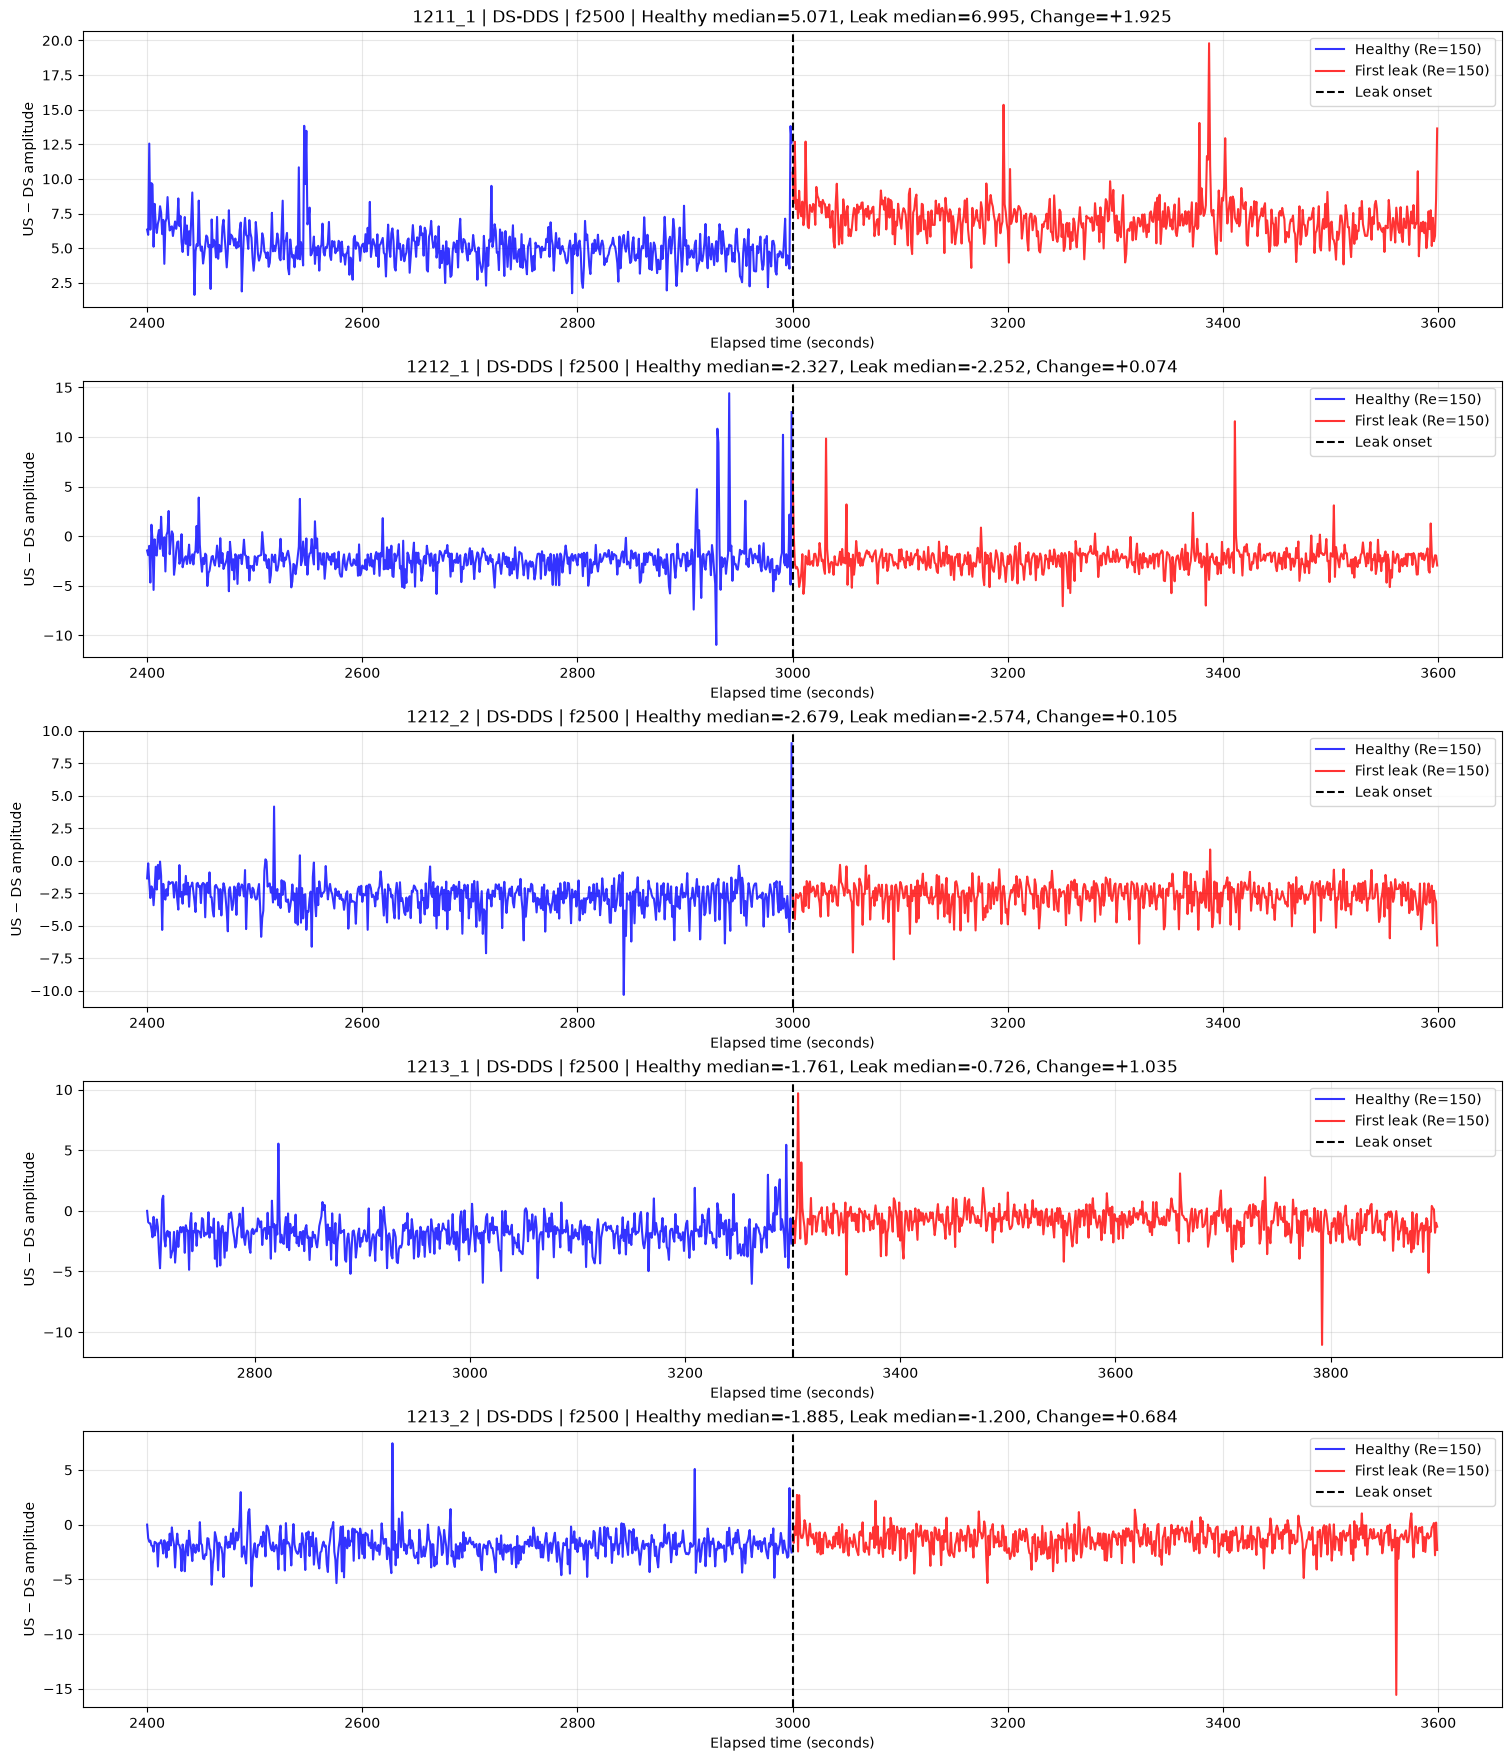

In [40]:
import matplotlib.pyplot as plt
import pandas as pd

runs = ['1211_1', '1212_1', '1212_2', '1213_1', '1213_2']
segment = 'DS-DDS'
frequency = 'f2500'#'f63'
value_col = f'upstream_minus_downstream__{frequency}'

fig, axes = plt.subplots(
    len(runs), 1,
    figsize=(15, 3.5 * len(runs)),
    constrained_layout=True
)

for ax, run in zip(axes, runs):

    # Full experiment timeline: identify the first leak
    run_data = df.loc[df['run_id'] == run].sort_values('Date-Time')

    leak_times = run_data.loc[
        run_data['leak_active'], 'Date-Time'
    ]

    if leak_times.empty:
        ax.set_title(f'{run}: No leak found')
        continue

    first_leak_start = leak_times.min()

    # Find the end of the FIRST leak, excluding later leak events
    status = run_data.groupby('Date-Time')['leak_active'].any()

    later_healthy = status.loc[
        (status.index > first_leak_start) & (~status)
    ]

    first_leak_end = (
        later_healthy.index.min()
        if not later_healthy.empty else None
    )

    # US-DS, Reynolds = 150
    d = run_data.loc[
        (run_data['segment_id'] == segment) &
        (run_data['Reynolds_level'] == 150)
    ].sort_values('Date-Time')

    healthy = d.loc[
        (d['Date-Time'] < first_leak_start) &
        (~d['leak_active'])
    ]

    leak = d.loc[
        (d['Date-Time'] >= first_leak_start) &
        d['leak_active']
    ]

    if first_leak_end is not None:
        leak = leak.loc[leak['Date-Time'] < first_leak_end]

    # Plot both periods
    ax.plot(
        healthy['Date-Time'], healthy[value_col],
        label='Healthy (Re=150)', color='blue', alpha=0.8
    )

    ax.plot(
        leak['Date-Time'], leak[value_col],
        label='First leak (Re=150)', color='red', alpha=0.8
    )

    ax.axvline(
        first_leak_start, color='black',
        linestyle='--', label='Leak onset'
    )

    # Display median differences
    if not healthy.empty and not leak.empty:
        h_med = healthy[value_col].median()
        l_med = leak[value_col].median()

        ax.set_title(
            f'{run} | {segment} | {frequency} | '
            f'Healthy median={h_med:.3f}, '
            f'Leak median={l_med:.3f}, '
            f'Change={l_med-h_med:+.3f}'
        )
    else:
        ax.set_title(f'{run} | {segment} | {frequency}')

    ax.set_xlabel('Elapsed time (seconds)')
    ax.set_ylabel('US − DS amplitude')
    ax.legend()
    ax.grid(alpha=0.3)

plt.show()

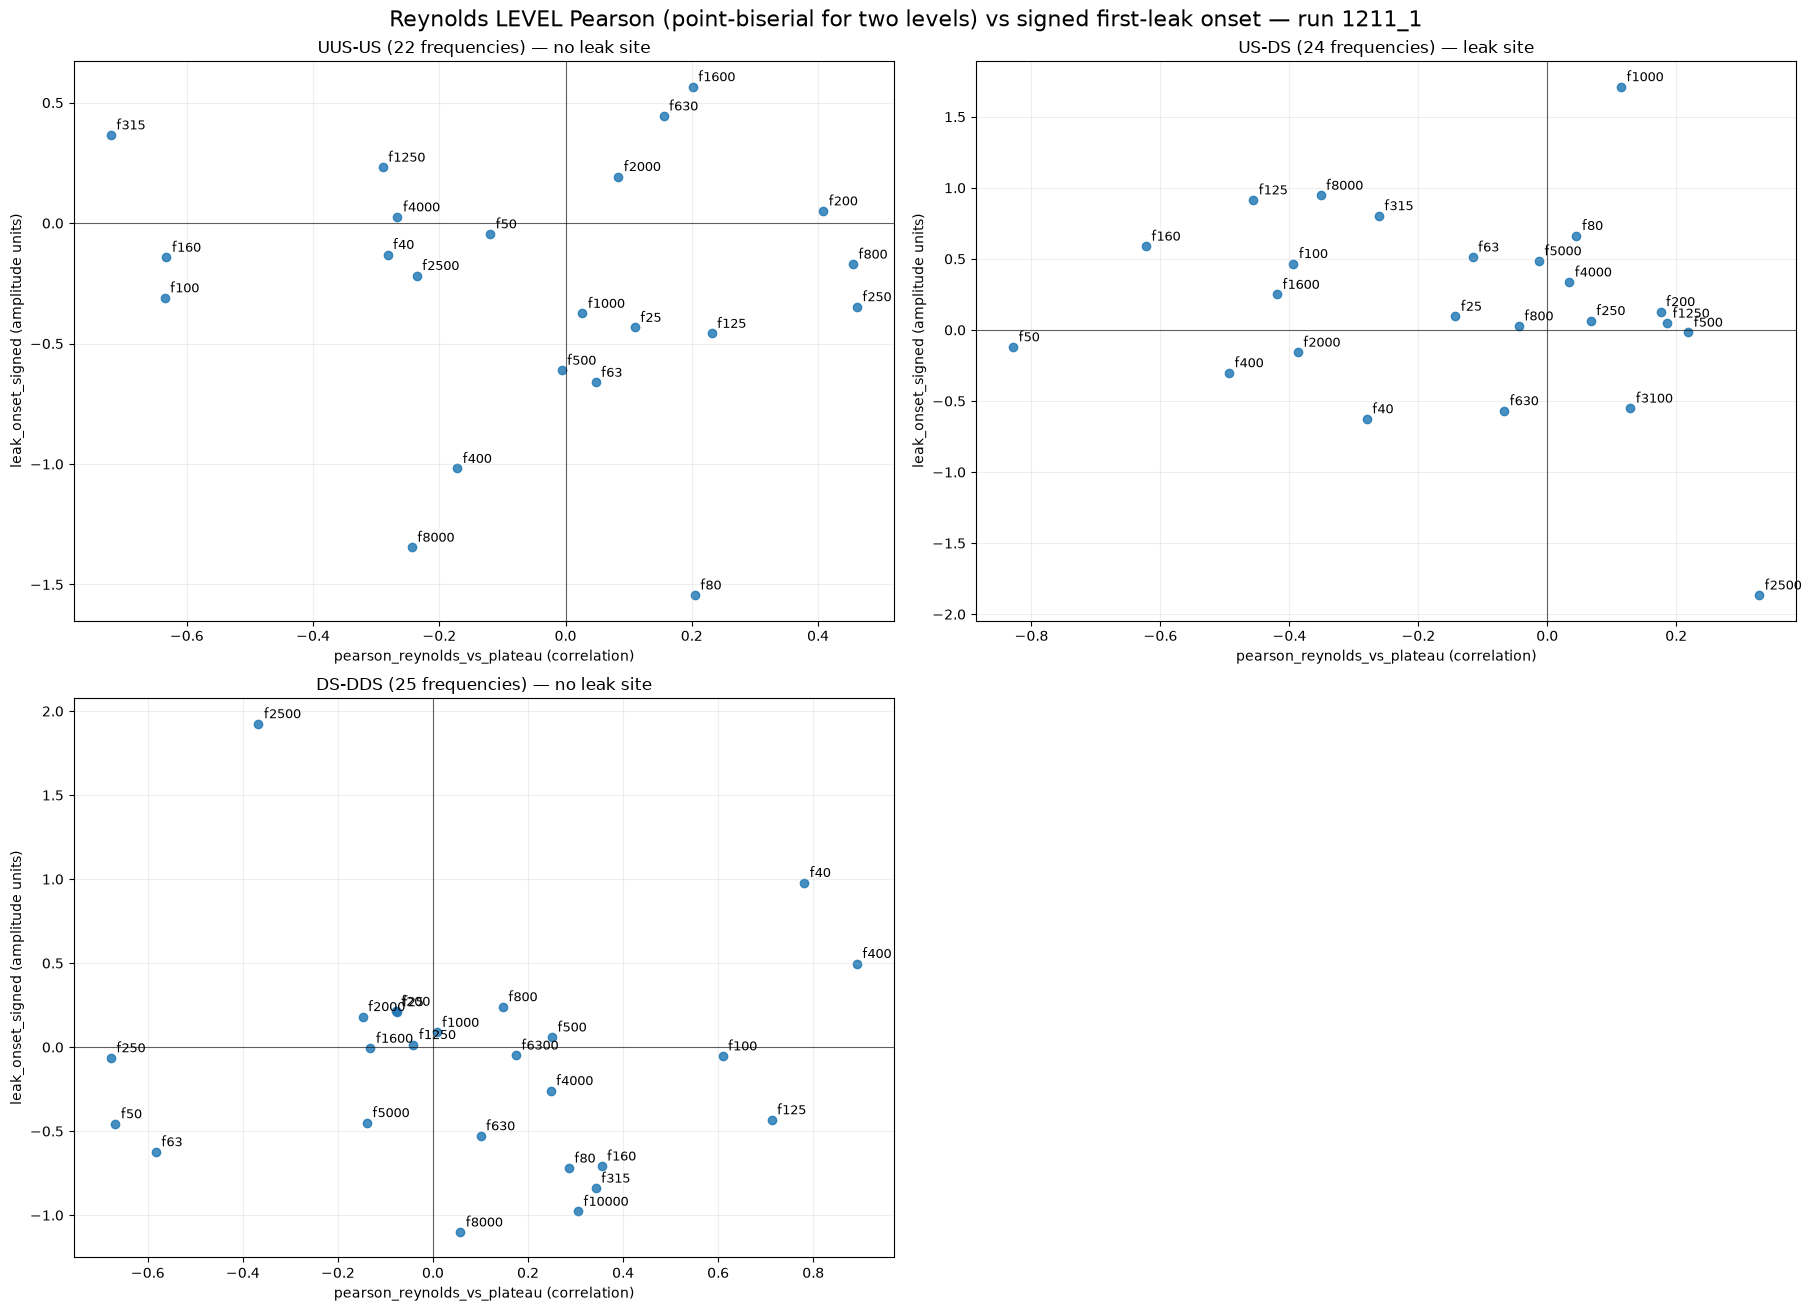

1211_1: level_pearson_vs_signed_leak_onset → 71 frequency points


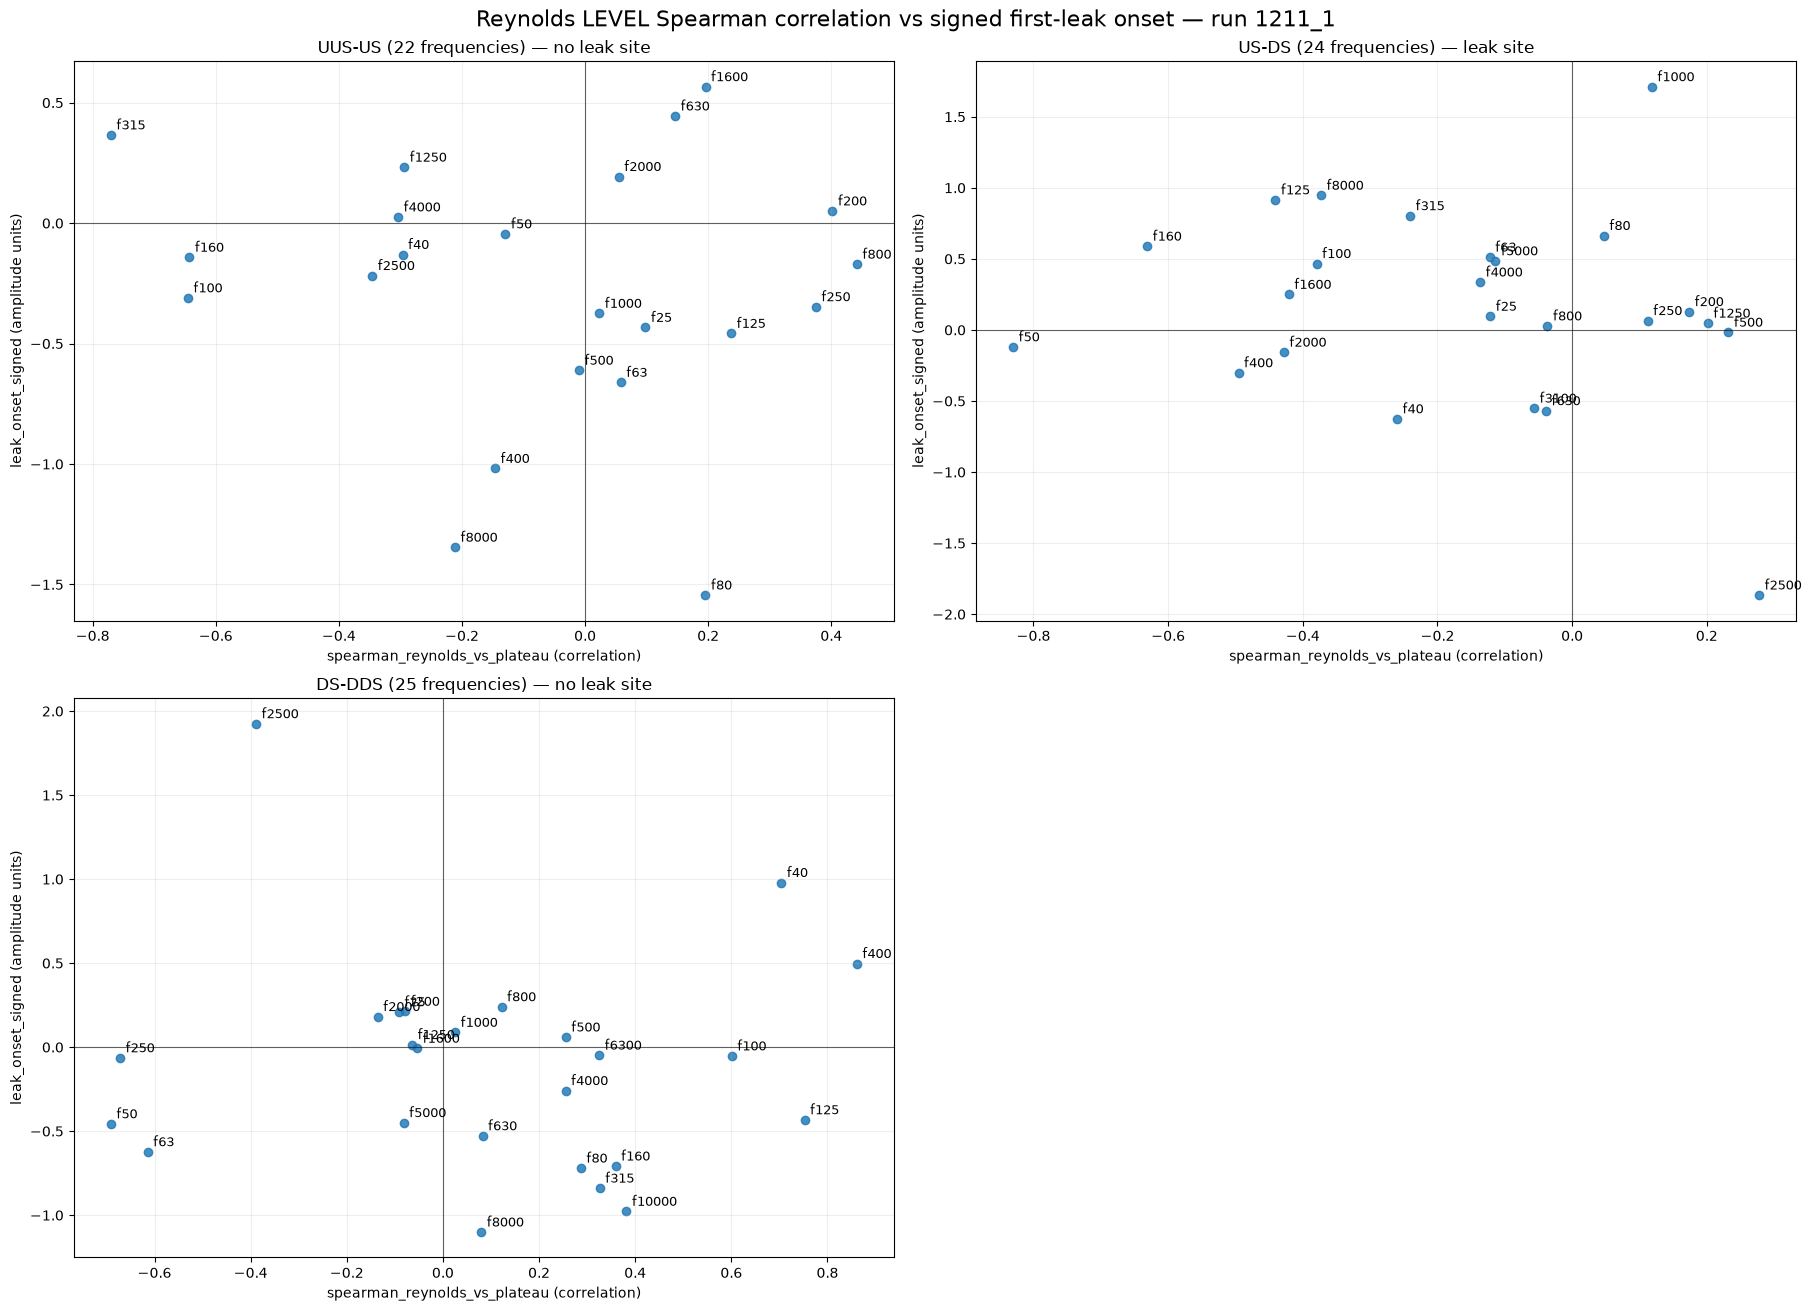

1211_1: level_spearman_vs_signed_leak_onset → 71 frequency points


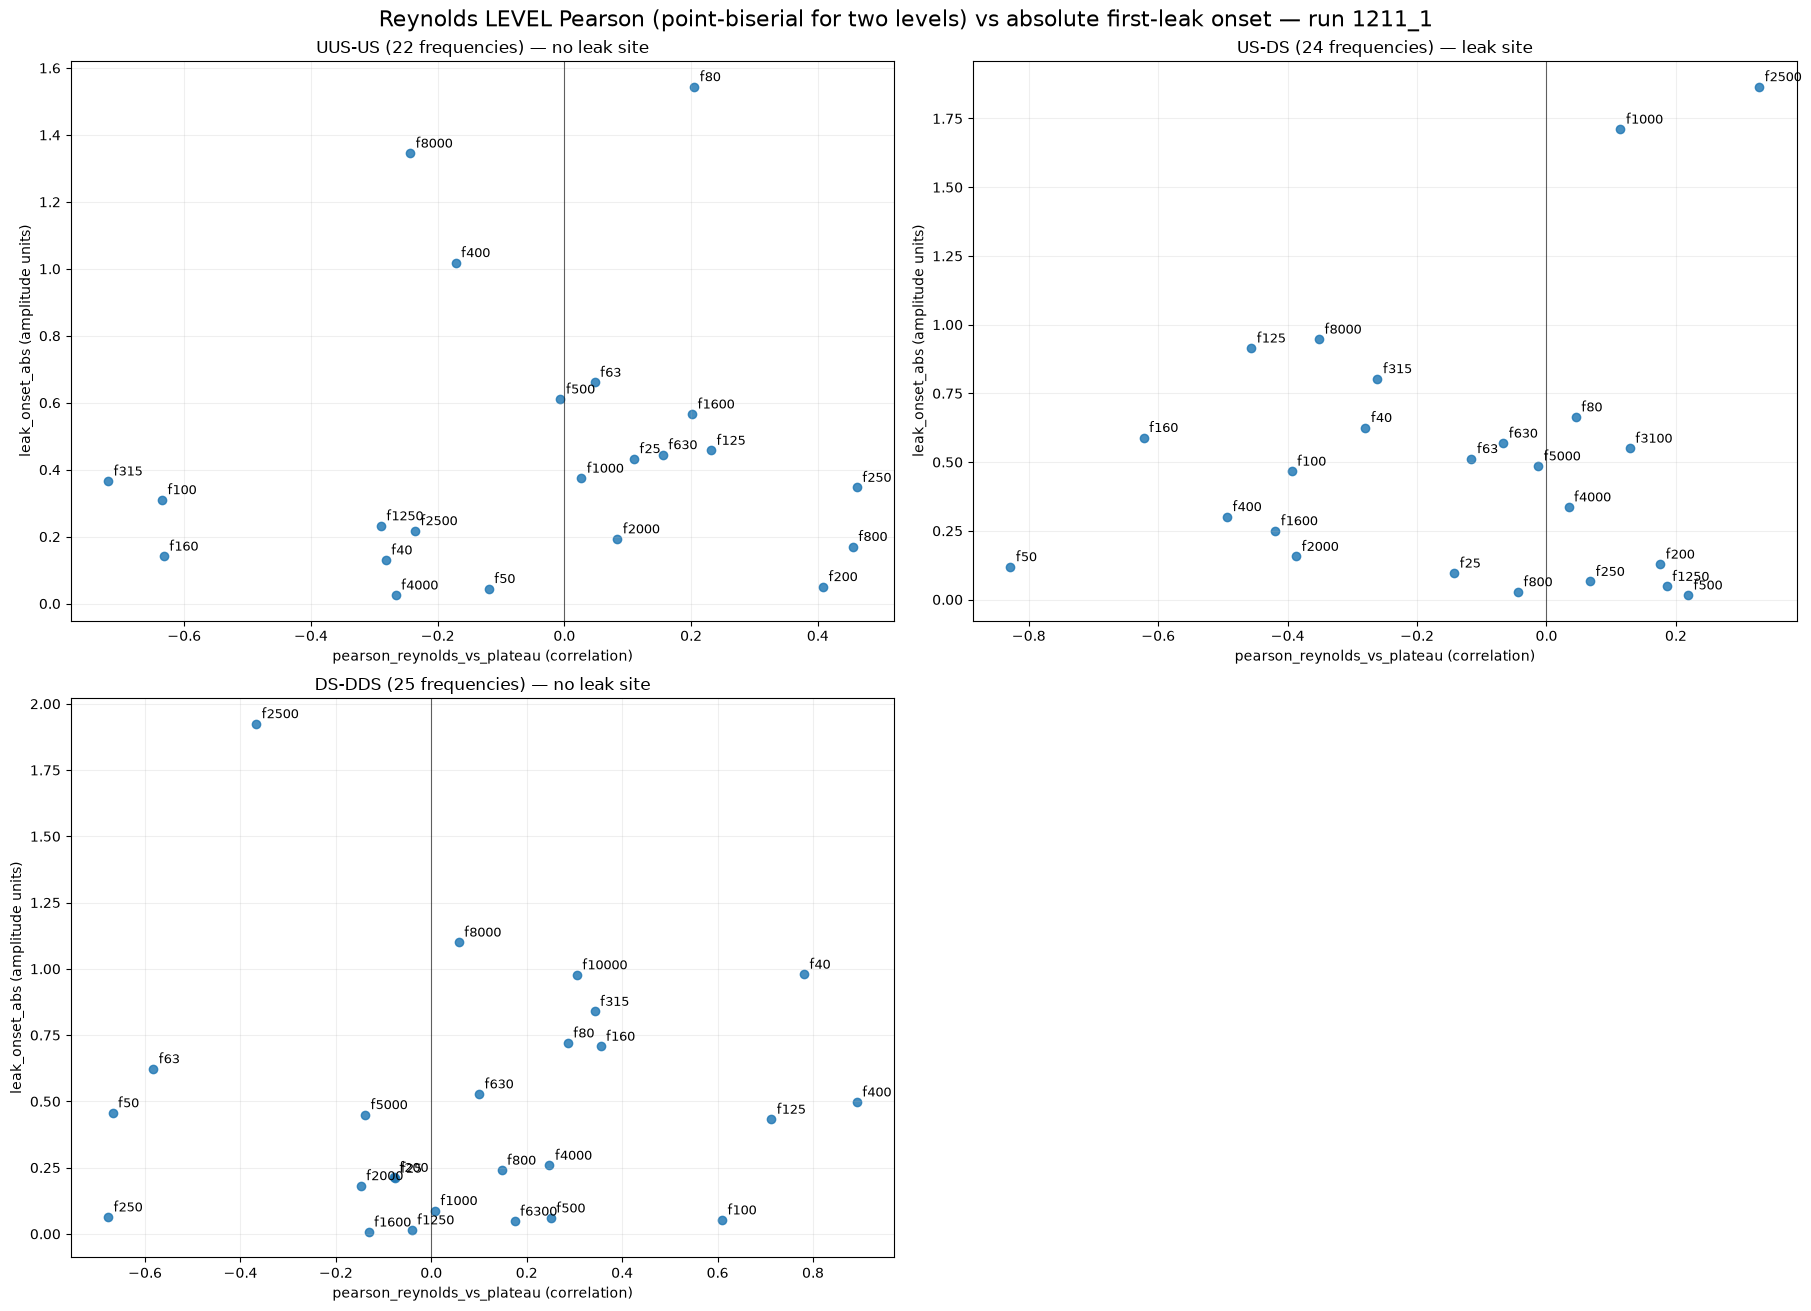

1211_1: level_pearson_vs_absolute_leak_onset → 71 frequency points


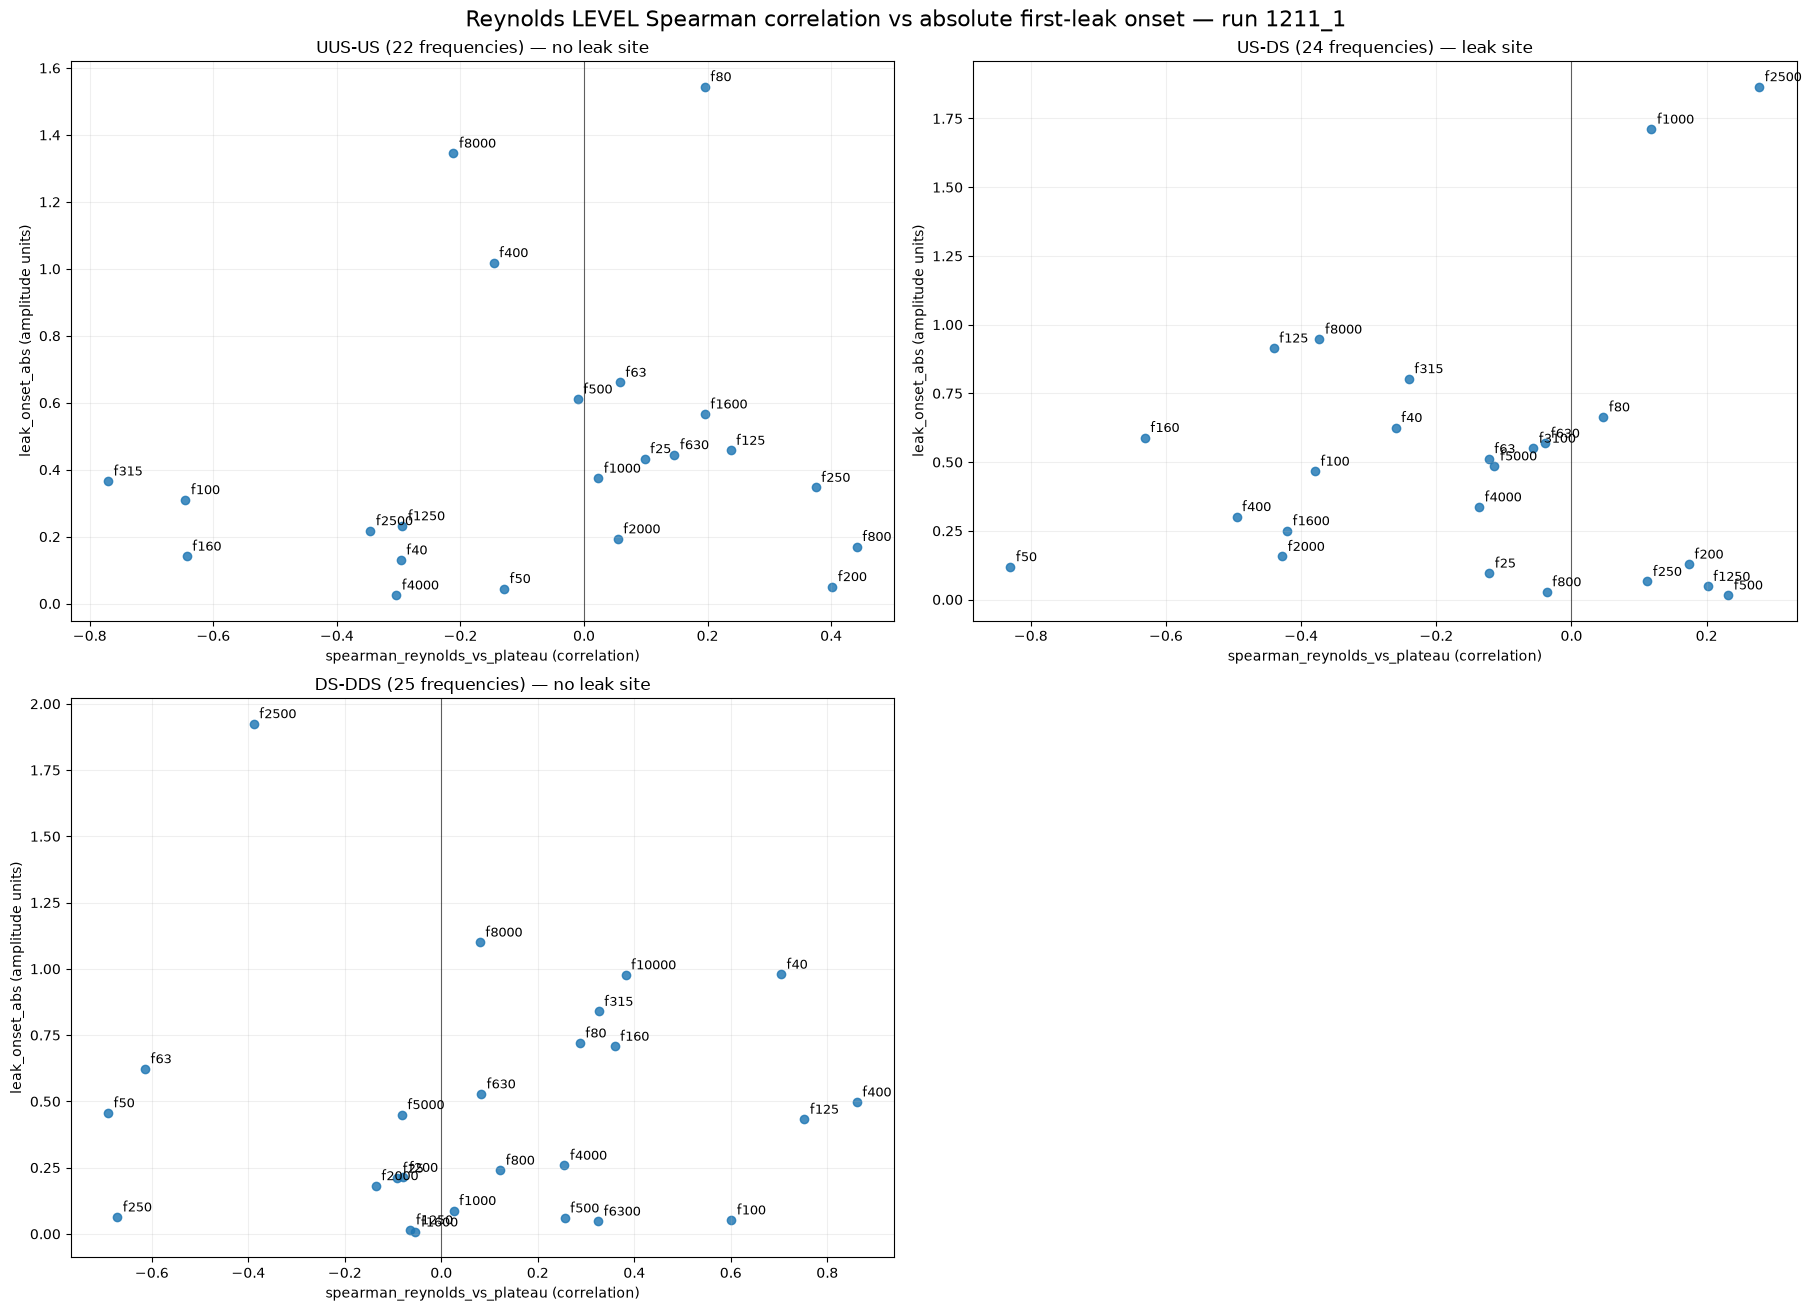

1211_1: level_spearman_vs_absolute_leak_onset → 71 frequency points


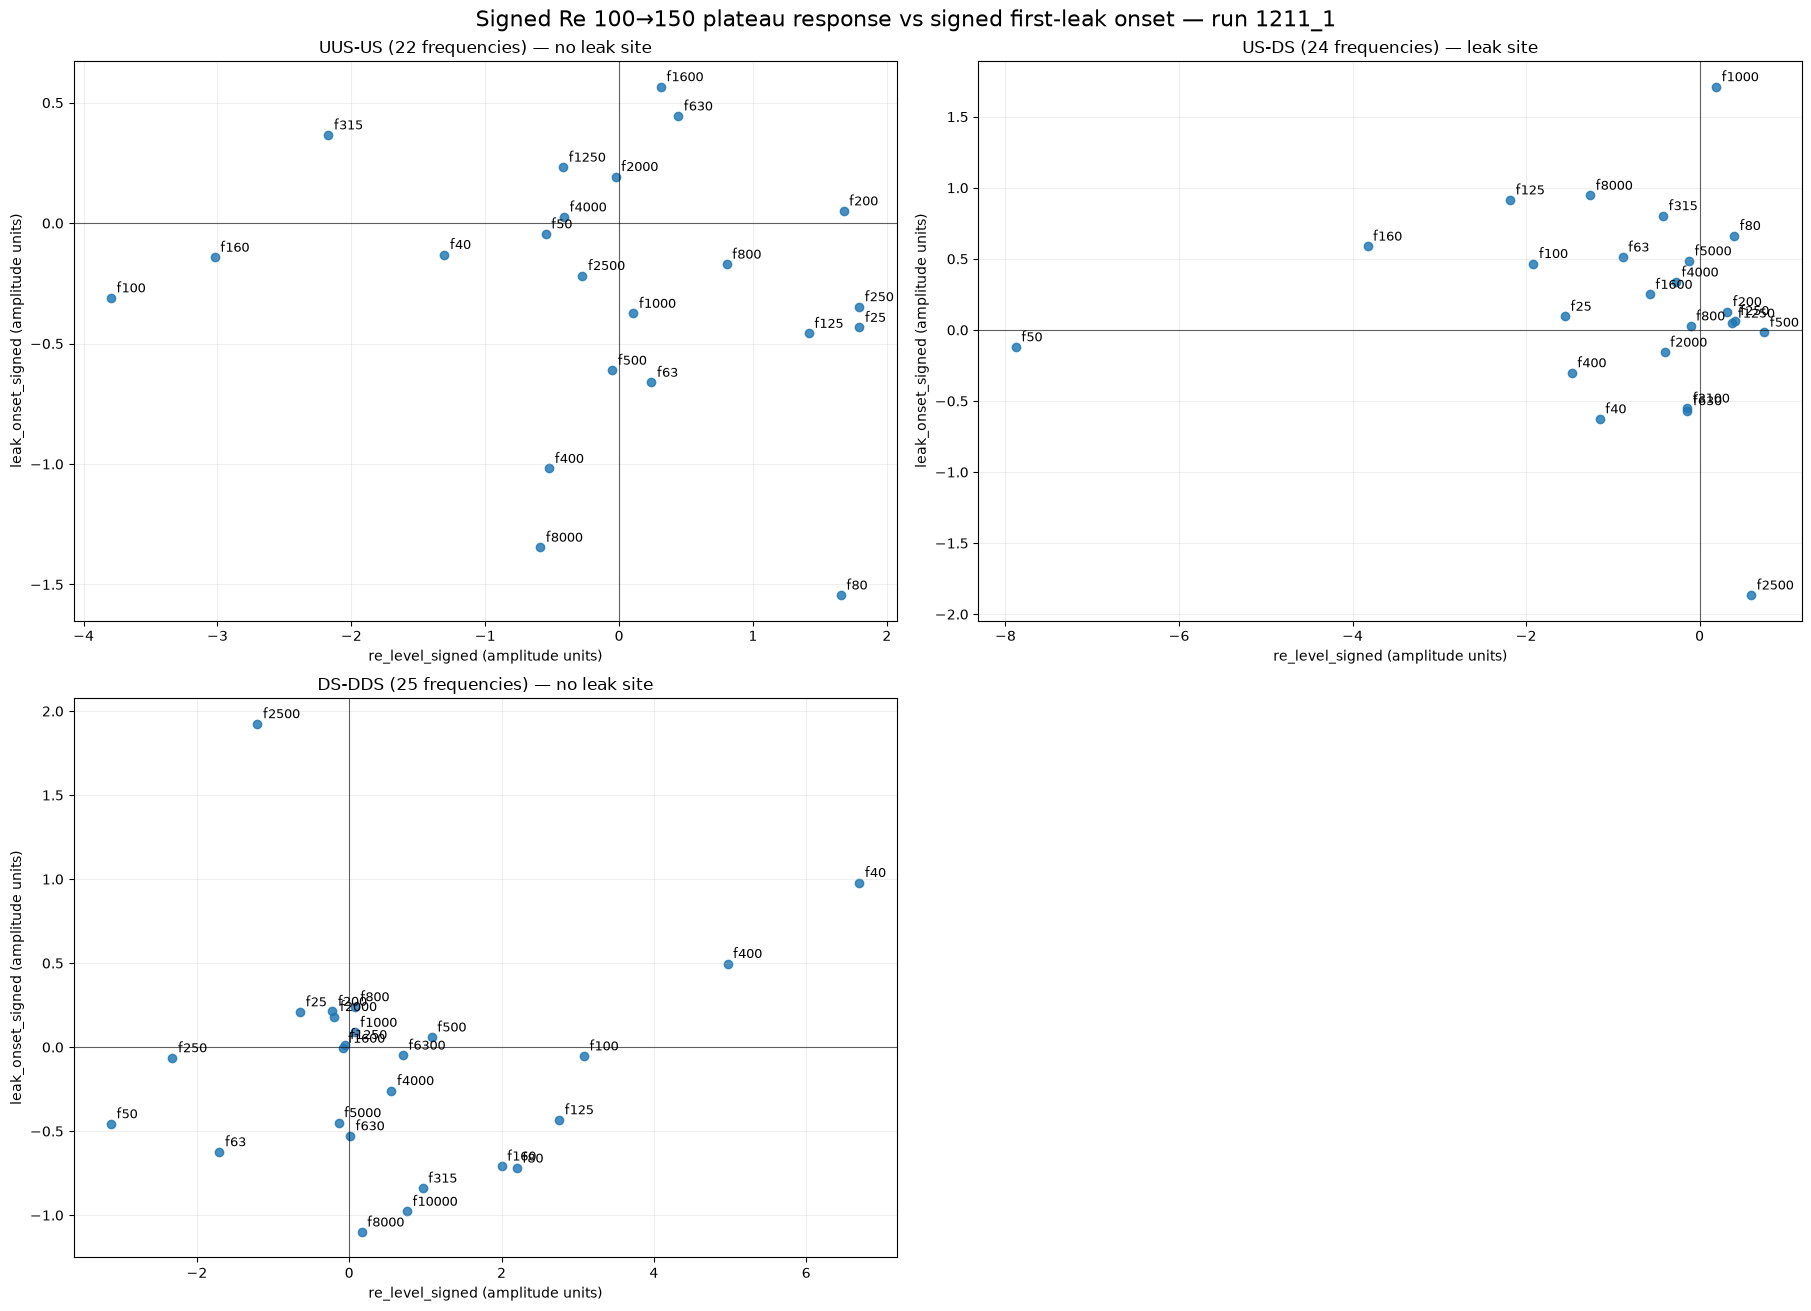

1211_1: signed_re100to150_vs_signed_leak_onset → 71 frequency points


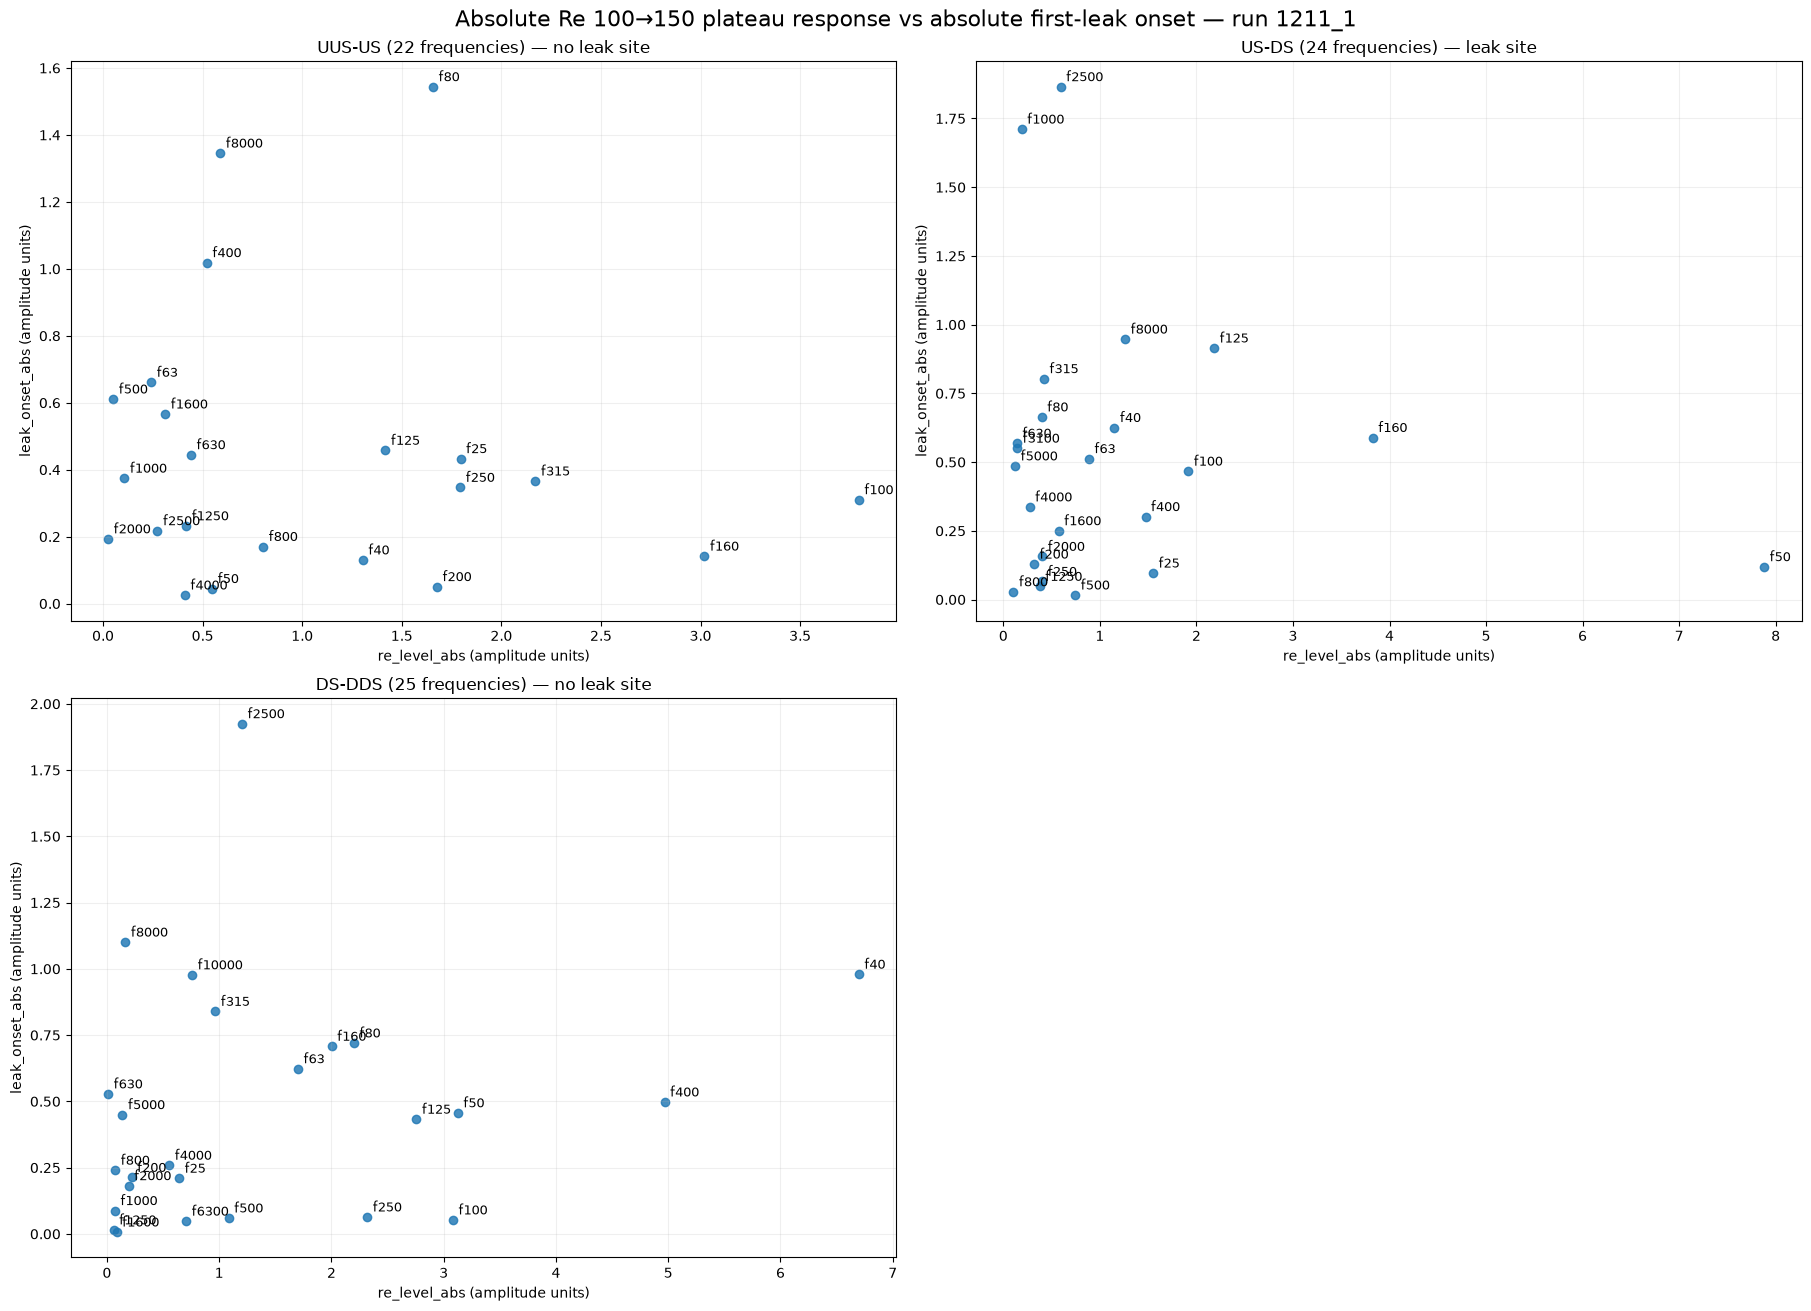

1211_1: absolute_re100to150_vs_absolute_leak_onset → 71 frequency points


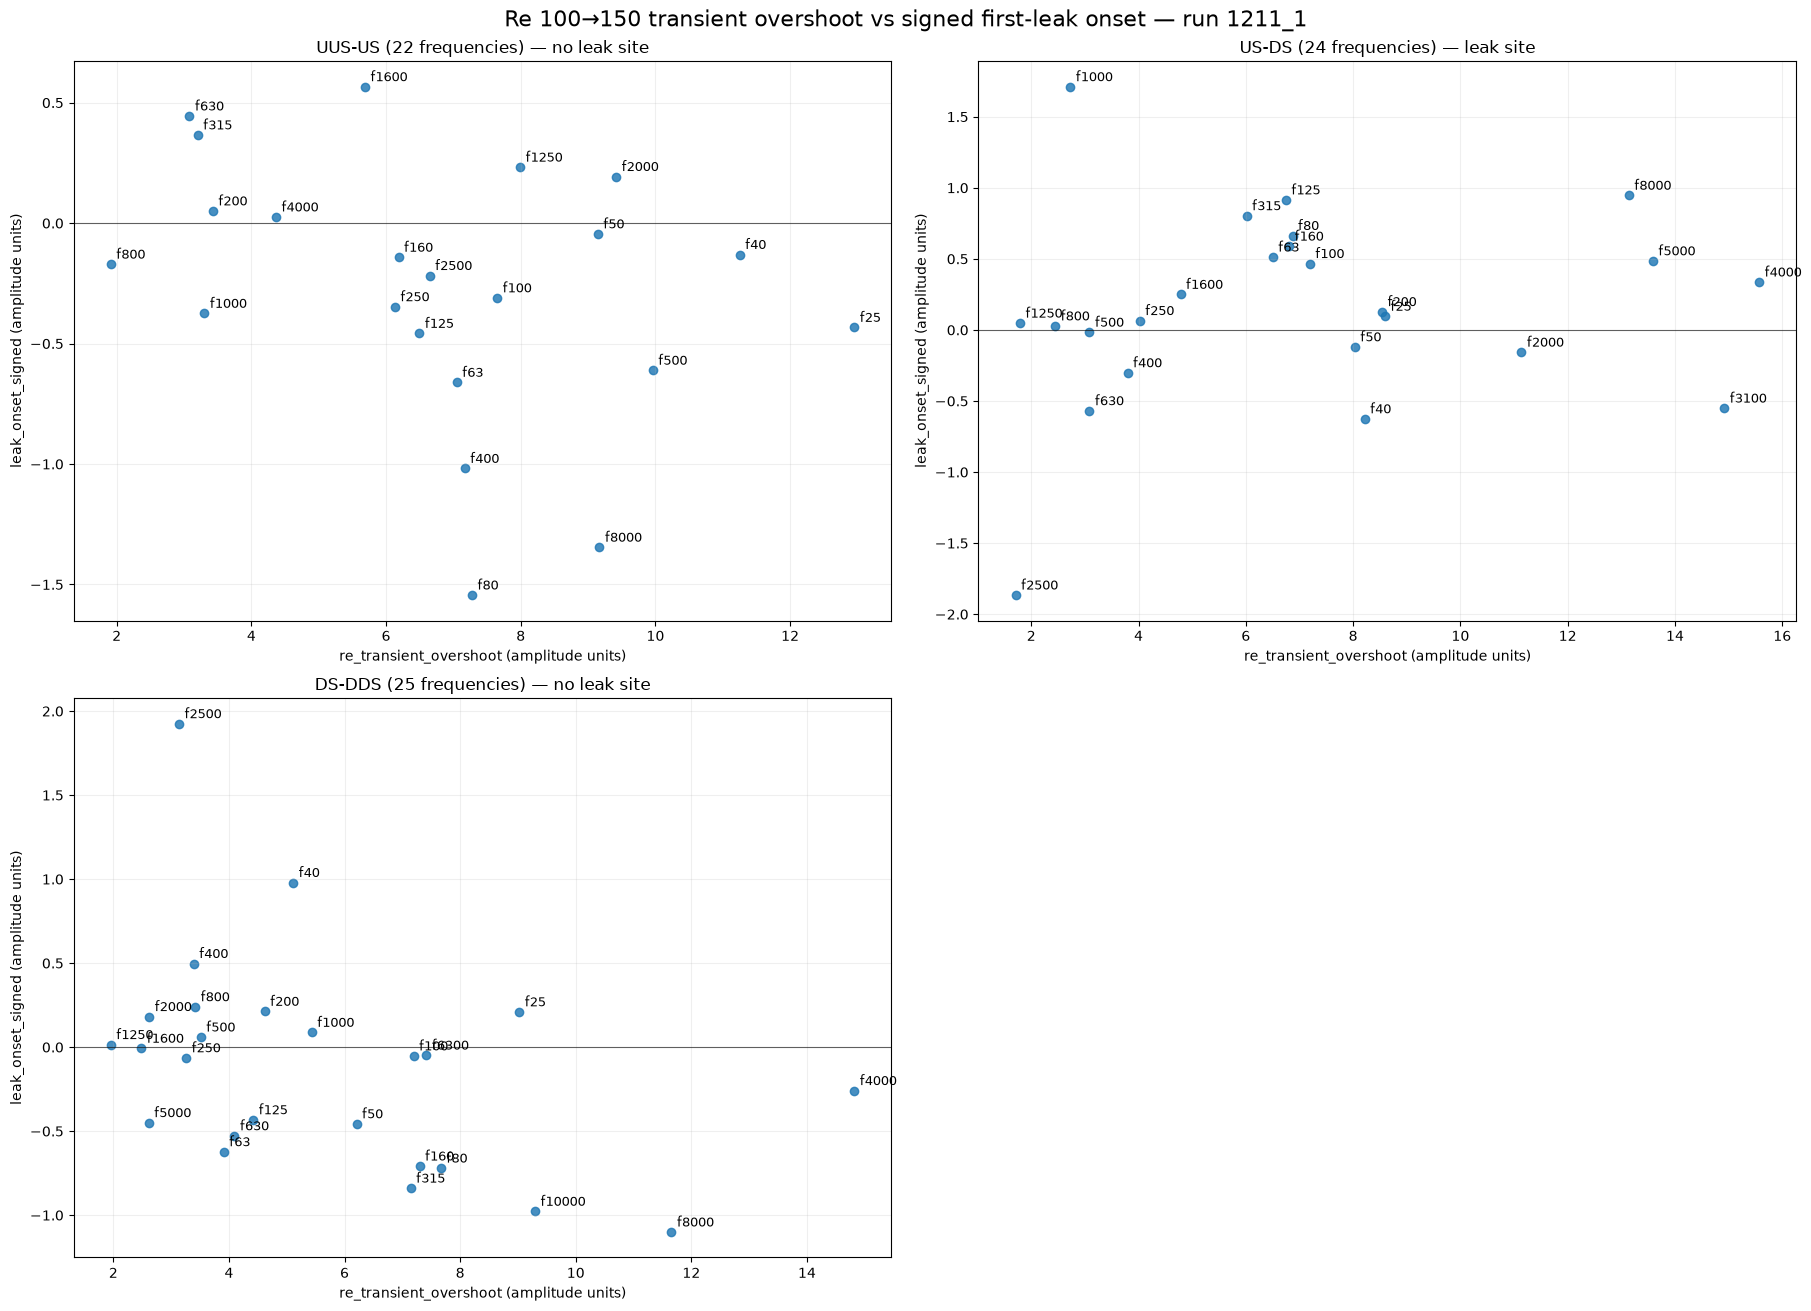

1211_1: overshoot_re100to150_vs_signed_leak_onset → 71 frequency points


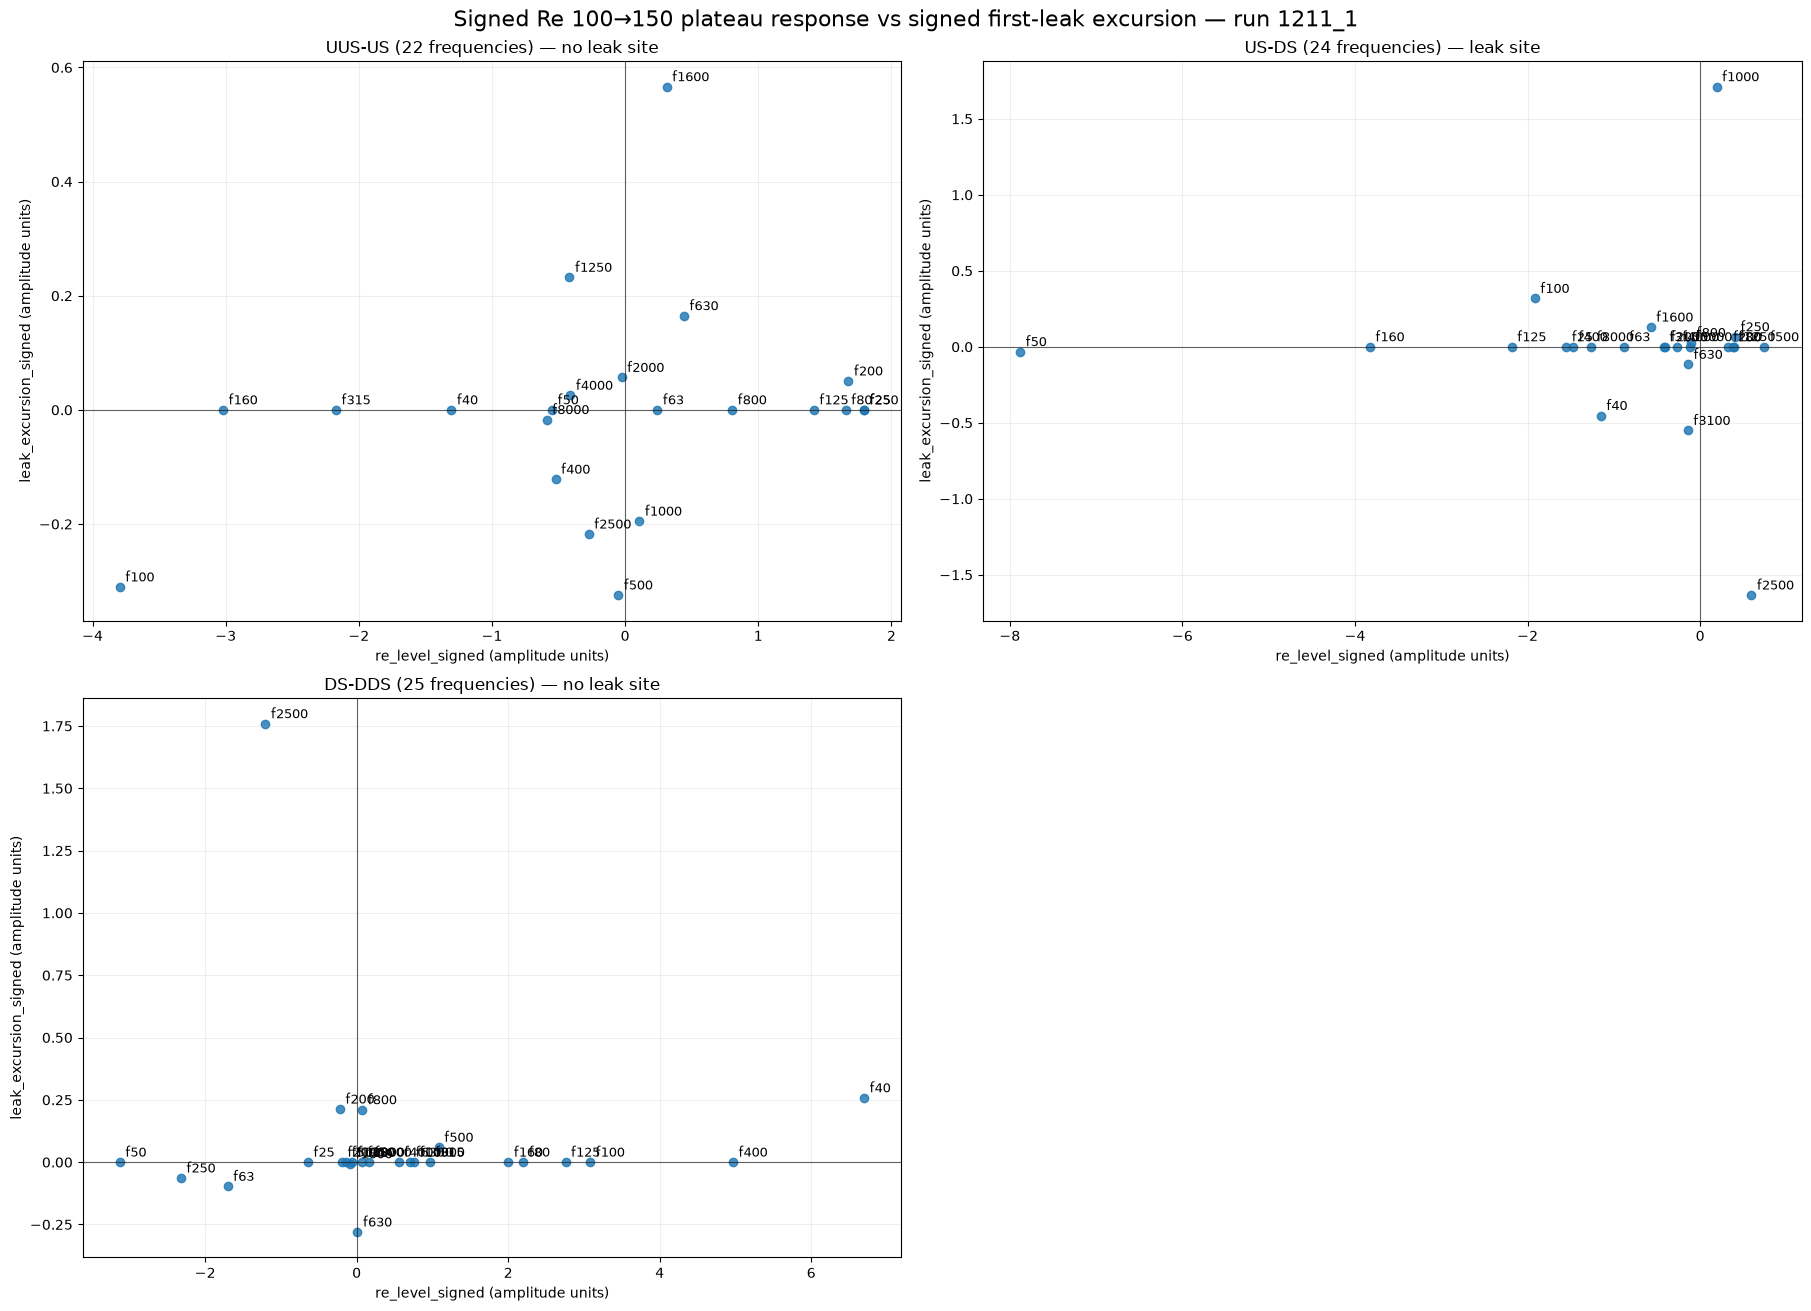

1211_1: signed_re100to150_vs_signed_leak_excursion → 71 frequency points


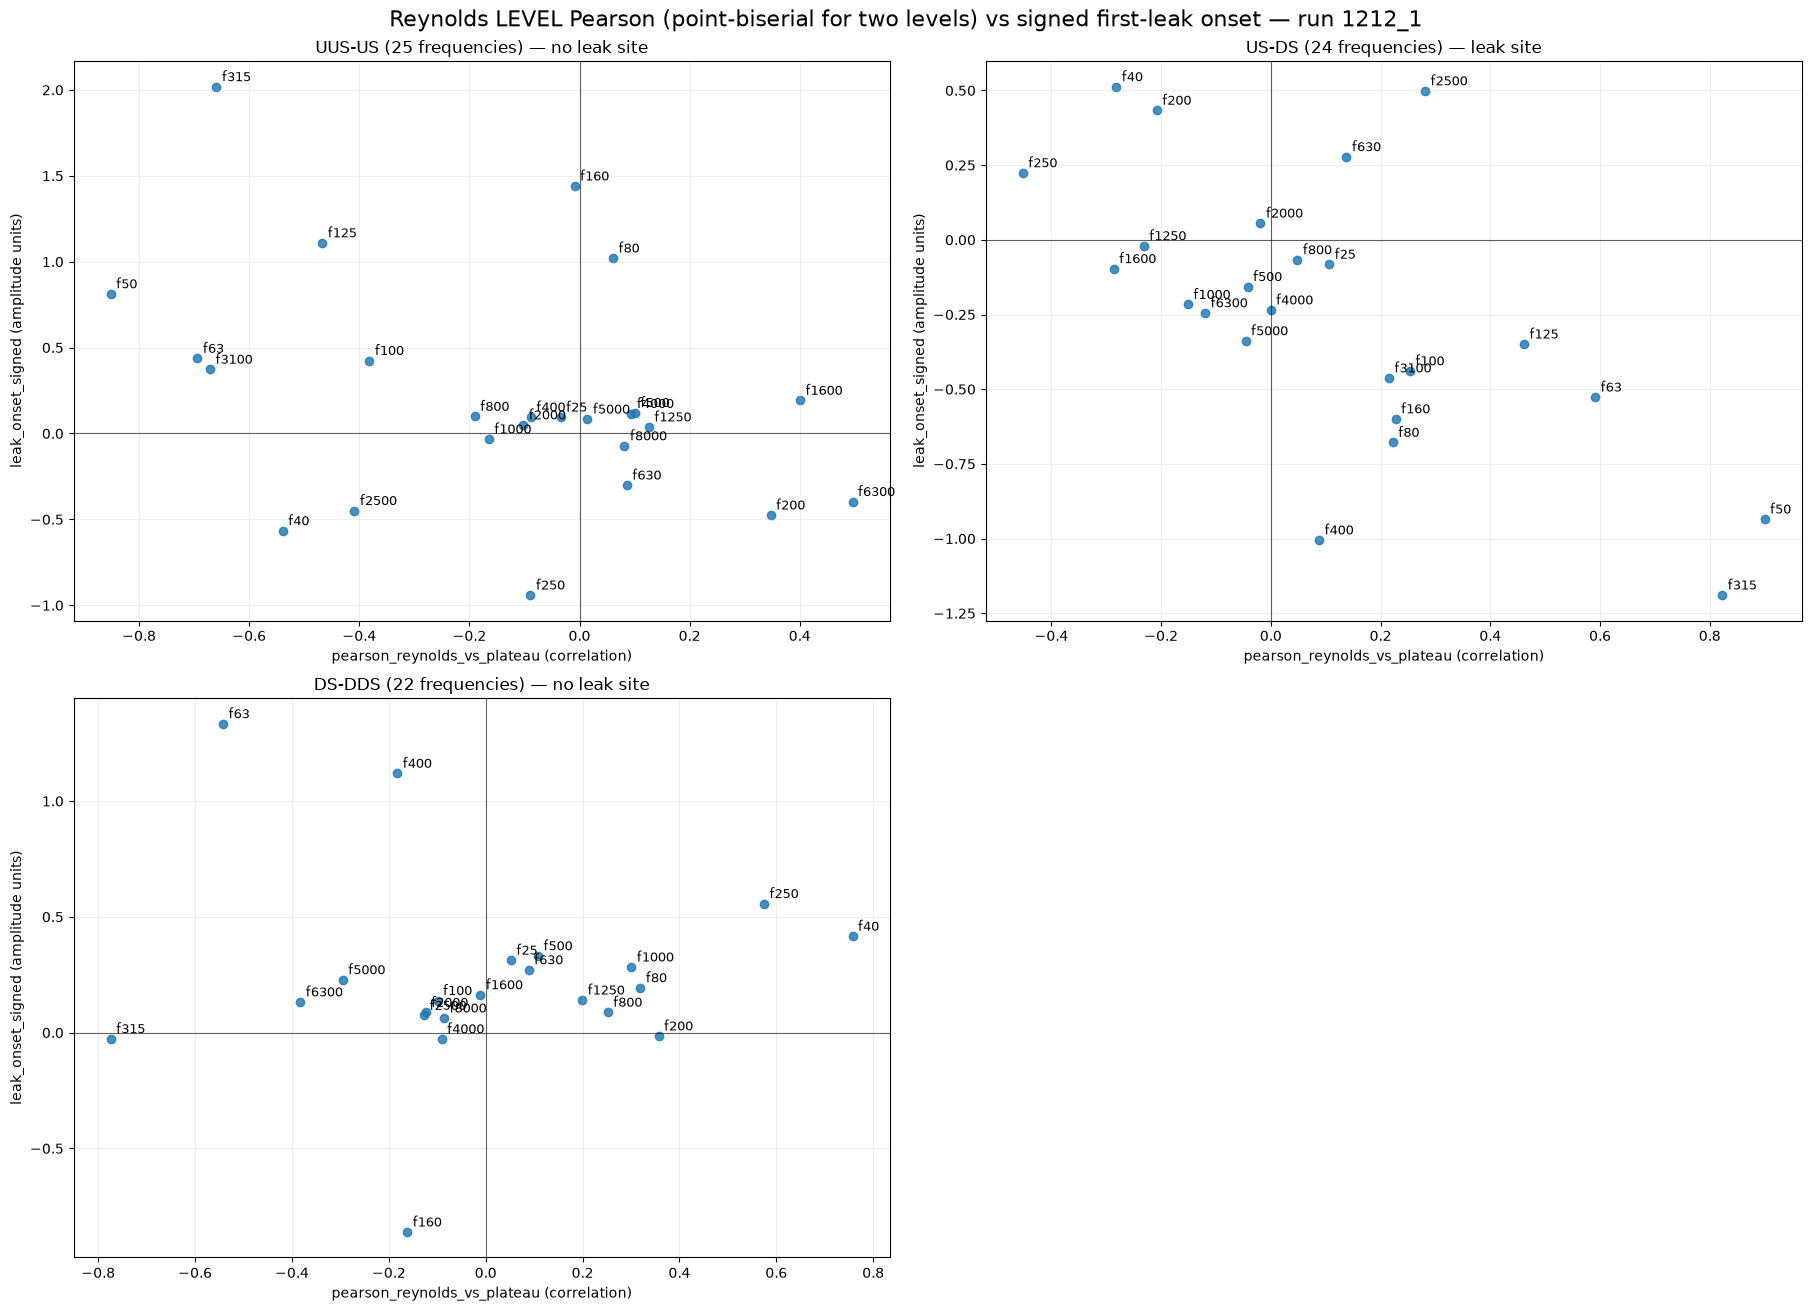

1212_1: level_pearson_vs_signed_leak_onset → 71 frequency points


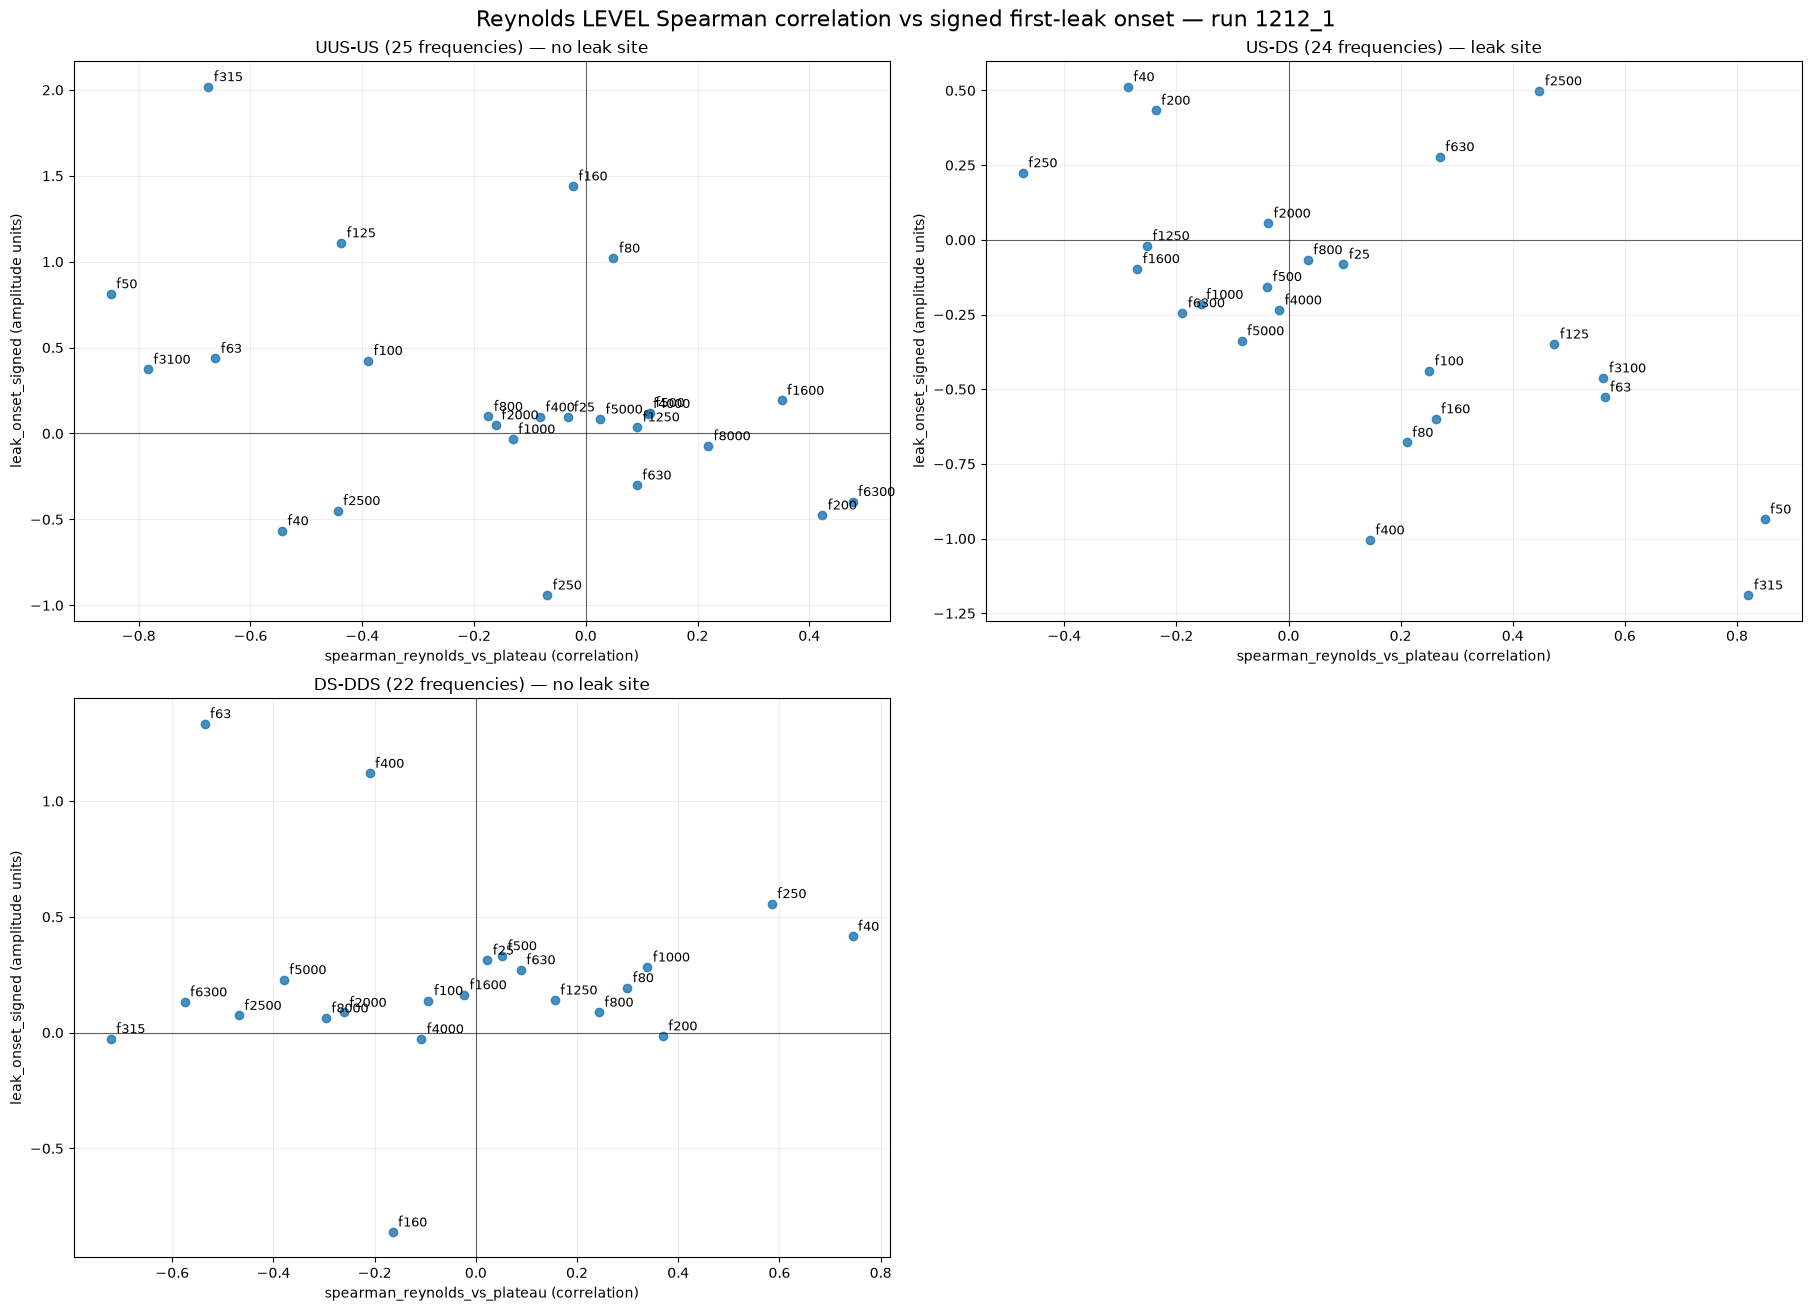

1212_1: level_spearman_vs_signed_leak_onset → 71 frequency points


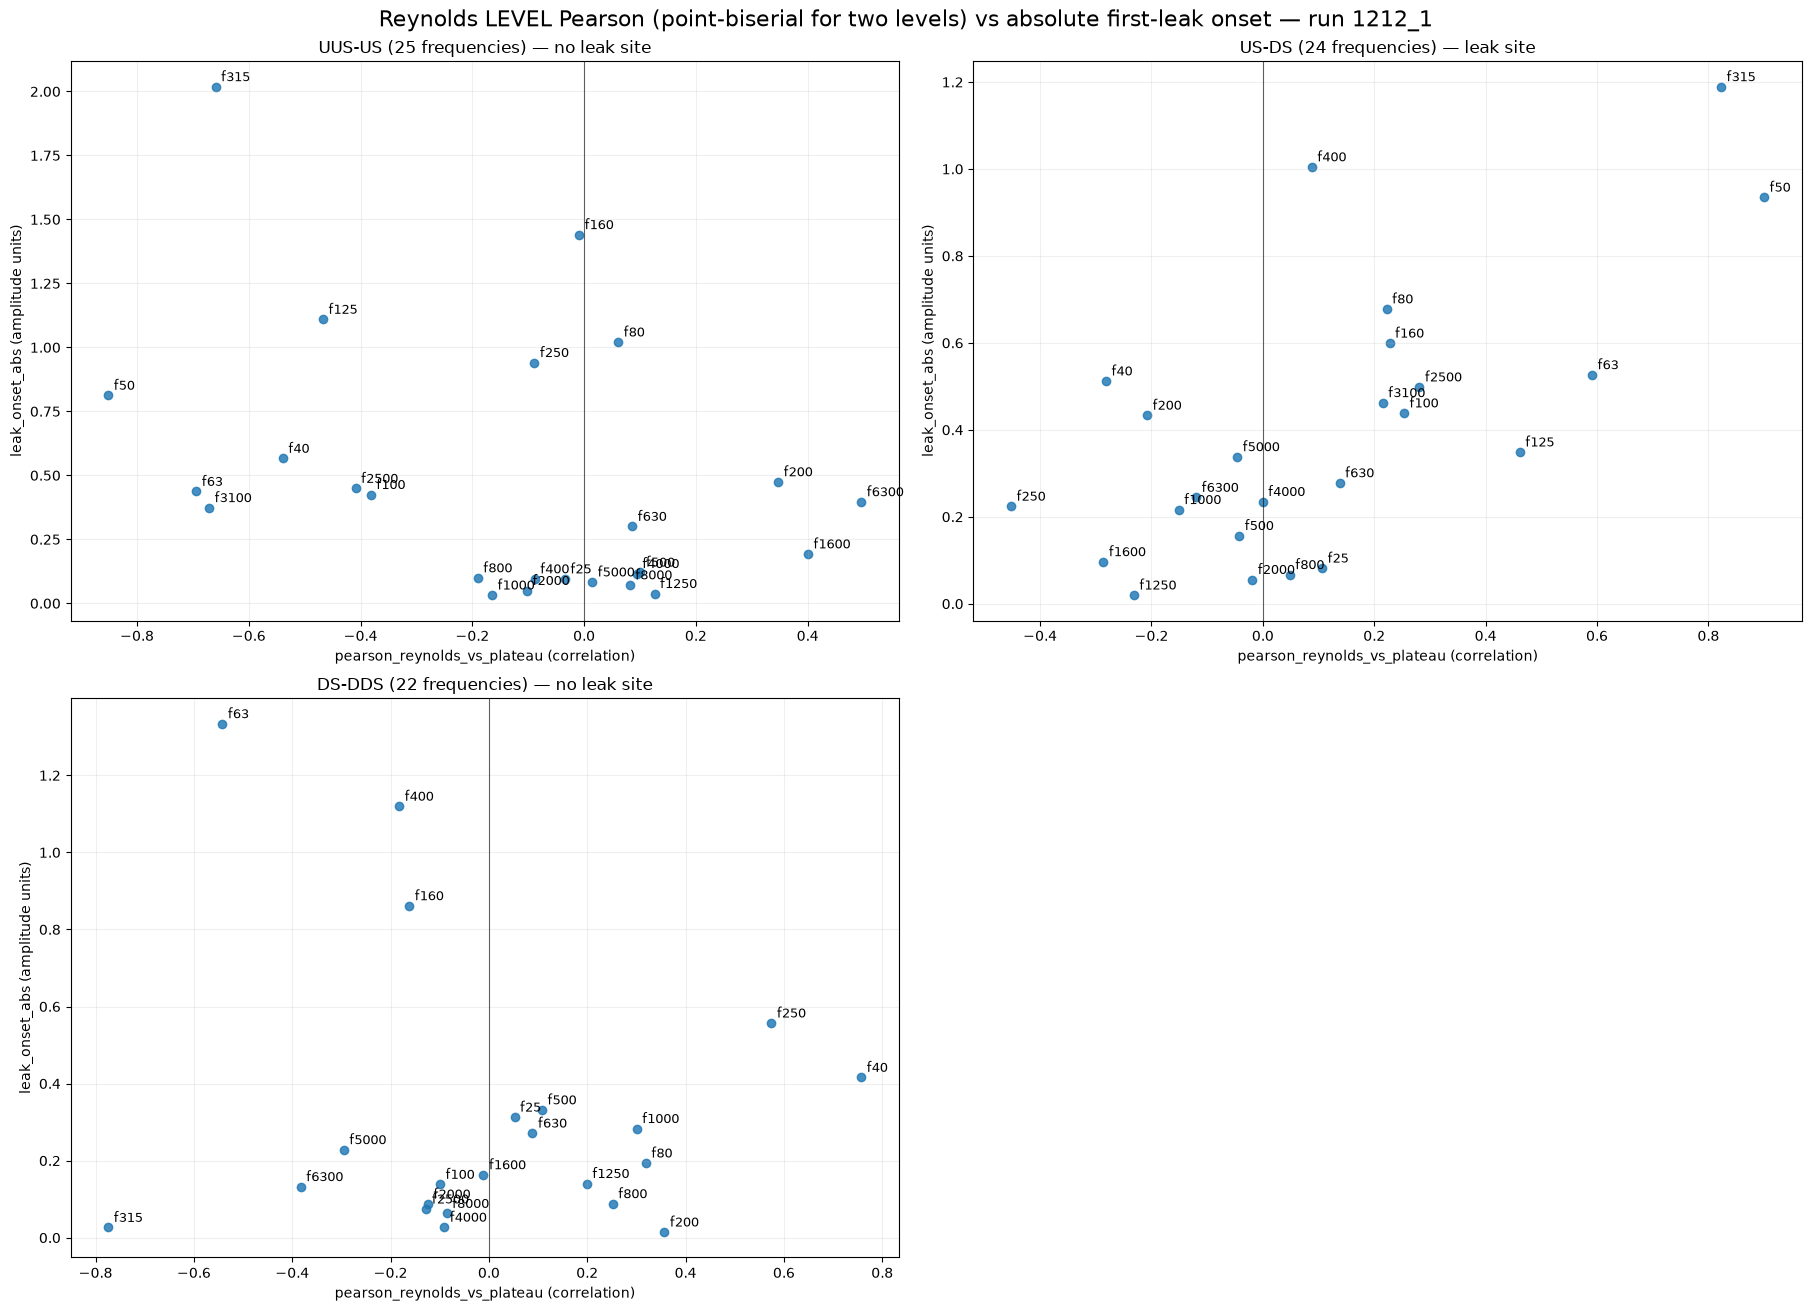

1212_1: level_pearson_vs_absolute_leak_onset → 71 frequency points


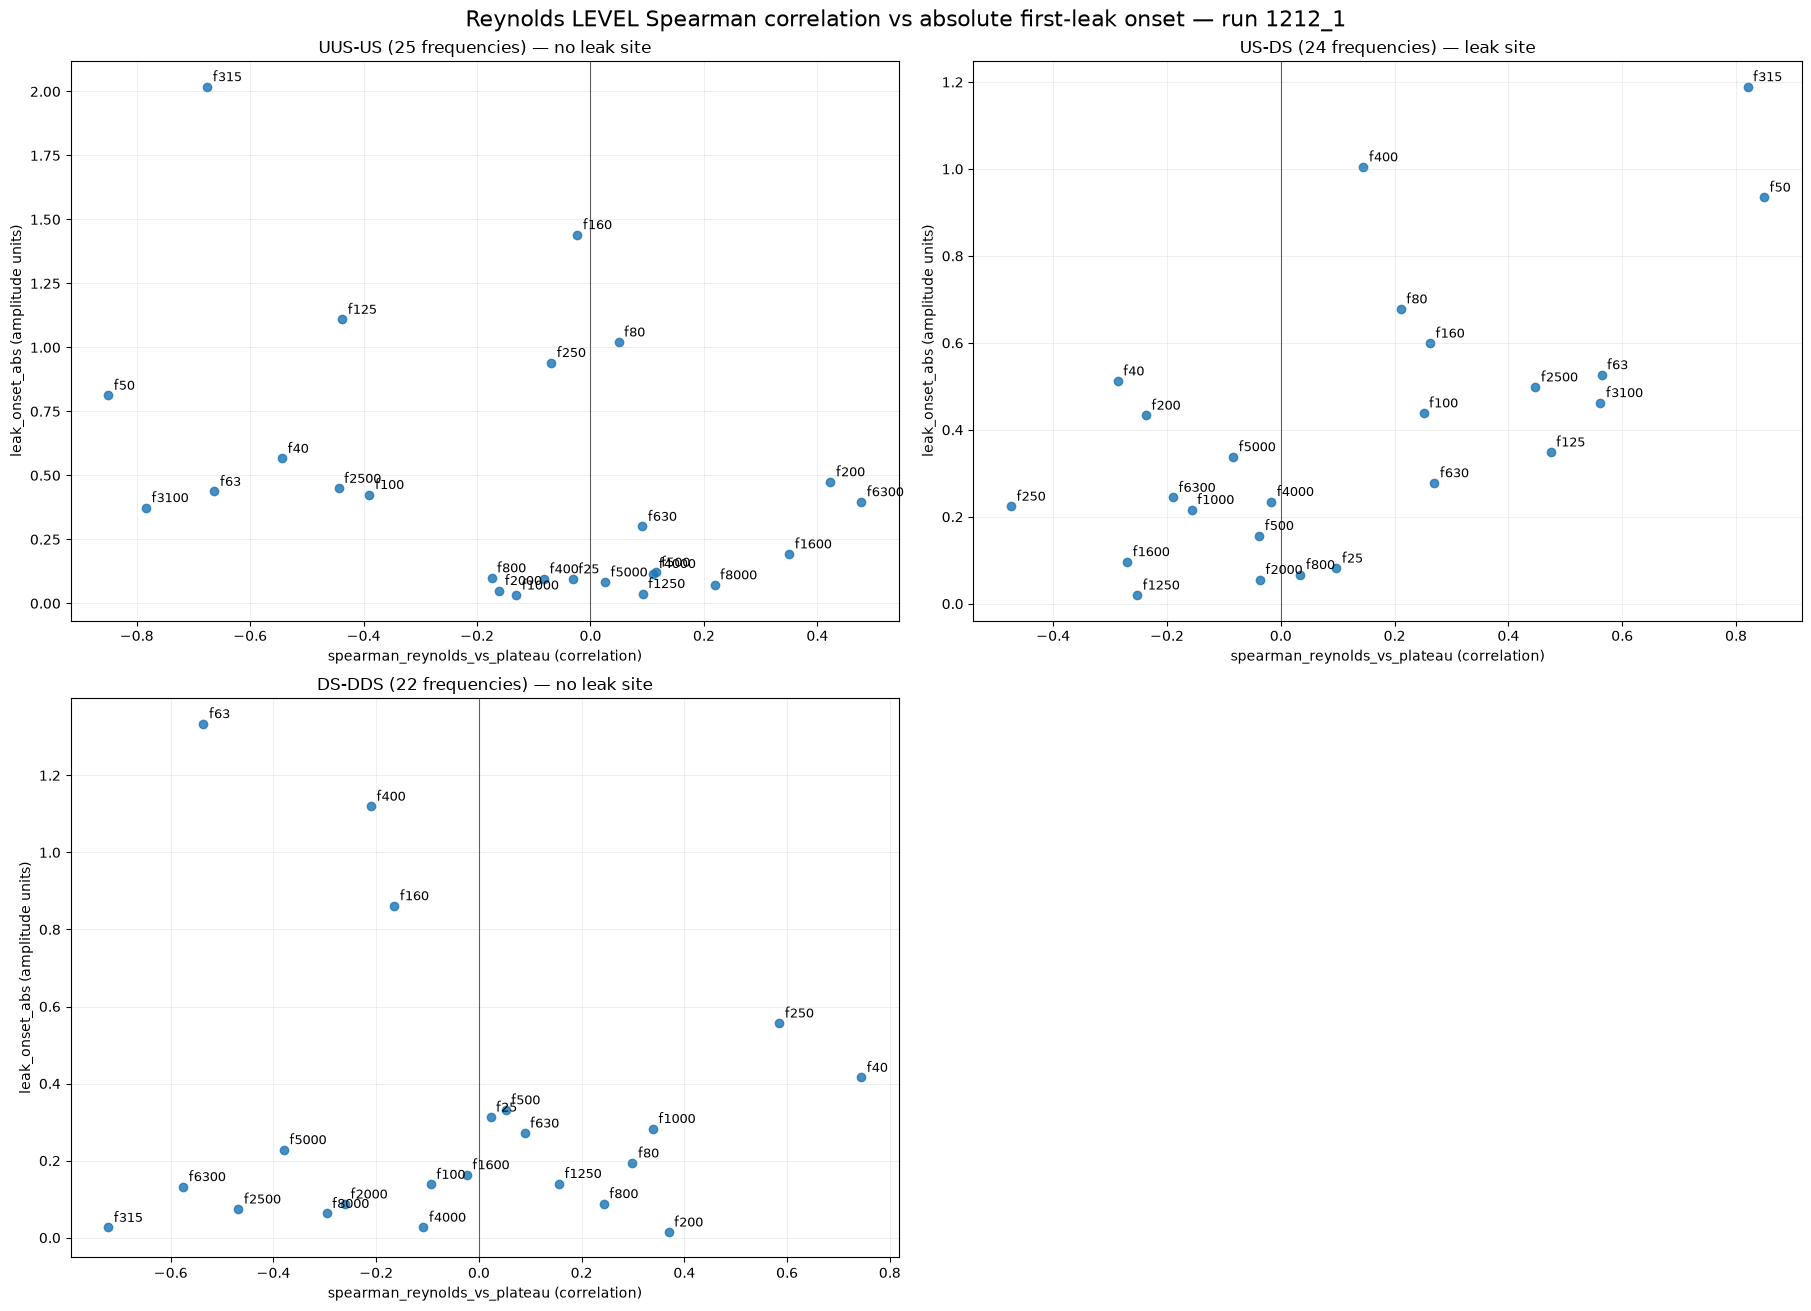

1212_1: level_spearman_vs_absolute_leak_onset → 71 frequency points


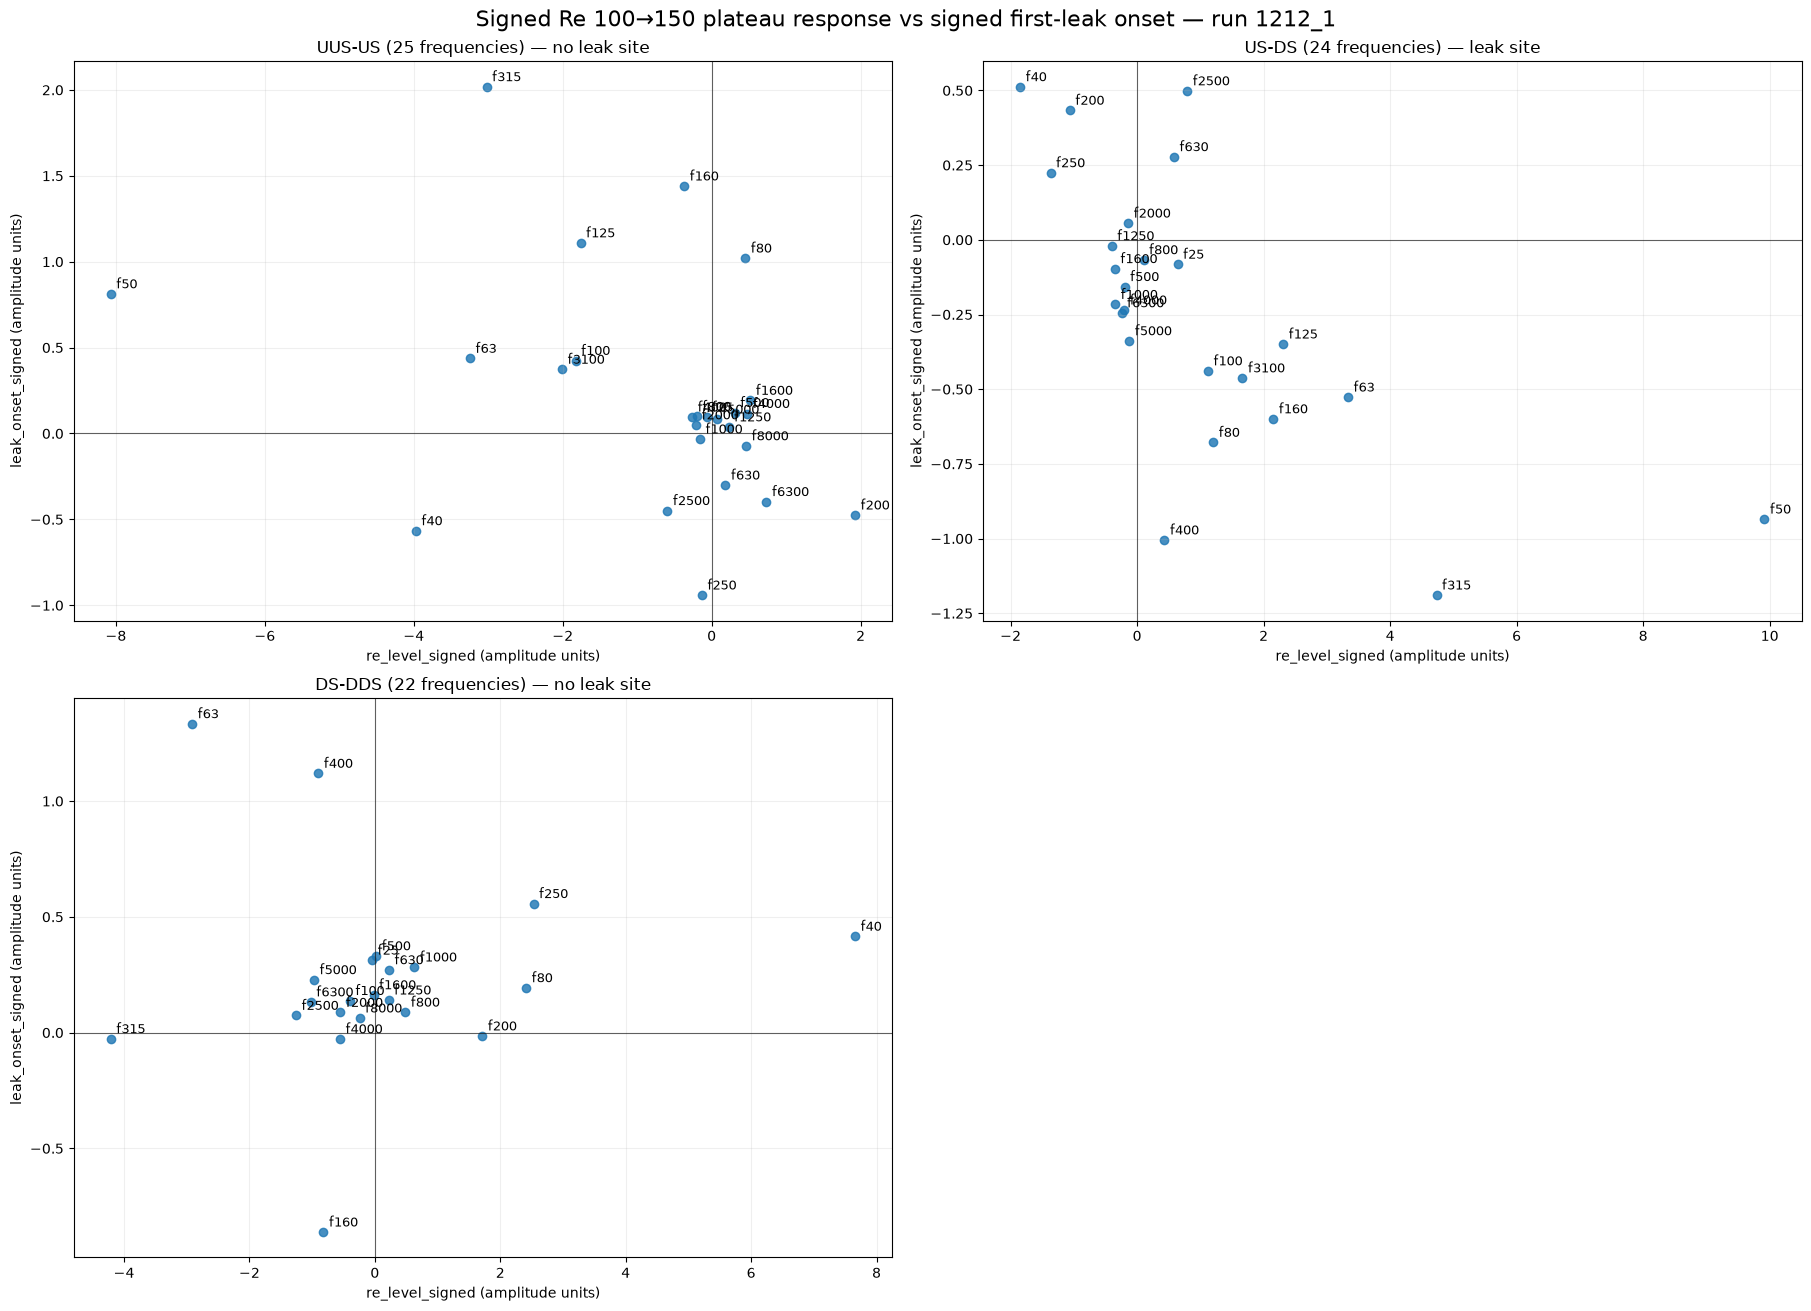

1212_1: signed_re100to150_vs_signed_leak_onset → 71 frequency points


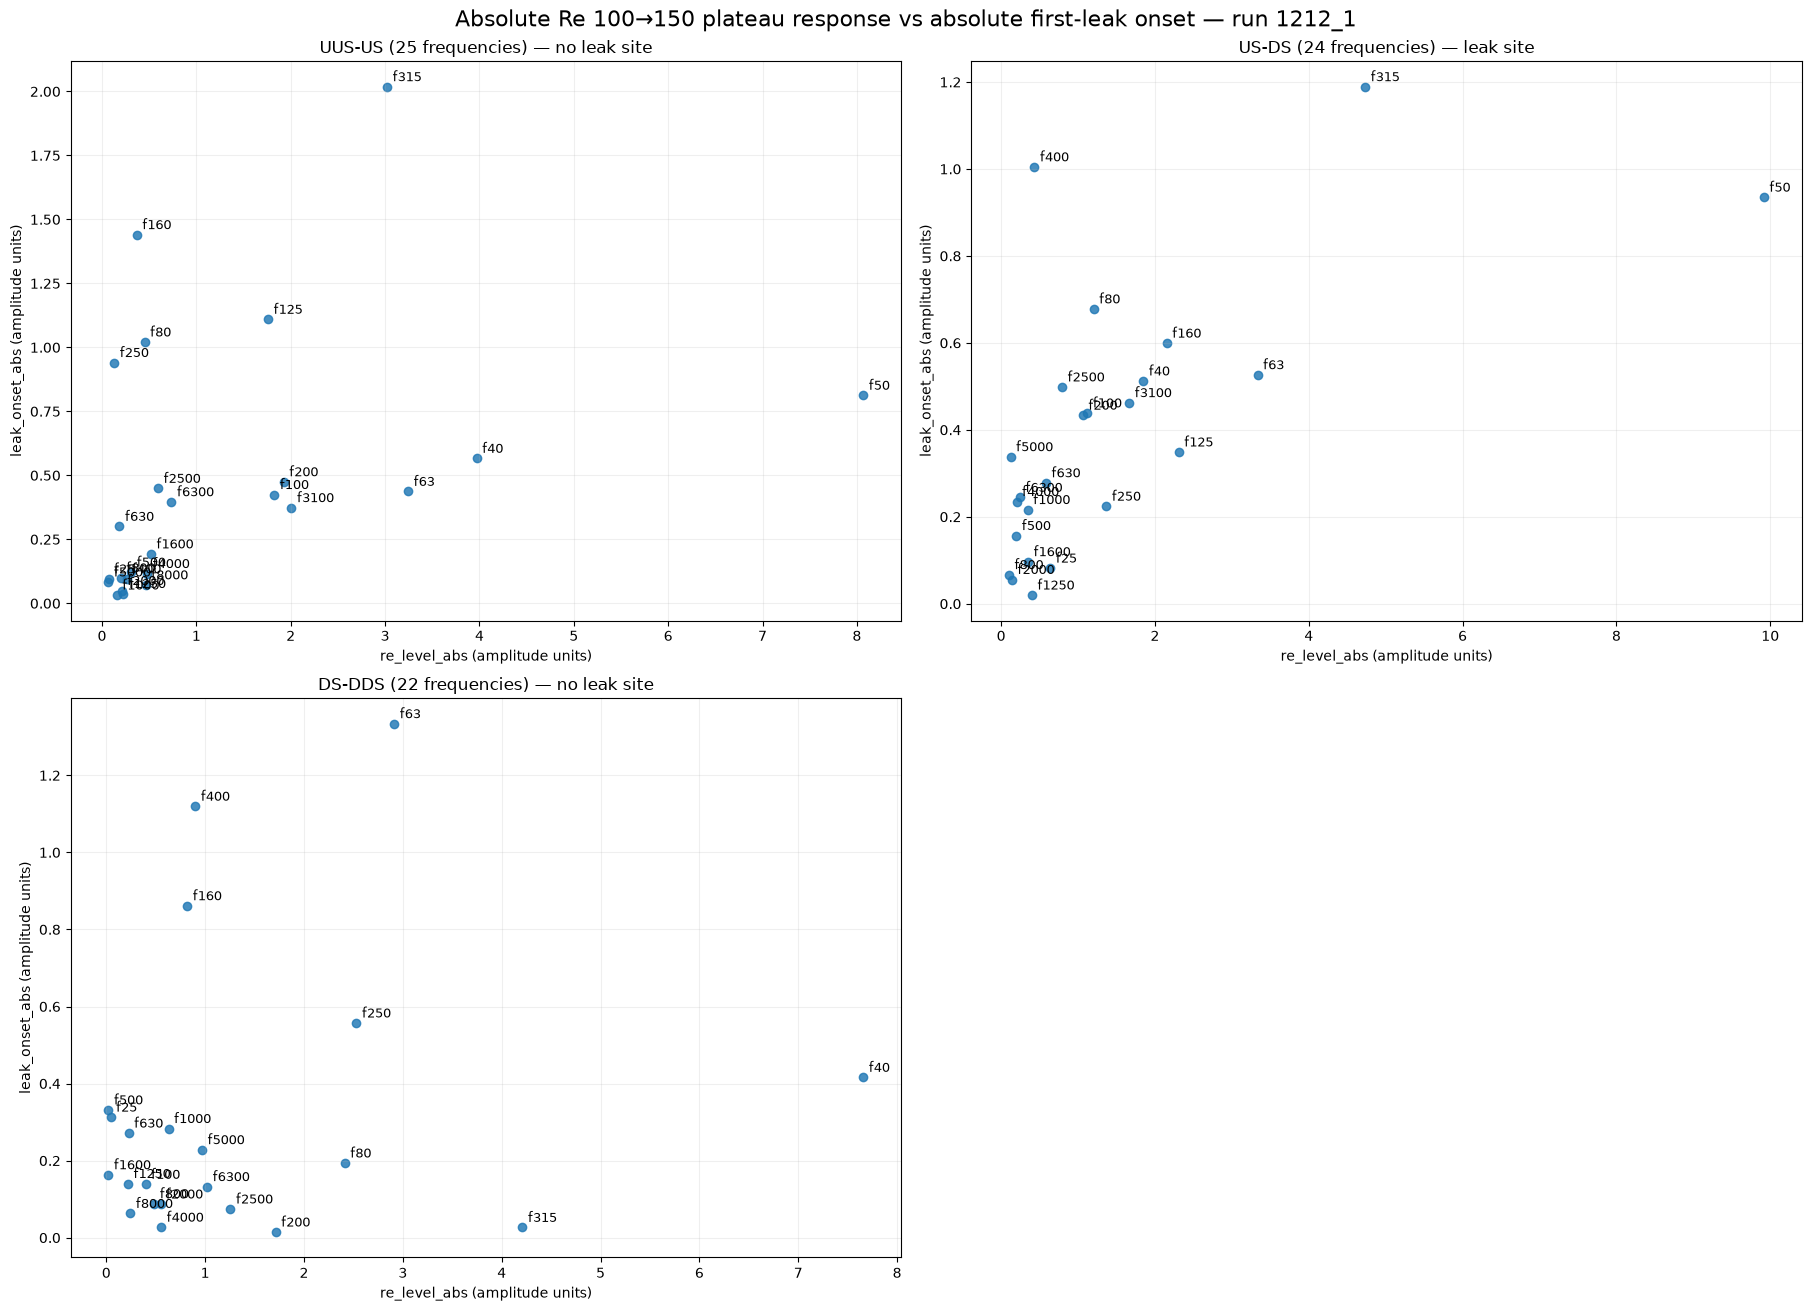

1212_1: absolute_re100to150_vs_absolute_leak_onset → 71 frequency points


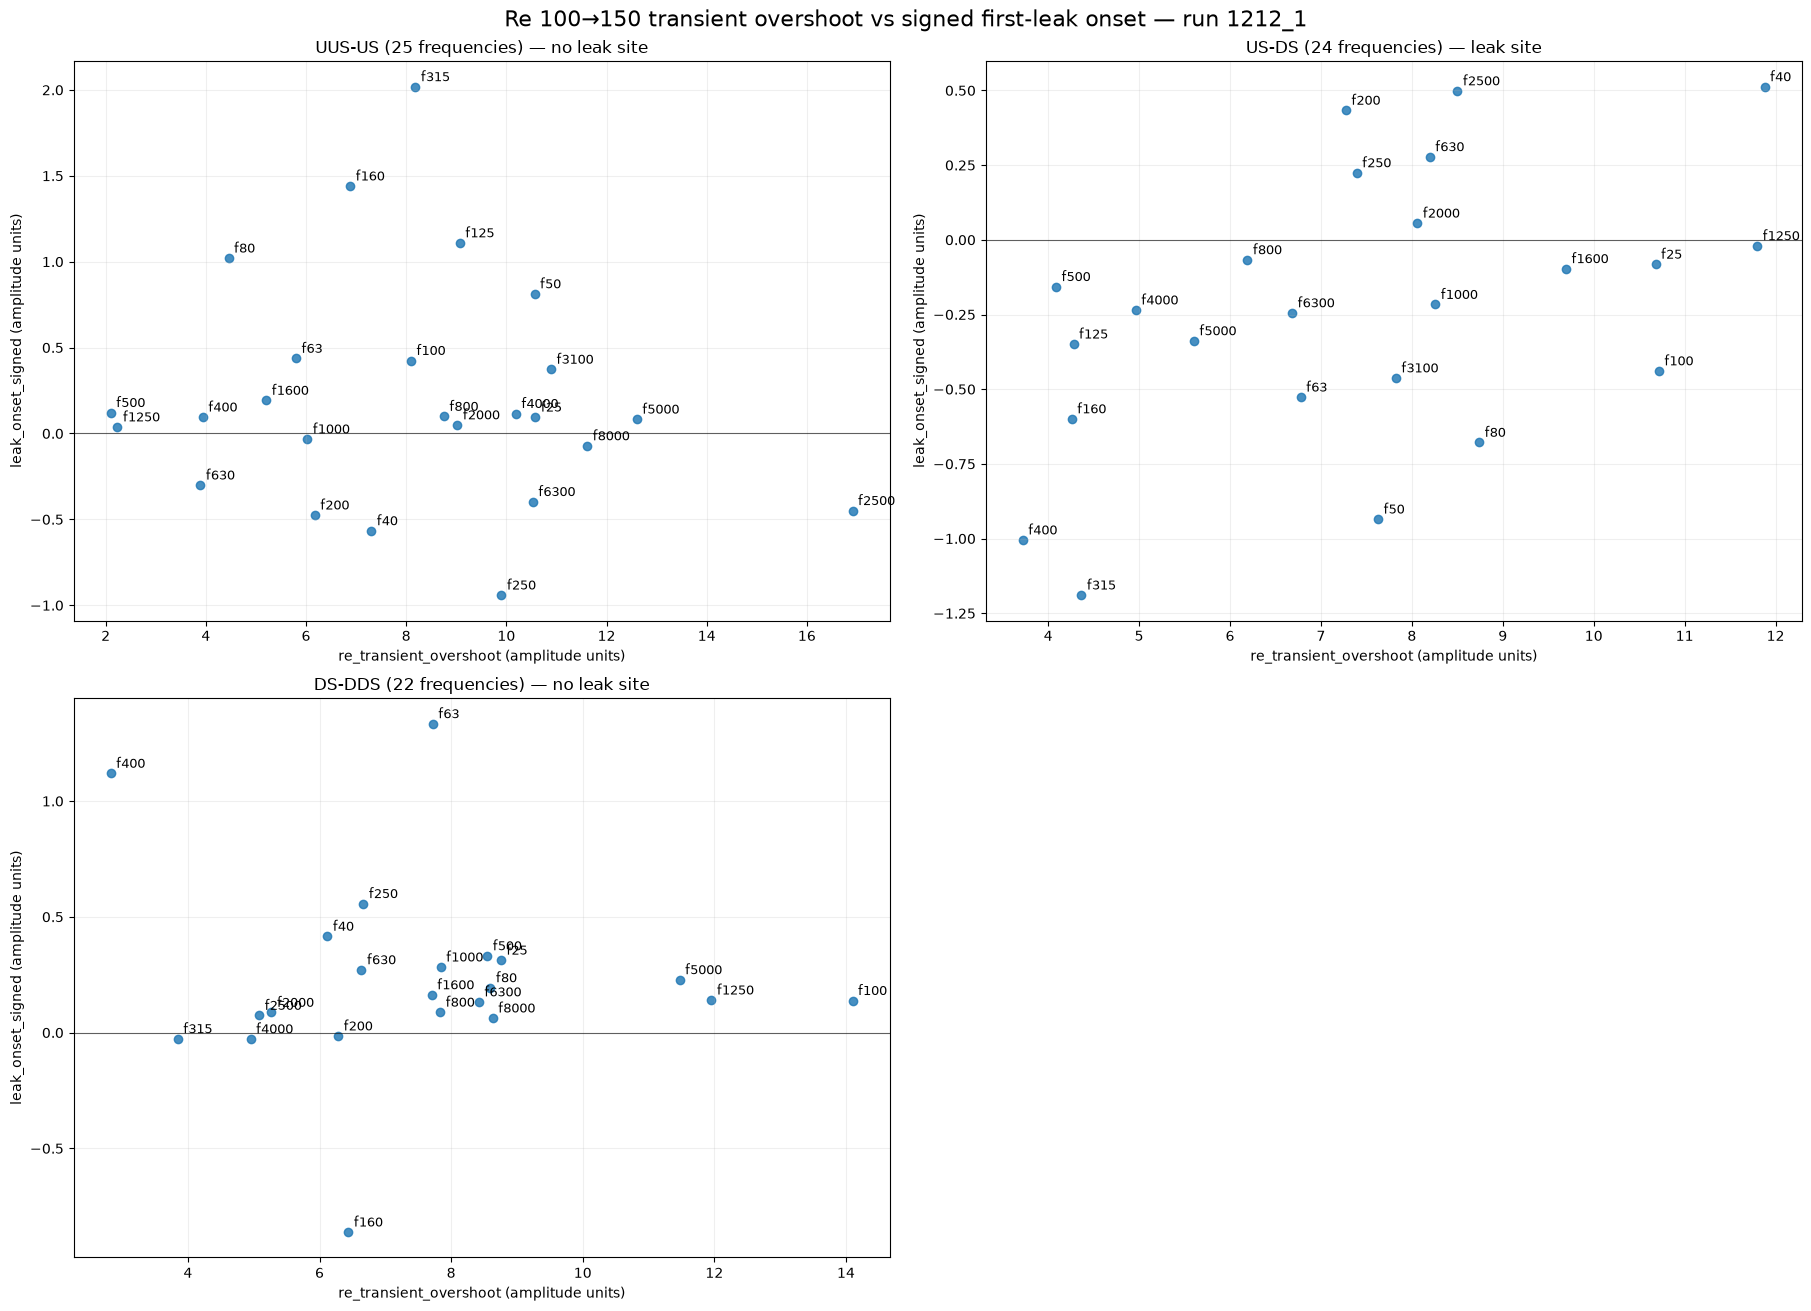

1212_1: overshoot_re100to150_vs_signed_leak_onset → 71 frequency points


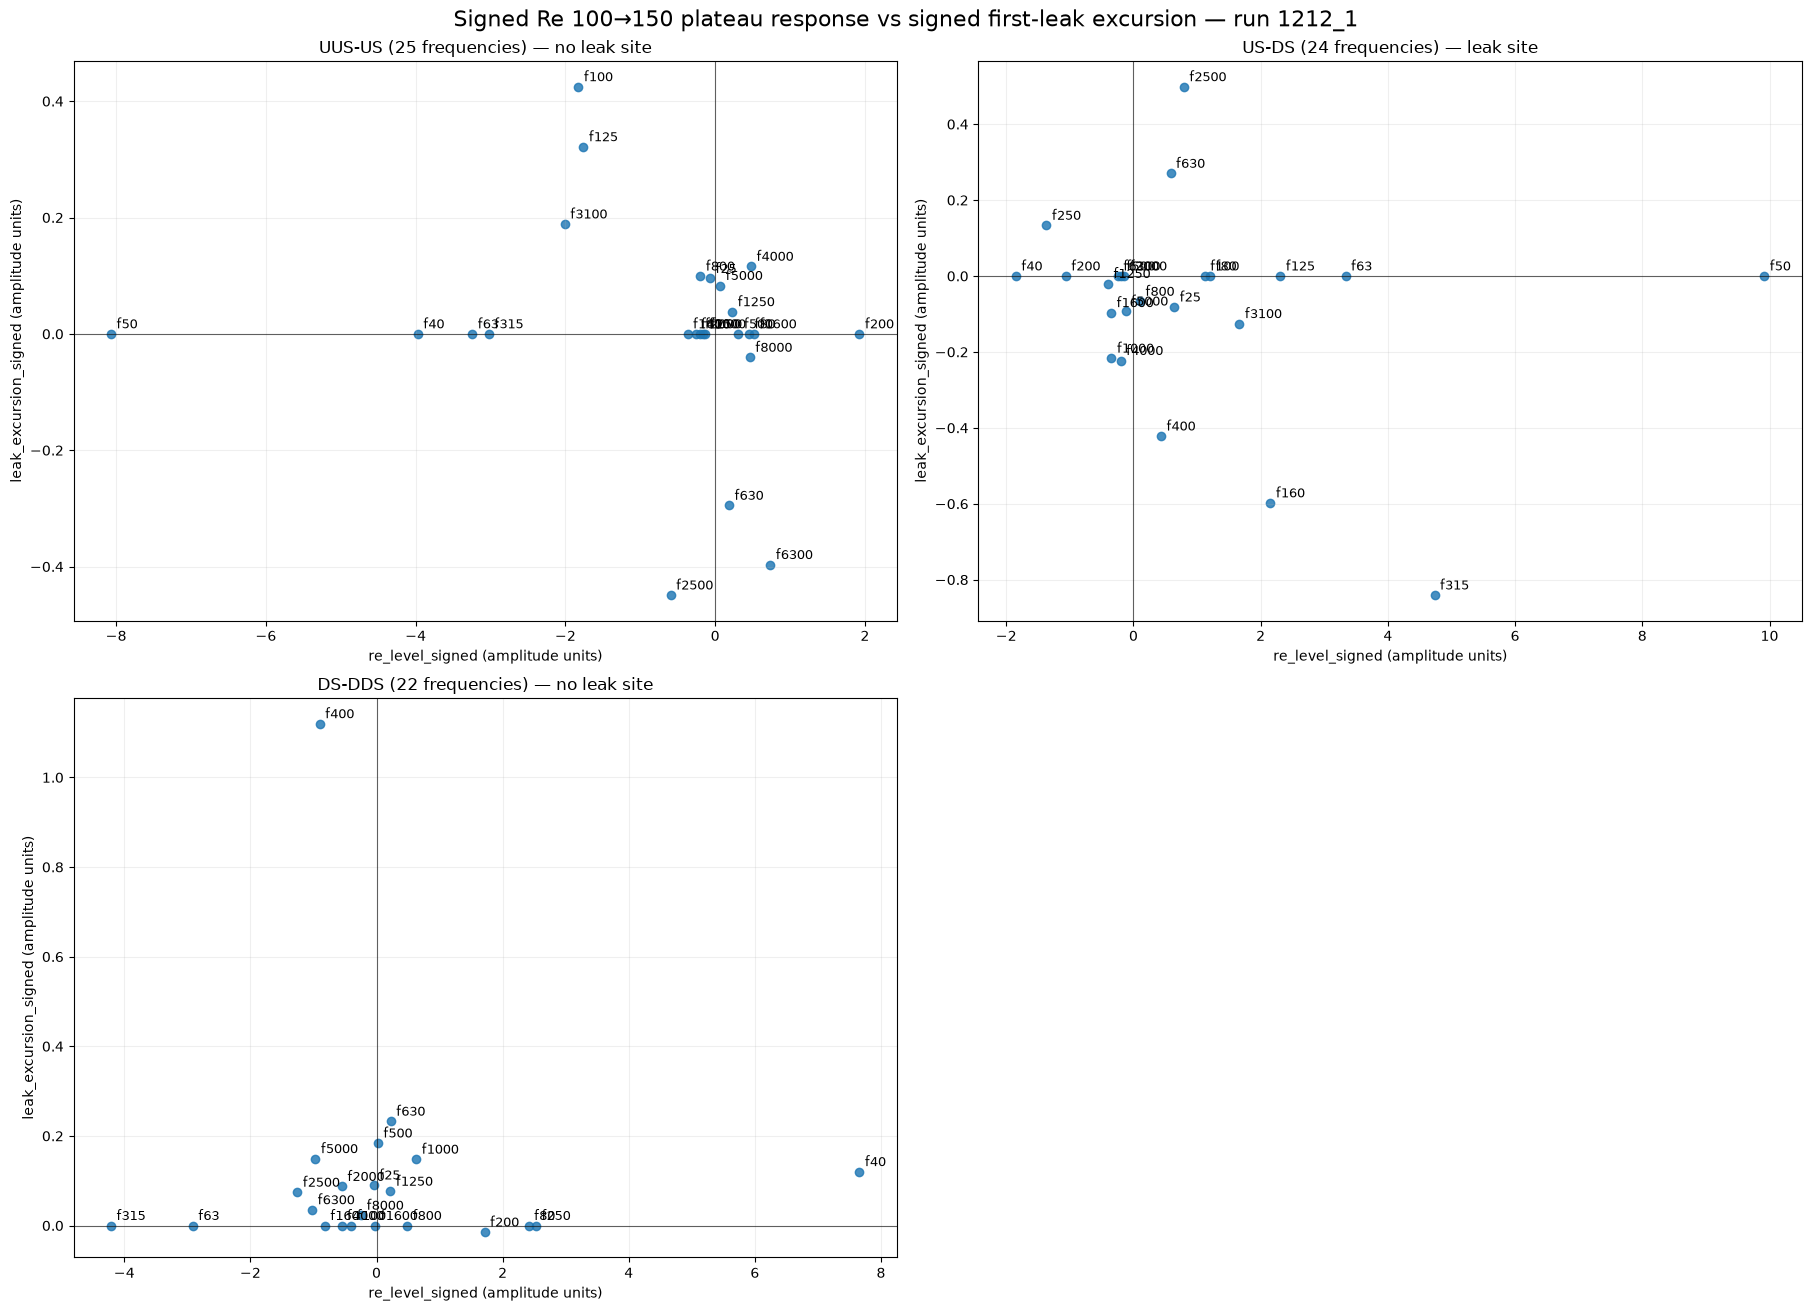

1212_1: signed_re100to150_vs_signed_leak_excursion → 71 frequency points


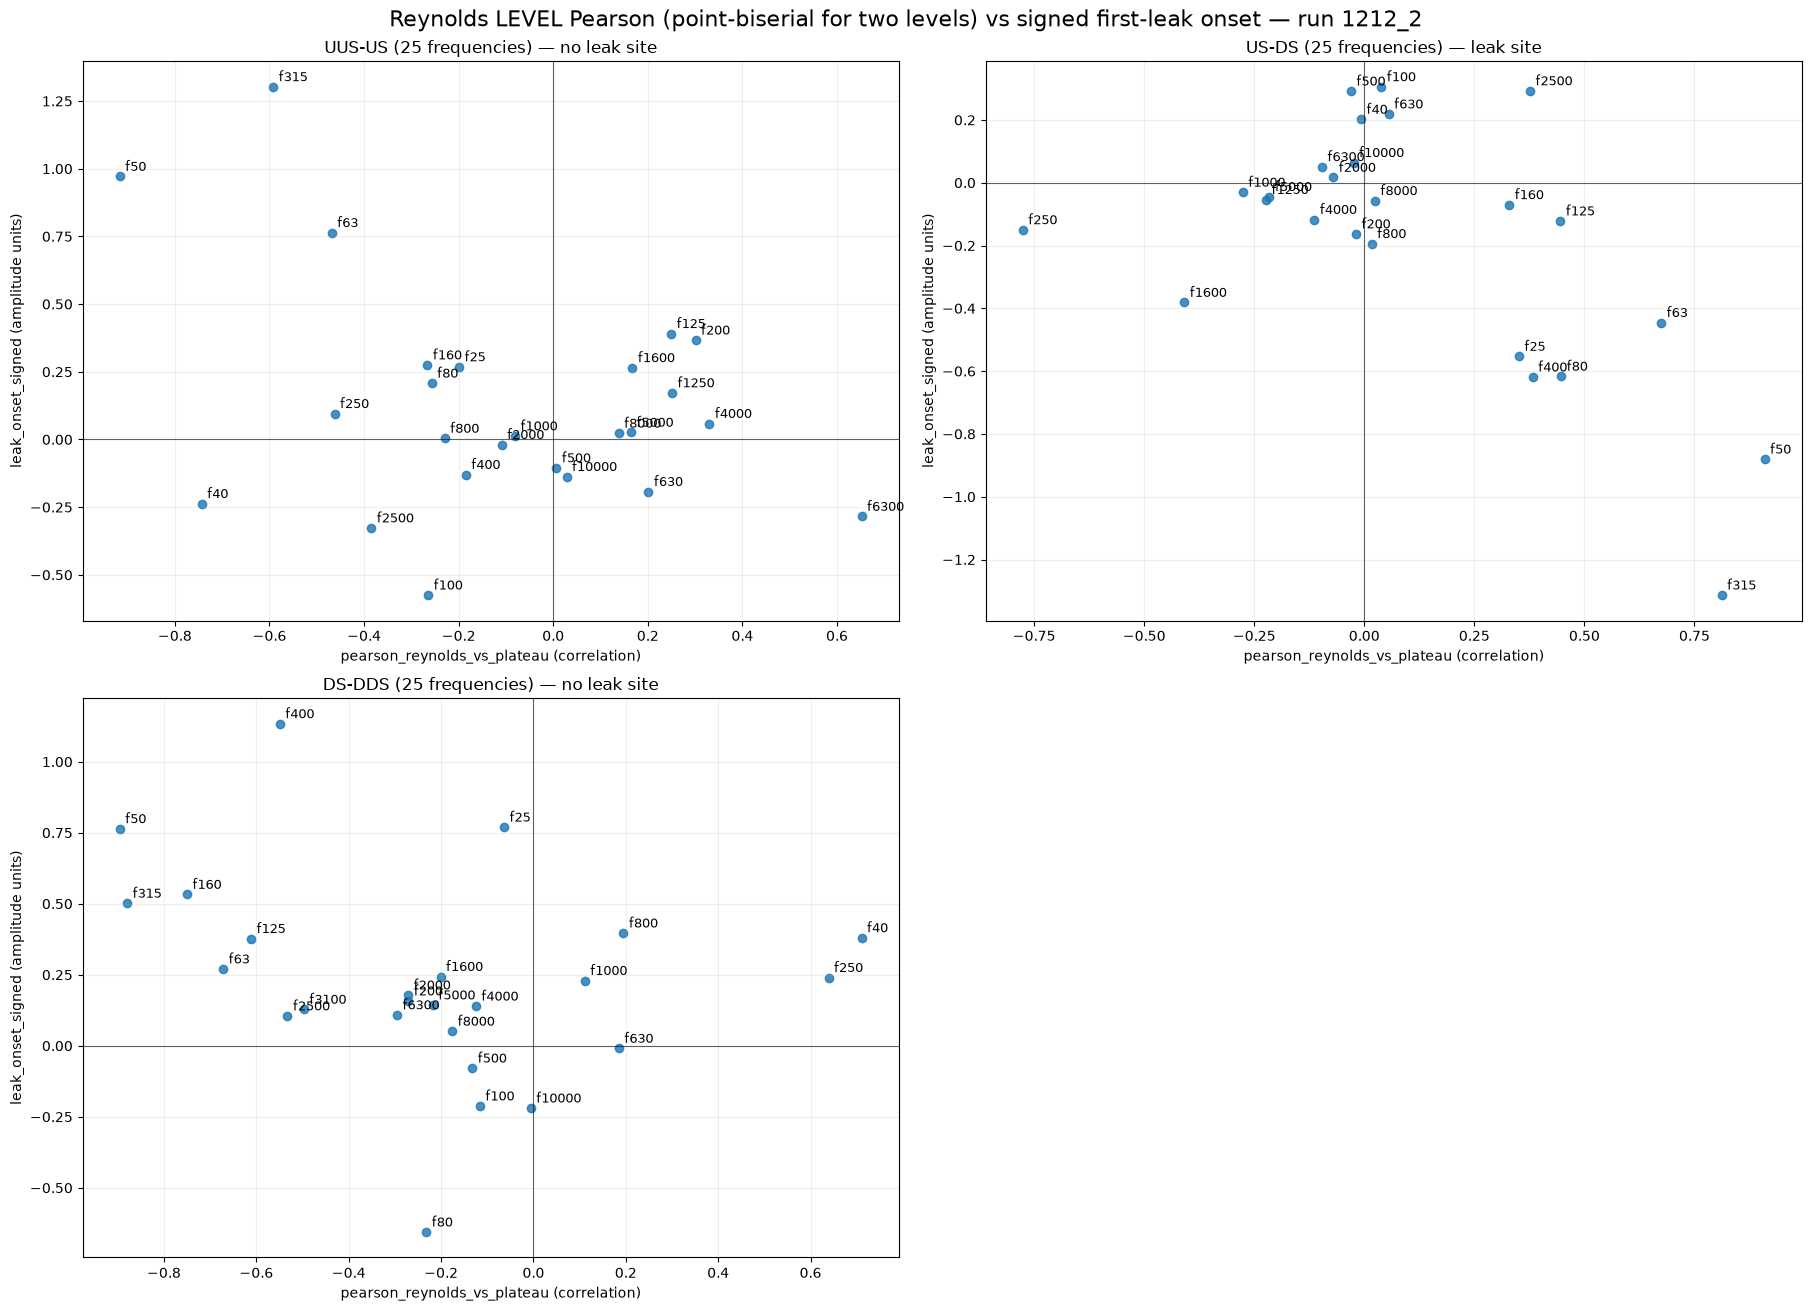

1212_2: level_pearson_vs_signed_leak_onset → 75 frequency points


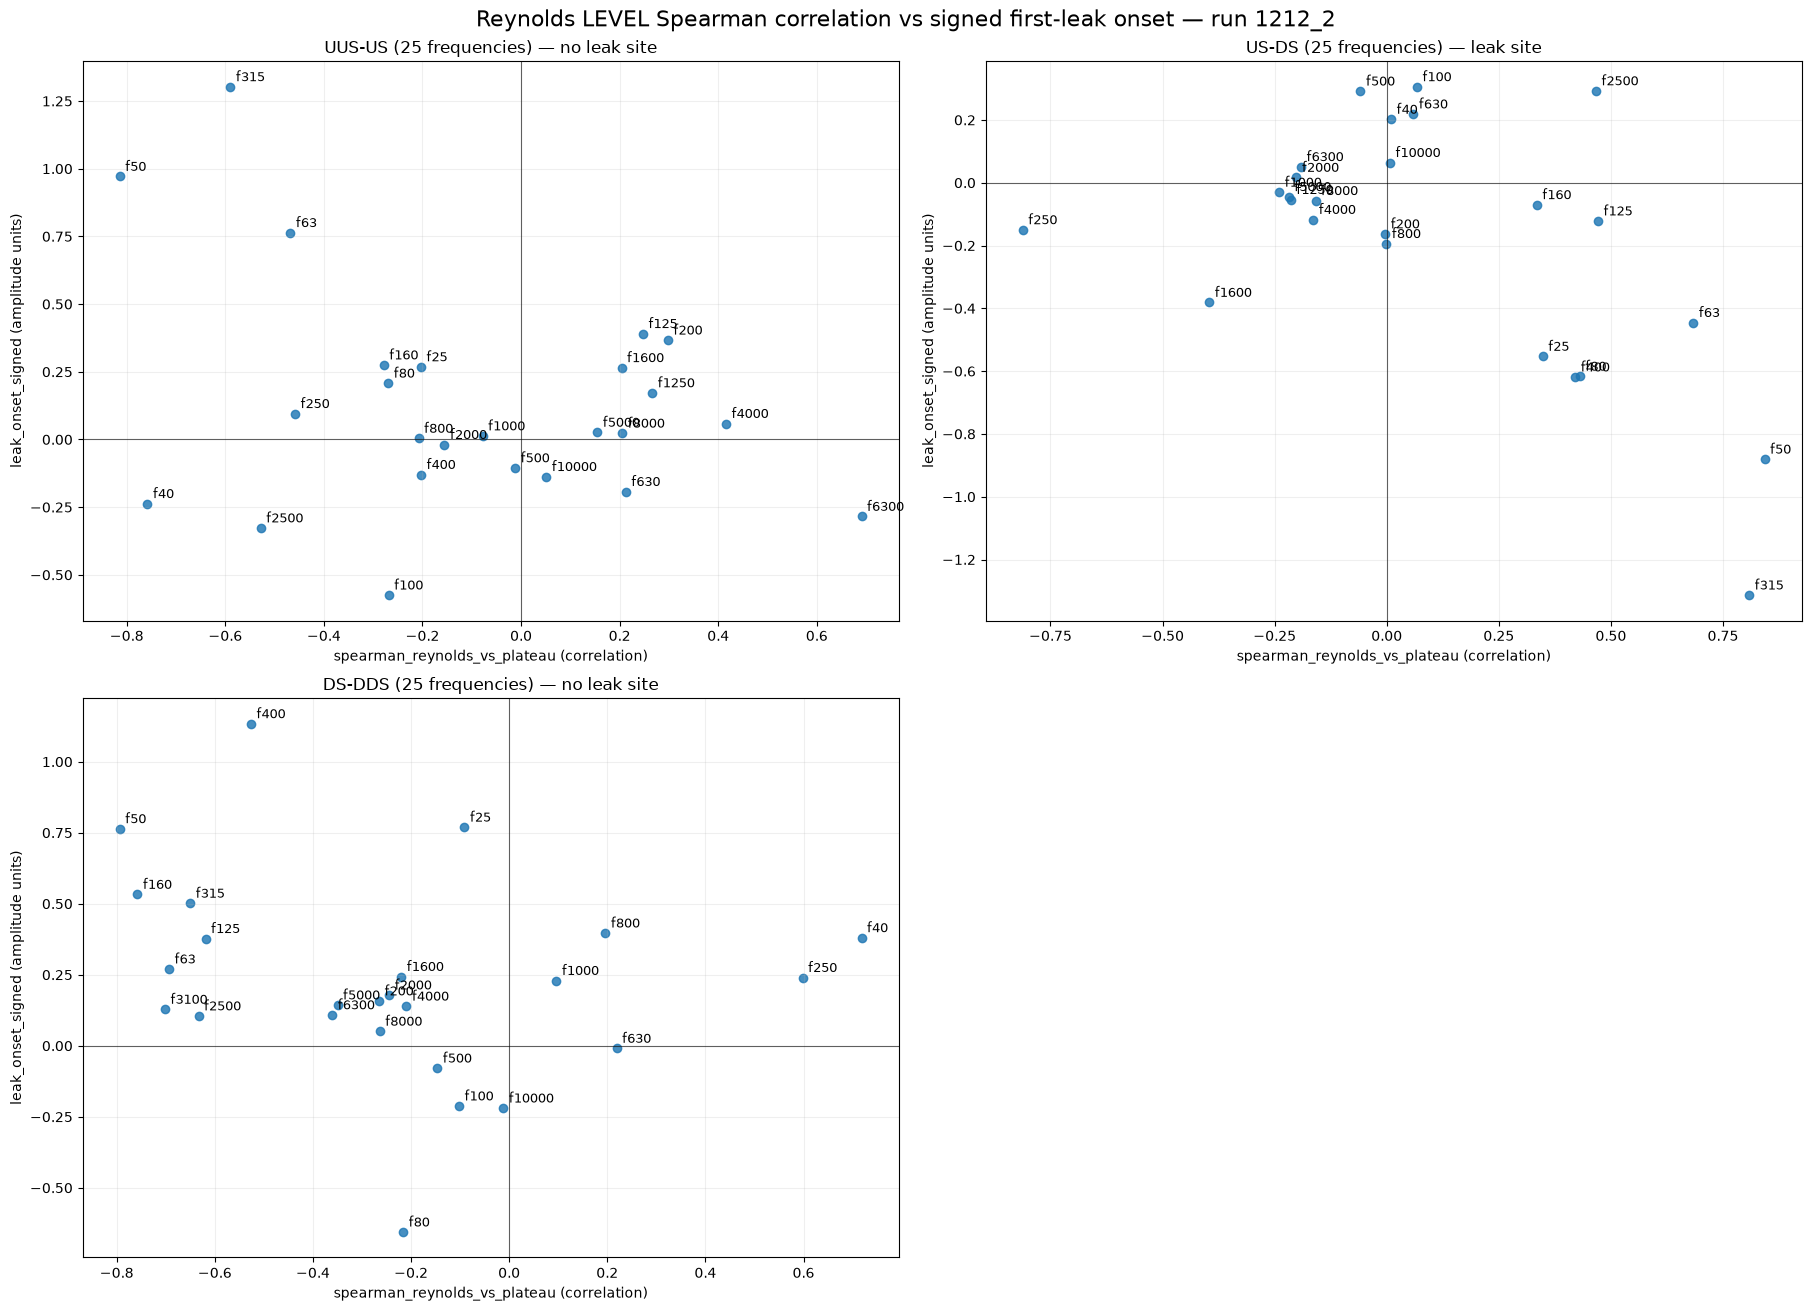

1212_2: level_spearman_vs_signed_leak_onset → 75 frequency points


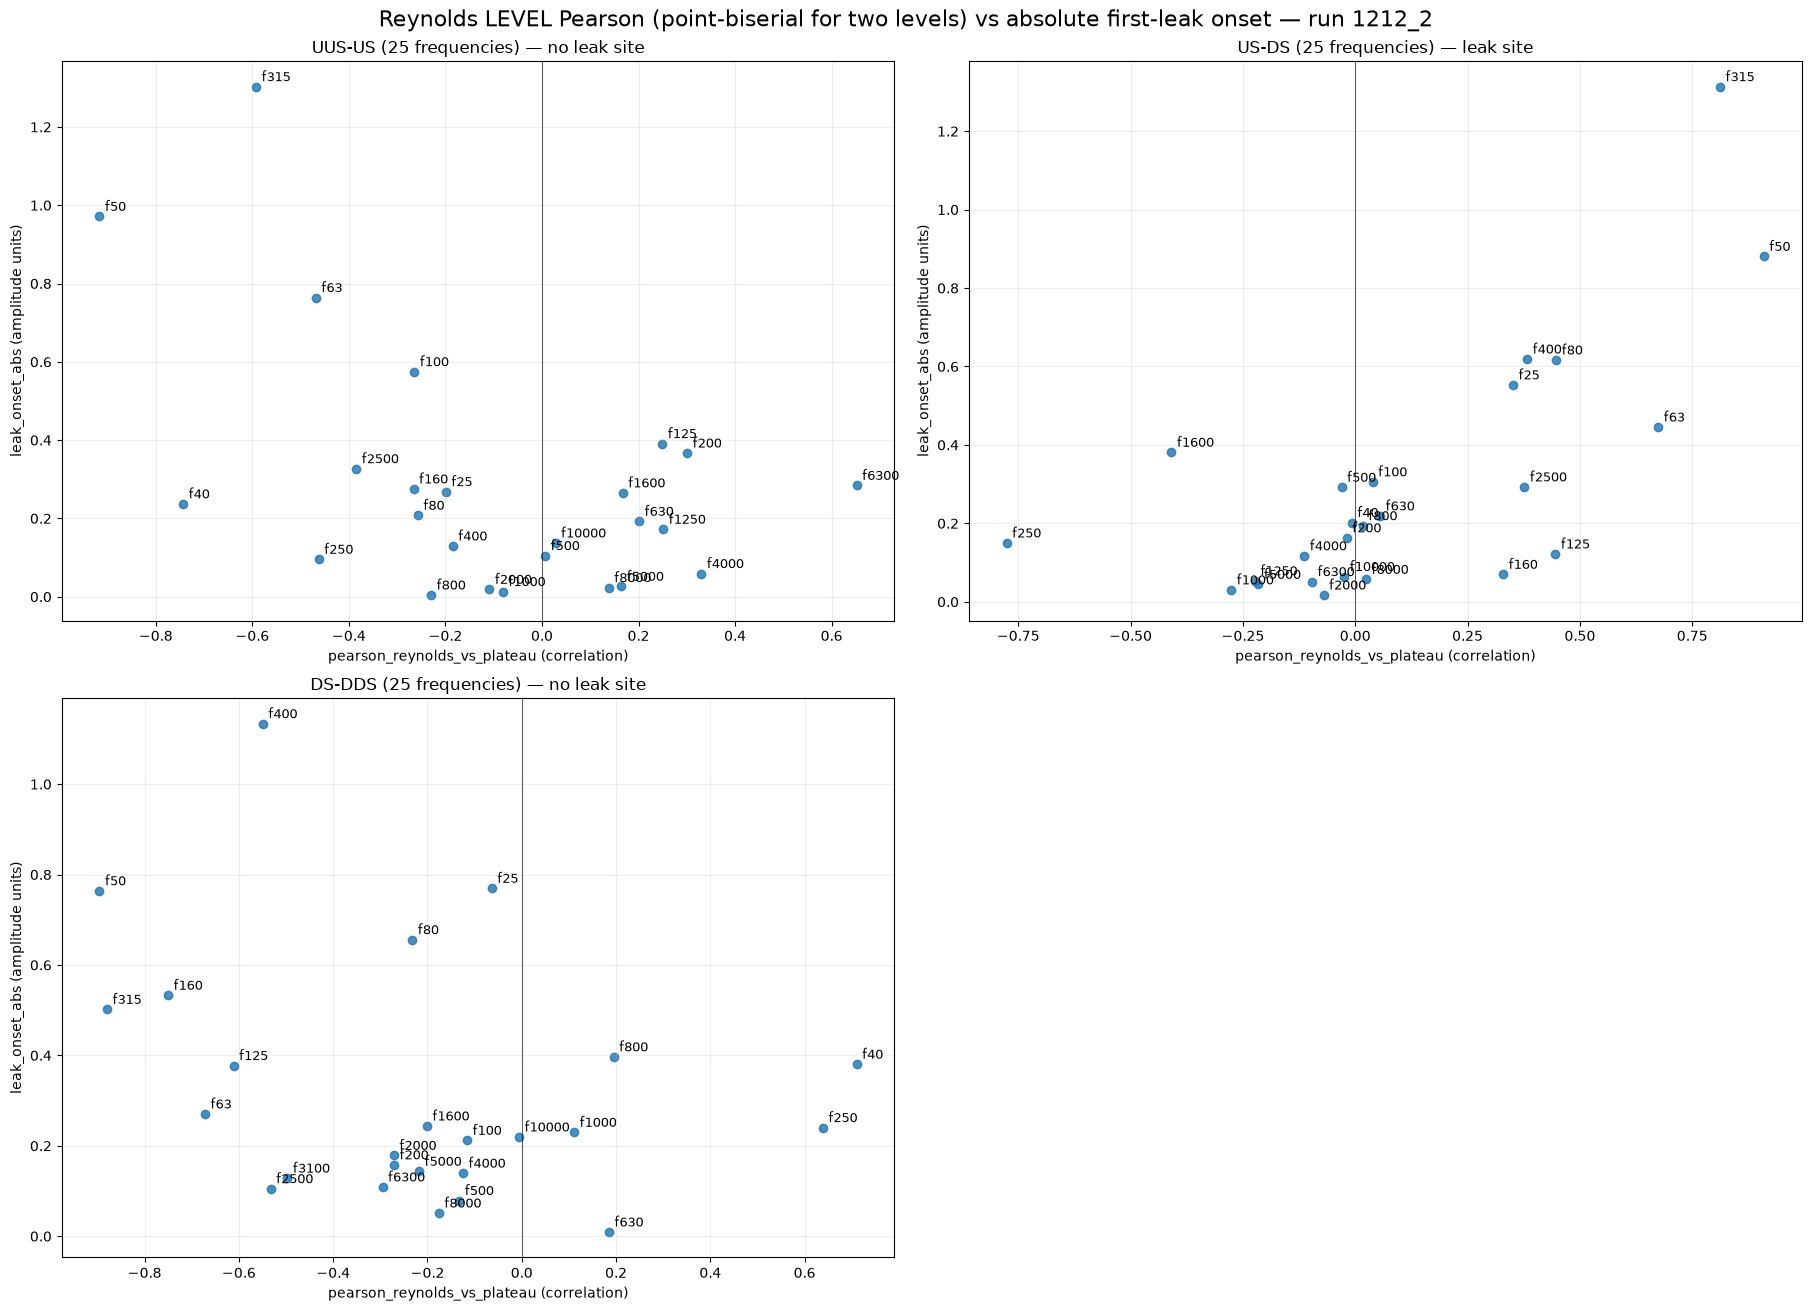

1212_2: level_pearson_vs_absolute_leak_onset → 75 frequency points


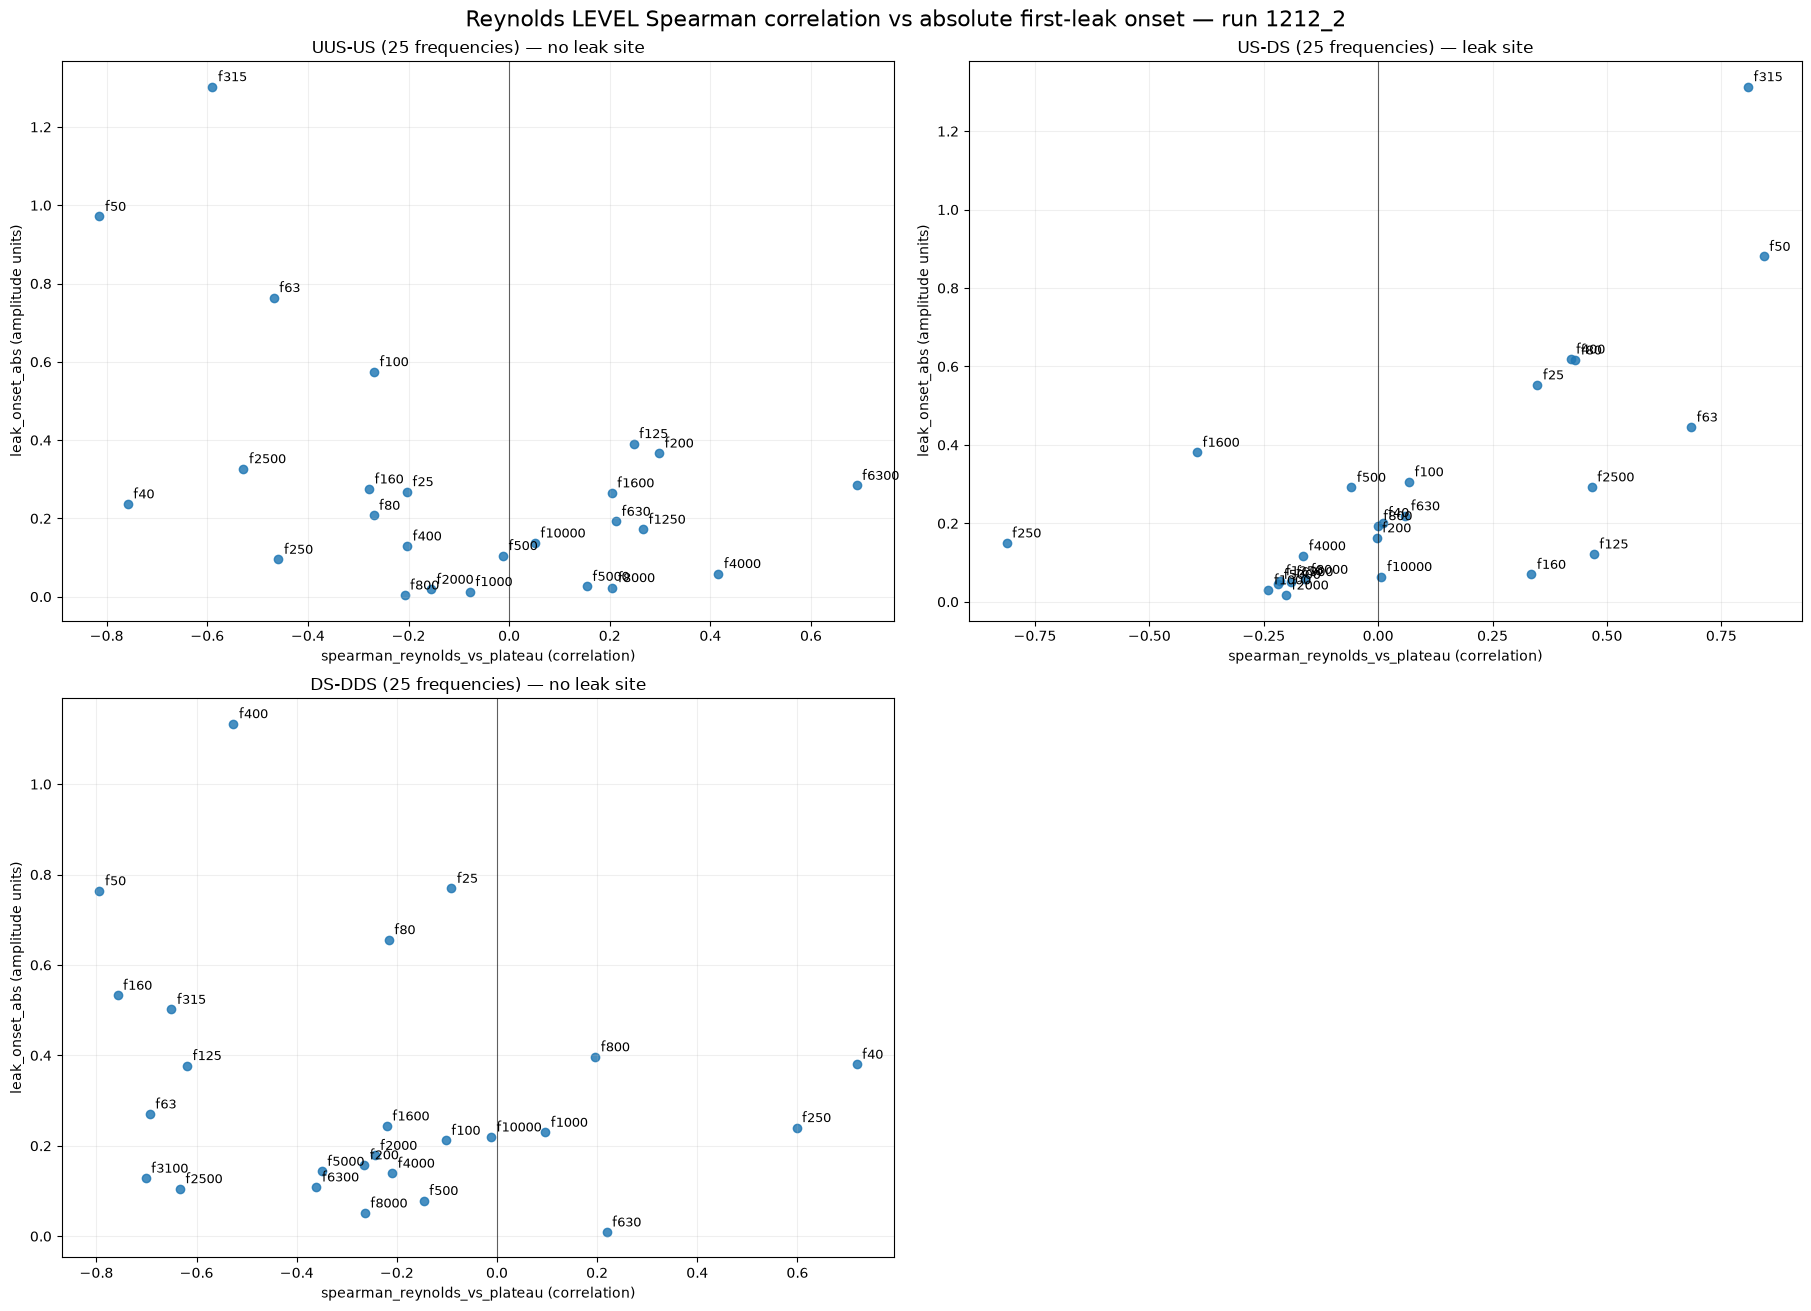

1212_2: level_spearman_vs_absolute_leak_onset → 75 frequency points


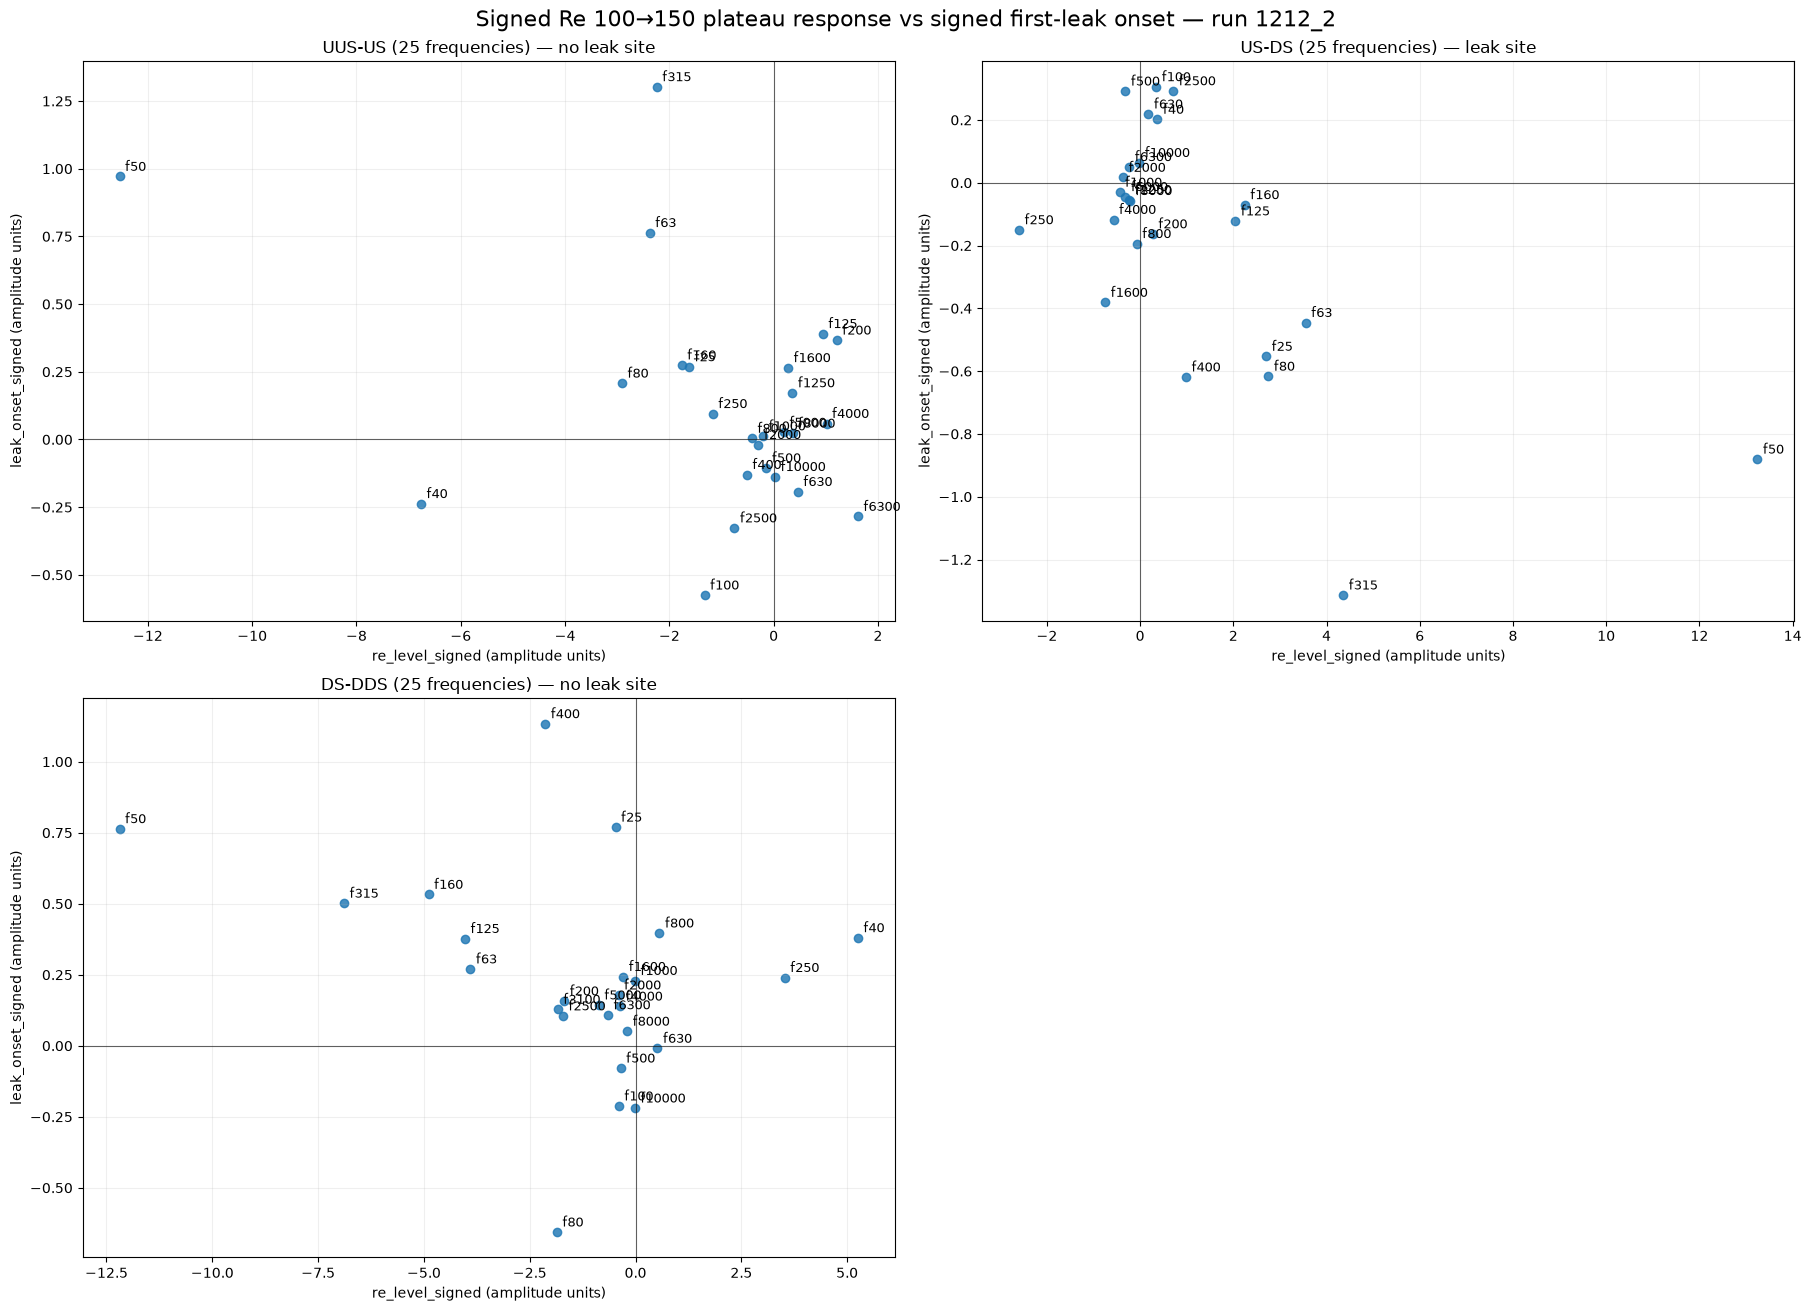

1212_2: signed_re100to150_vs_signed_leak_onset → 75 frequency points


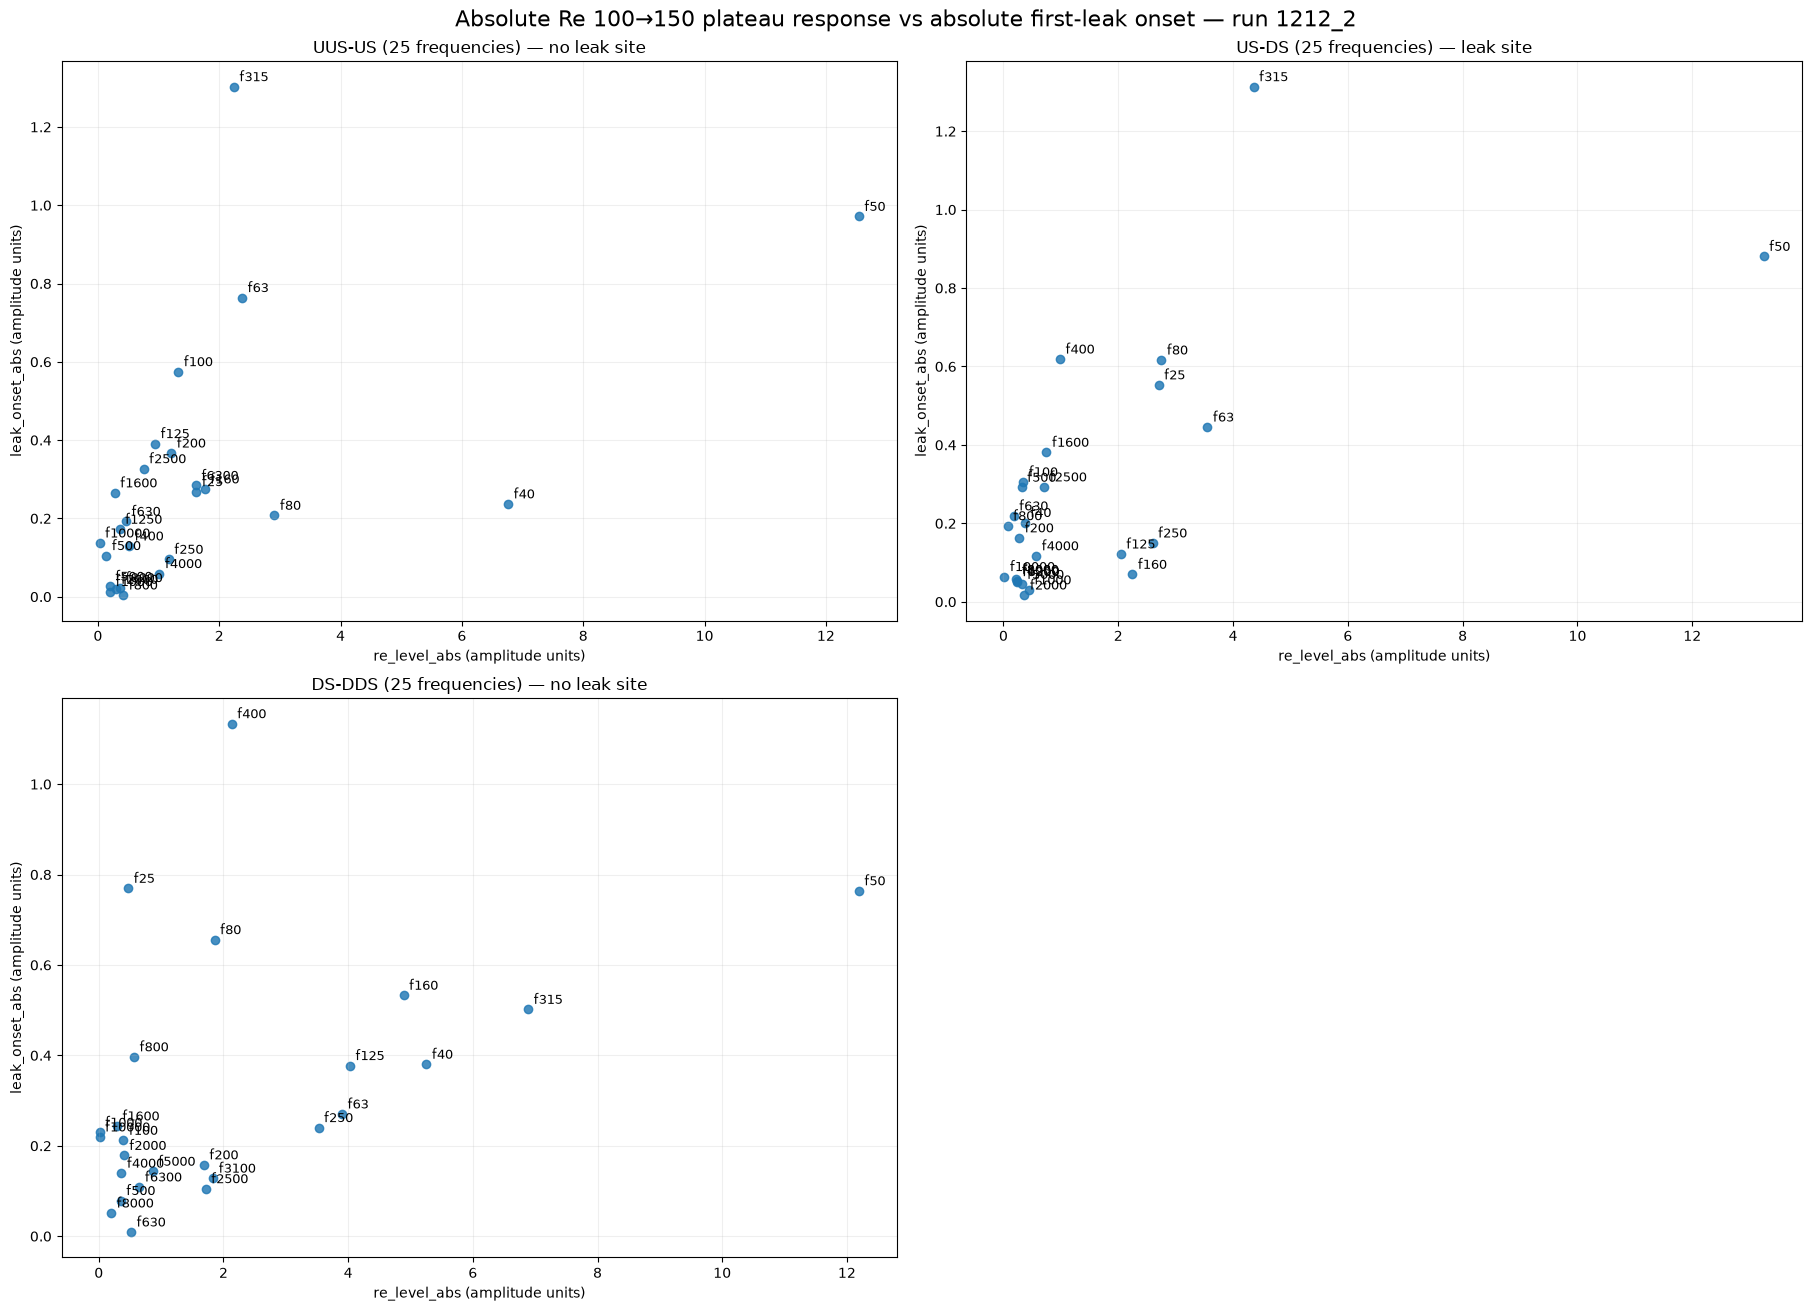

1212_2: absolute_re100to150_vs_absolute_leak_onset → 75 frequency points


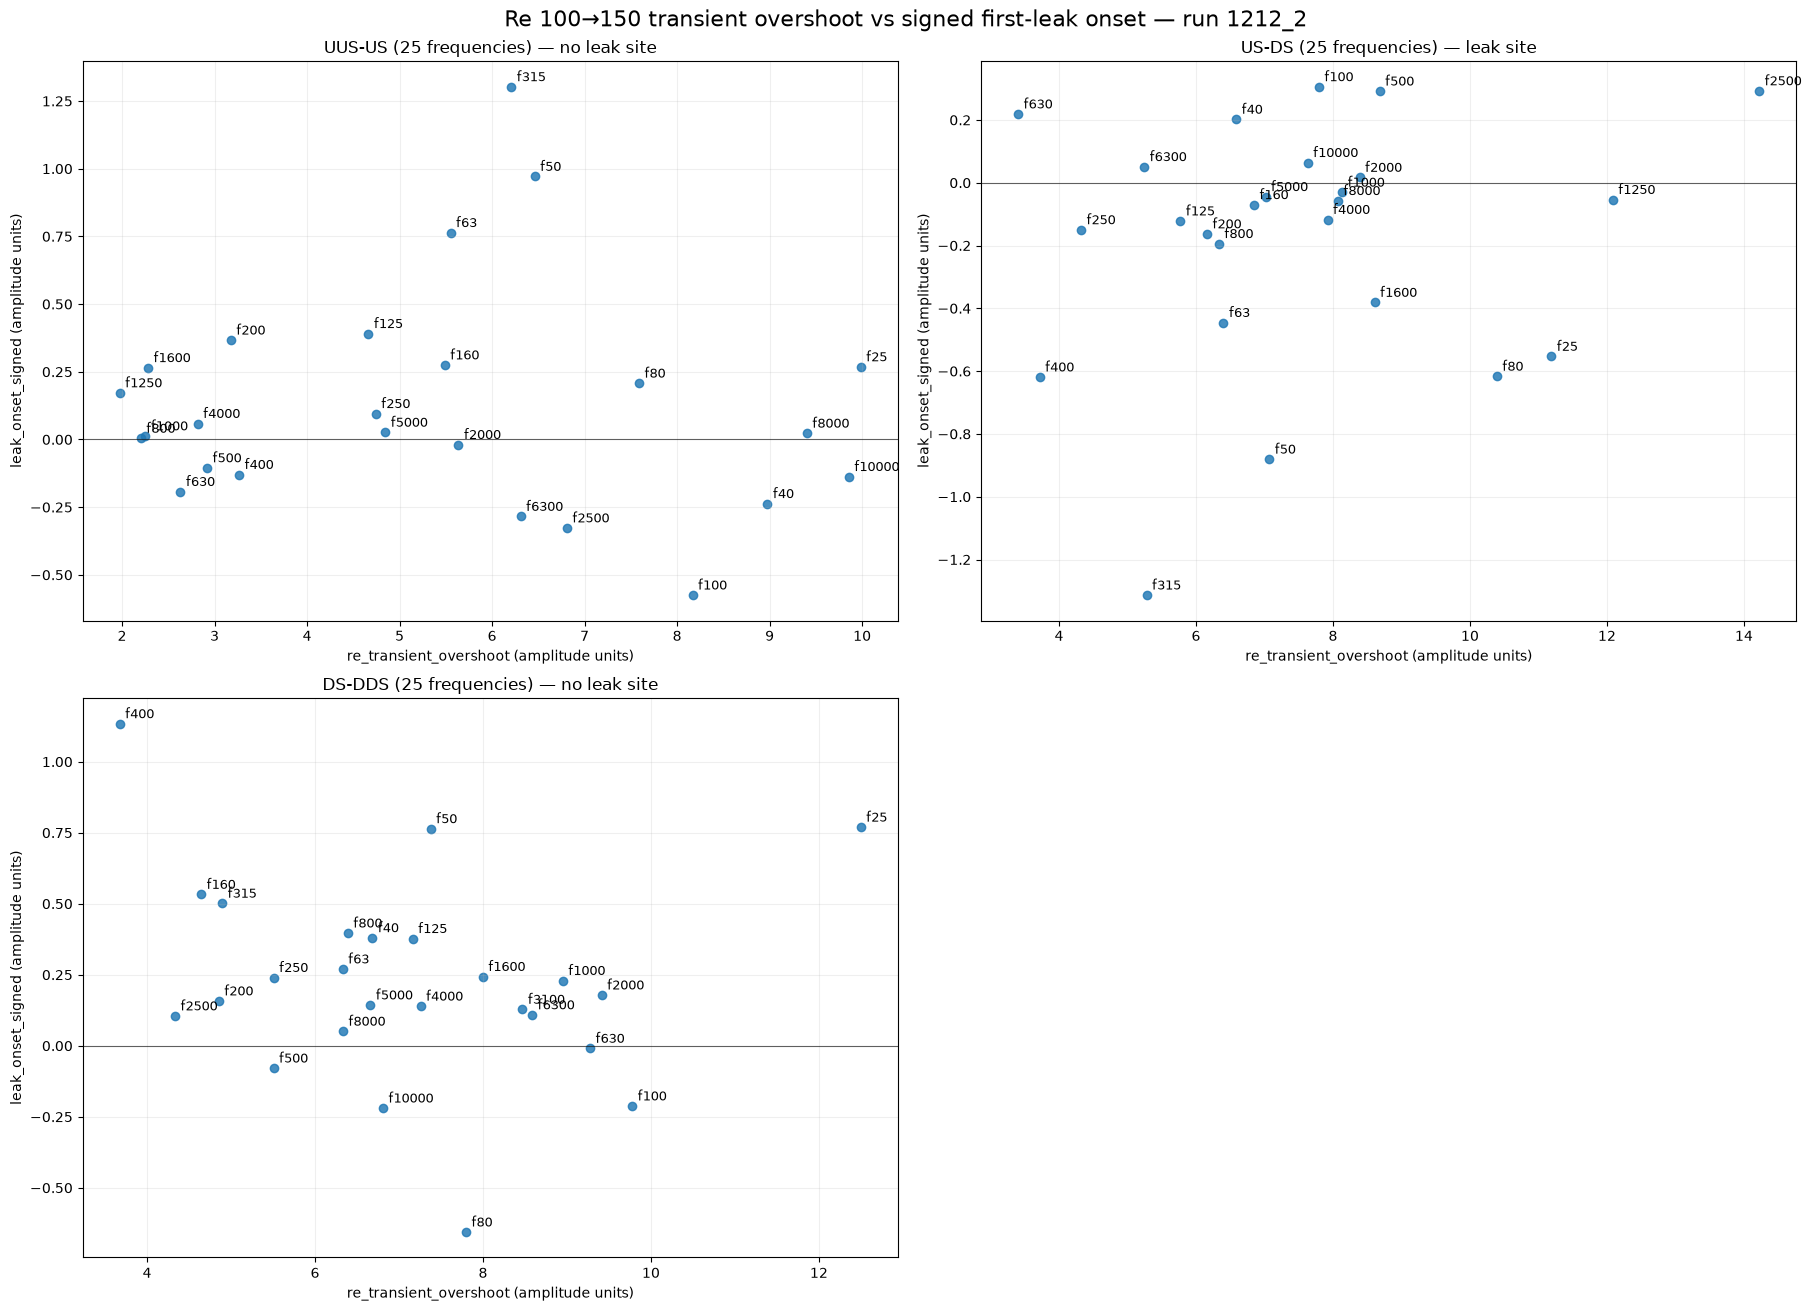

1212_2: overshoot_re100to150_vs_signed_leak_onset → 75 frequency points


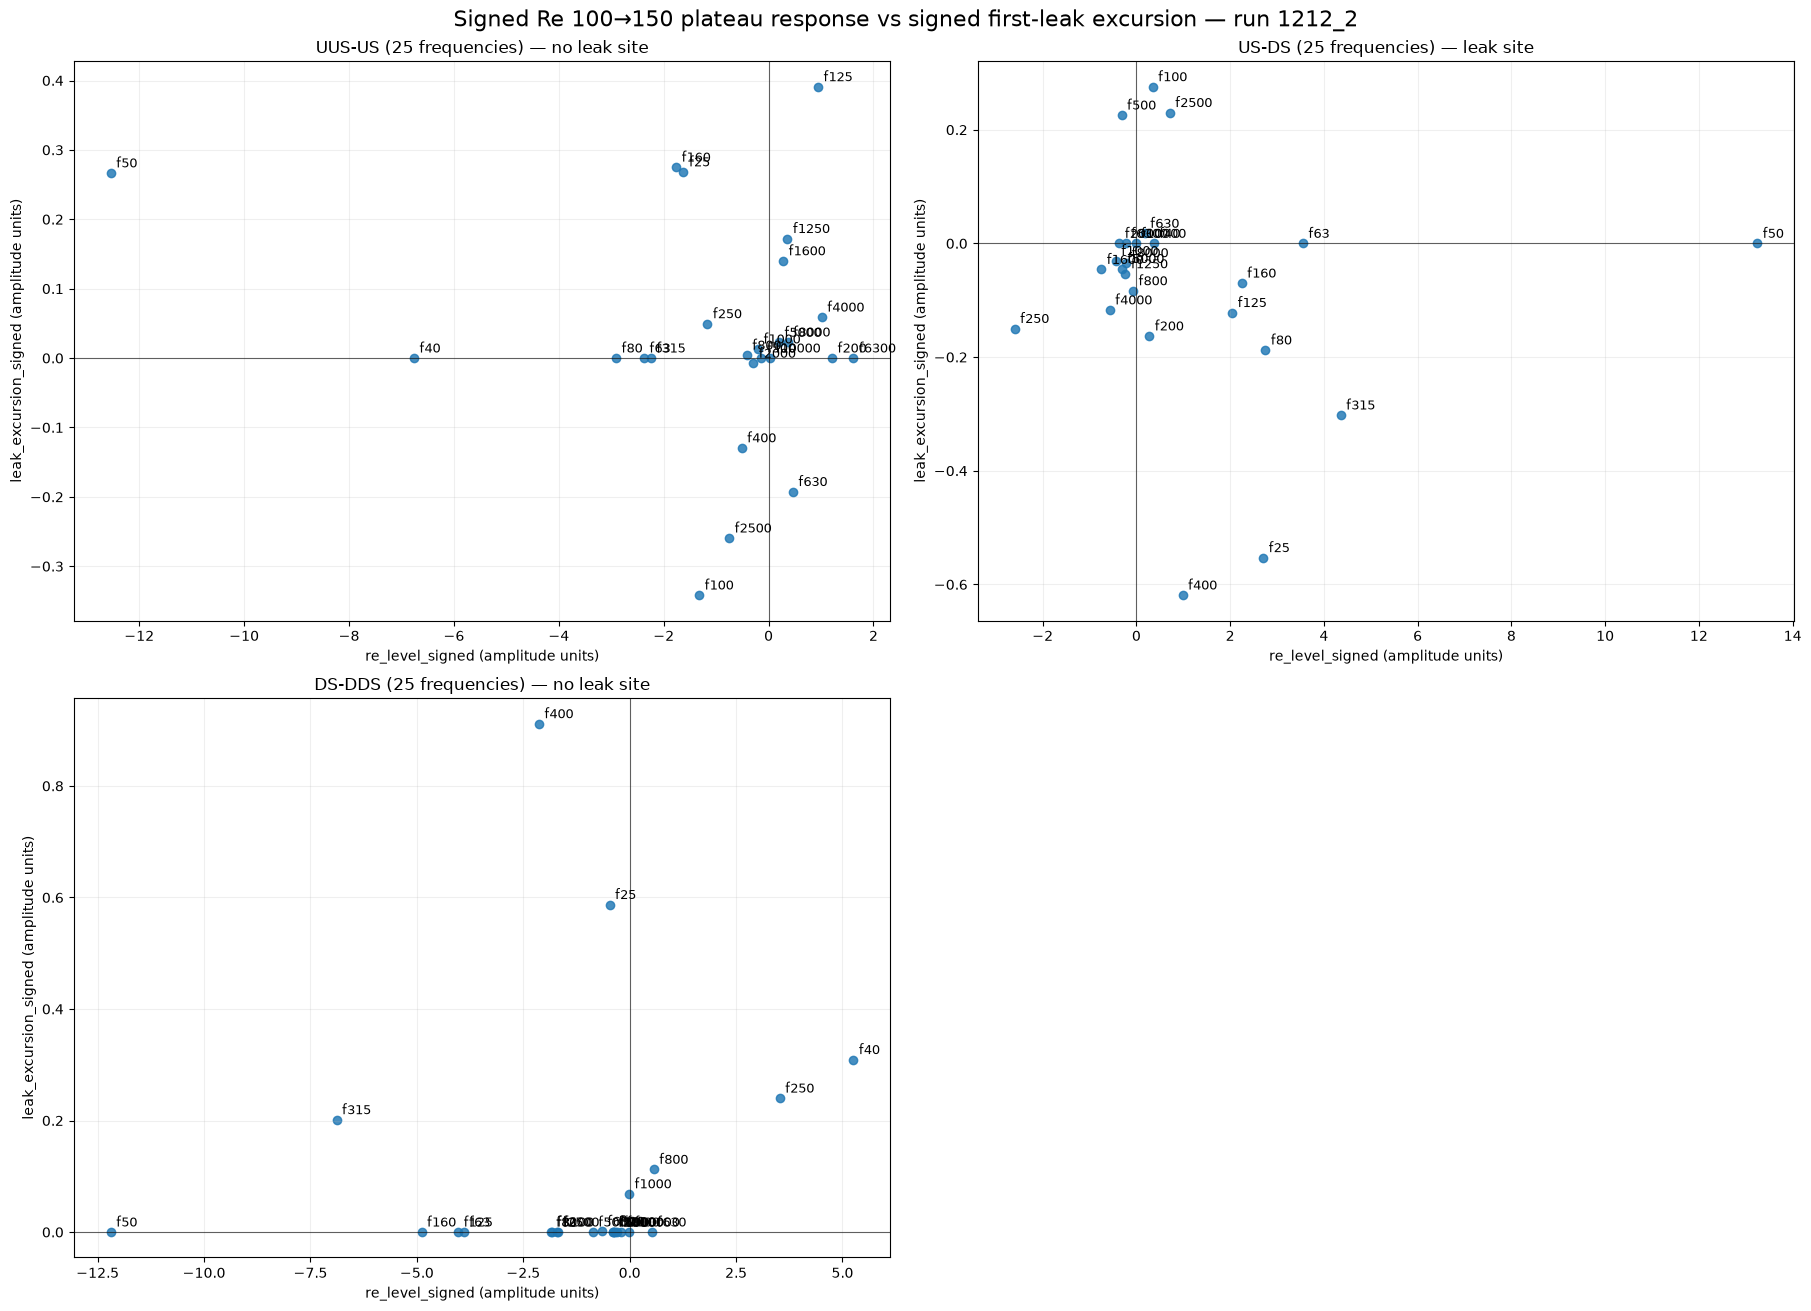

1212_2: signed_re100to150_vs_signed_leak_excursion → 75 frequency points


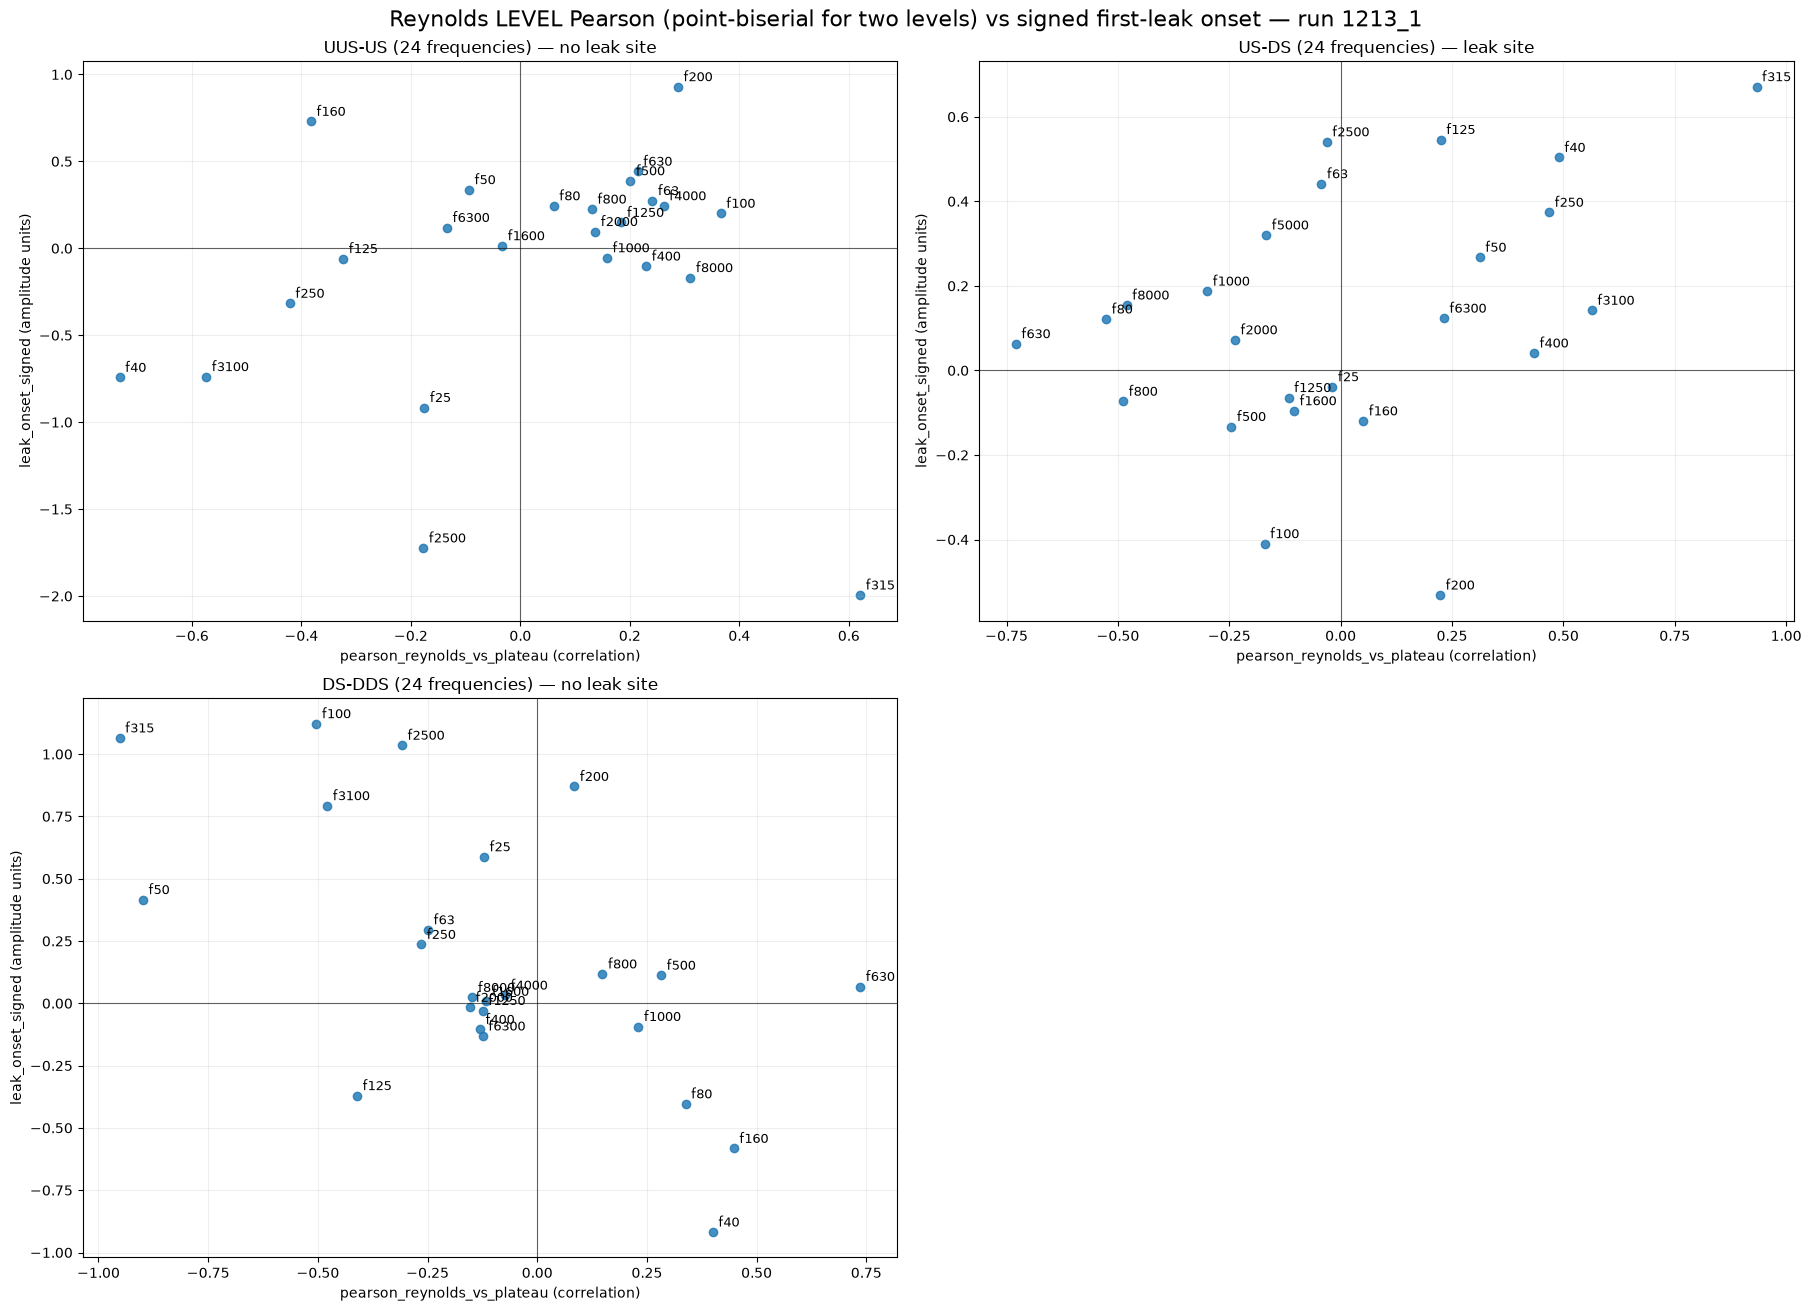

1213_1: level_pearson_vs_signed_leak_onset → 72 frequency points


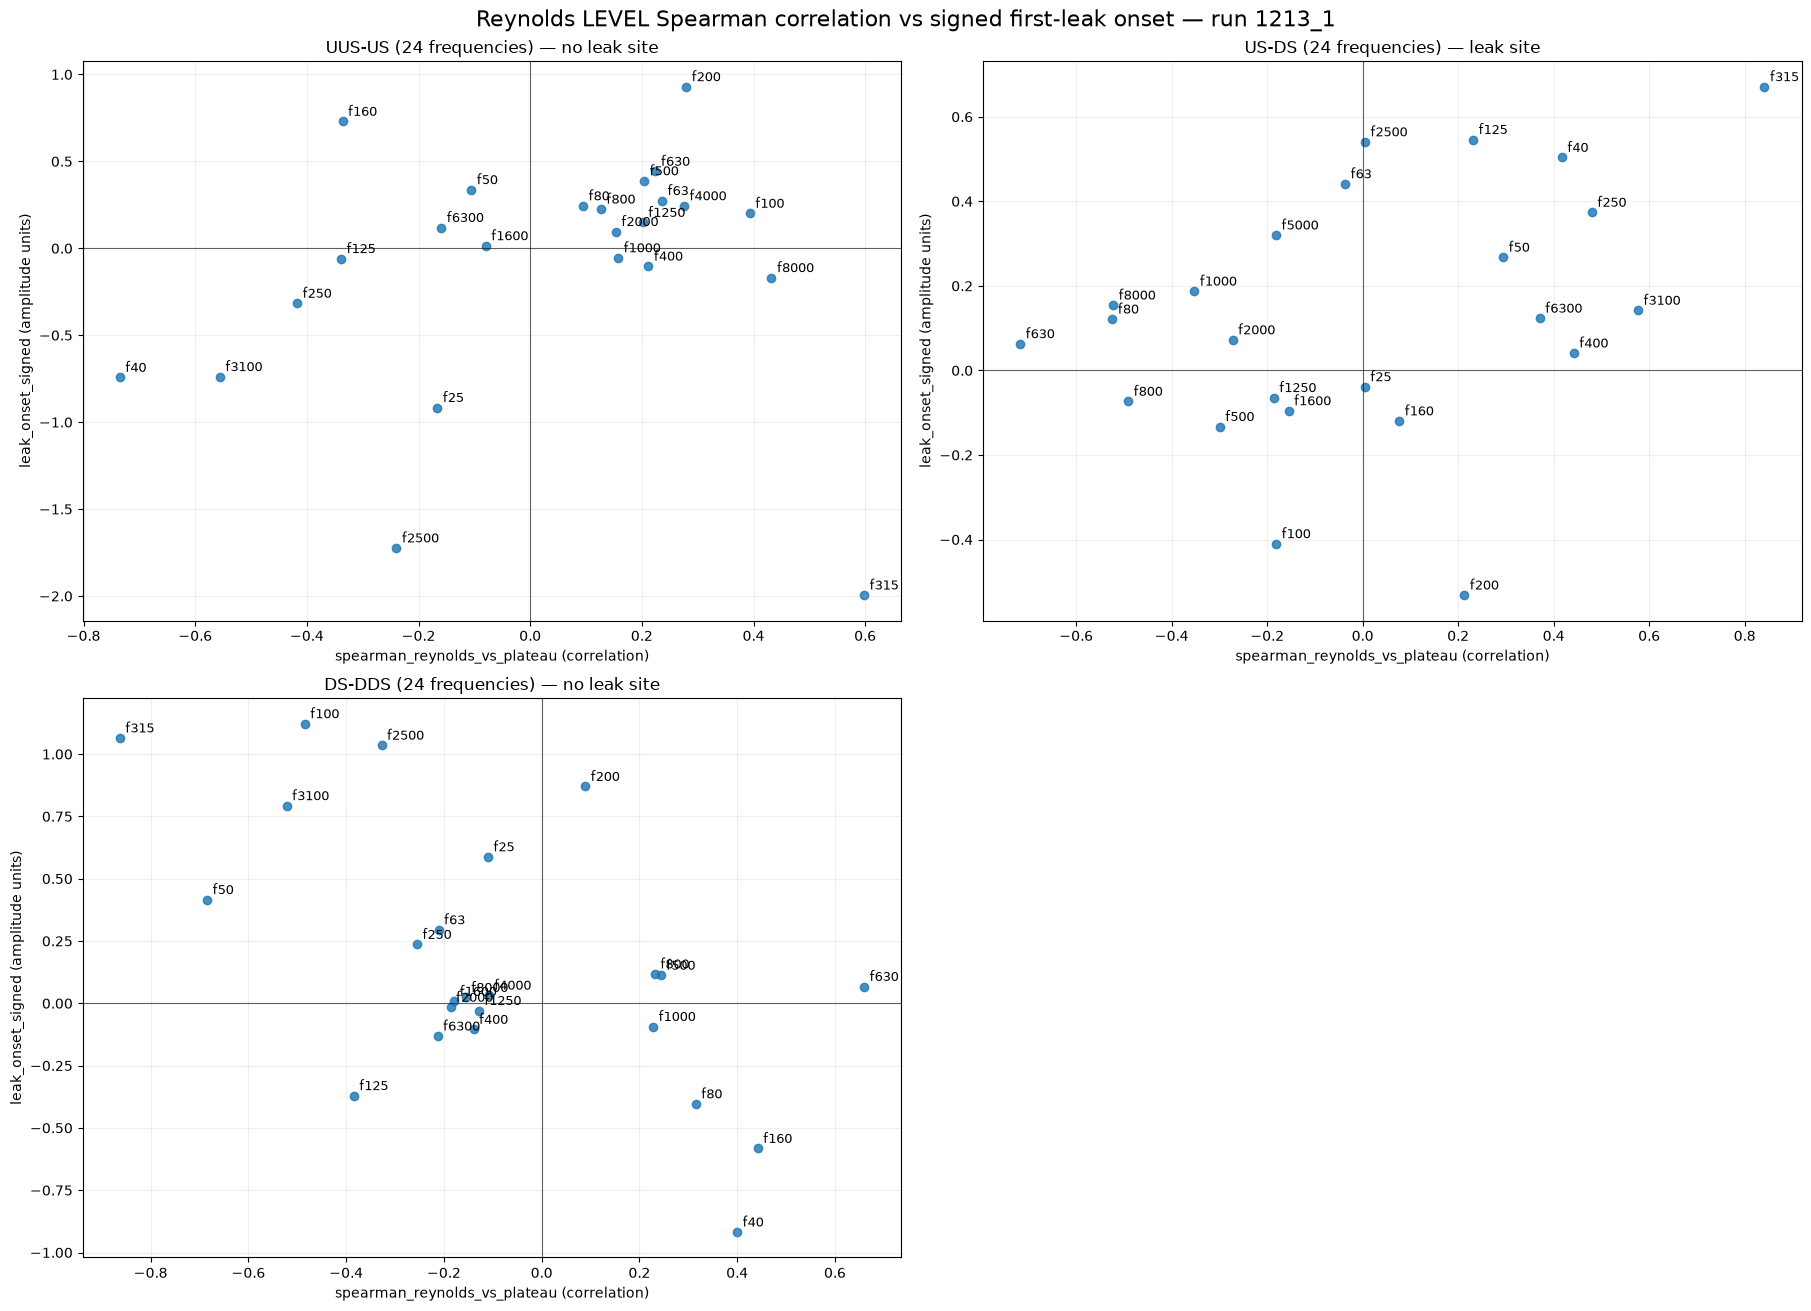

1213_1: level_spearman_vs_signed_leak_onset → 72 frequency points


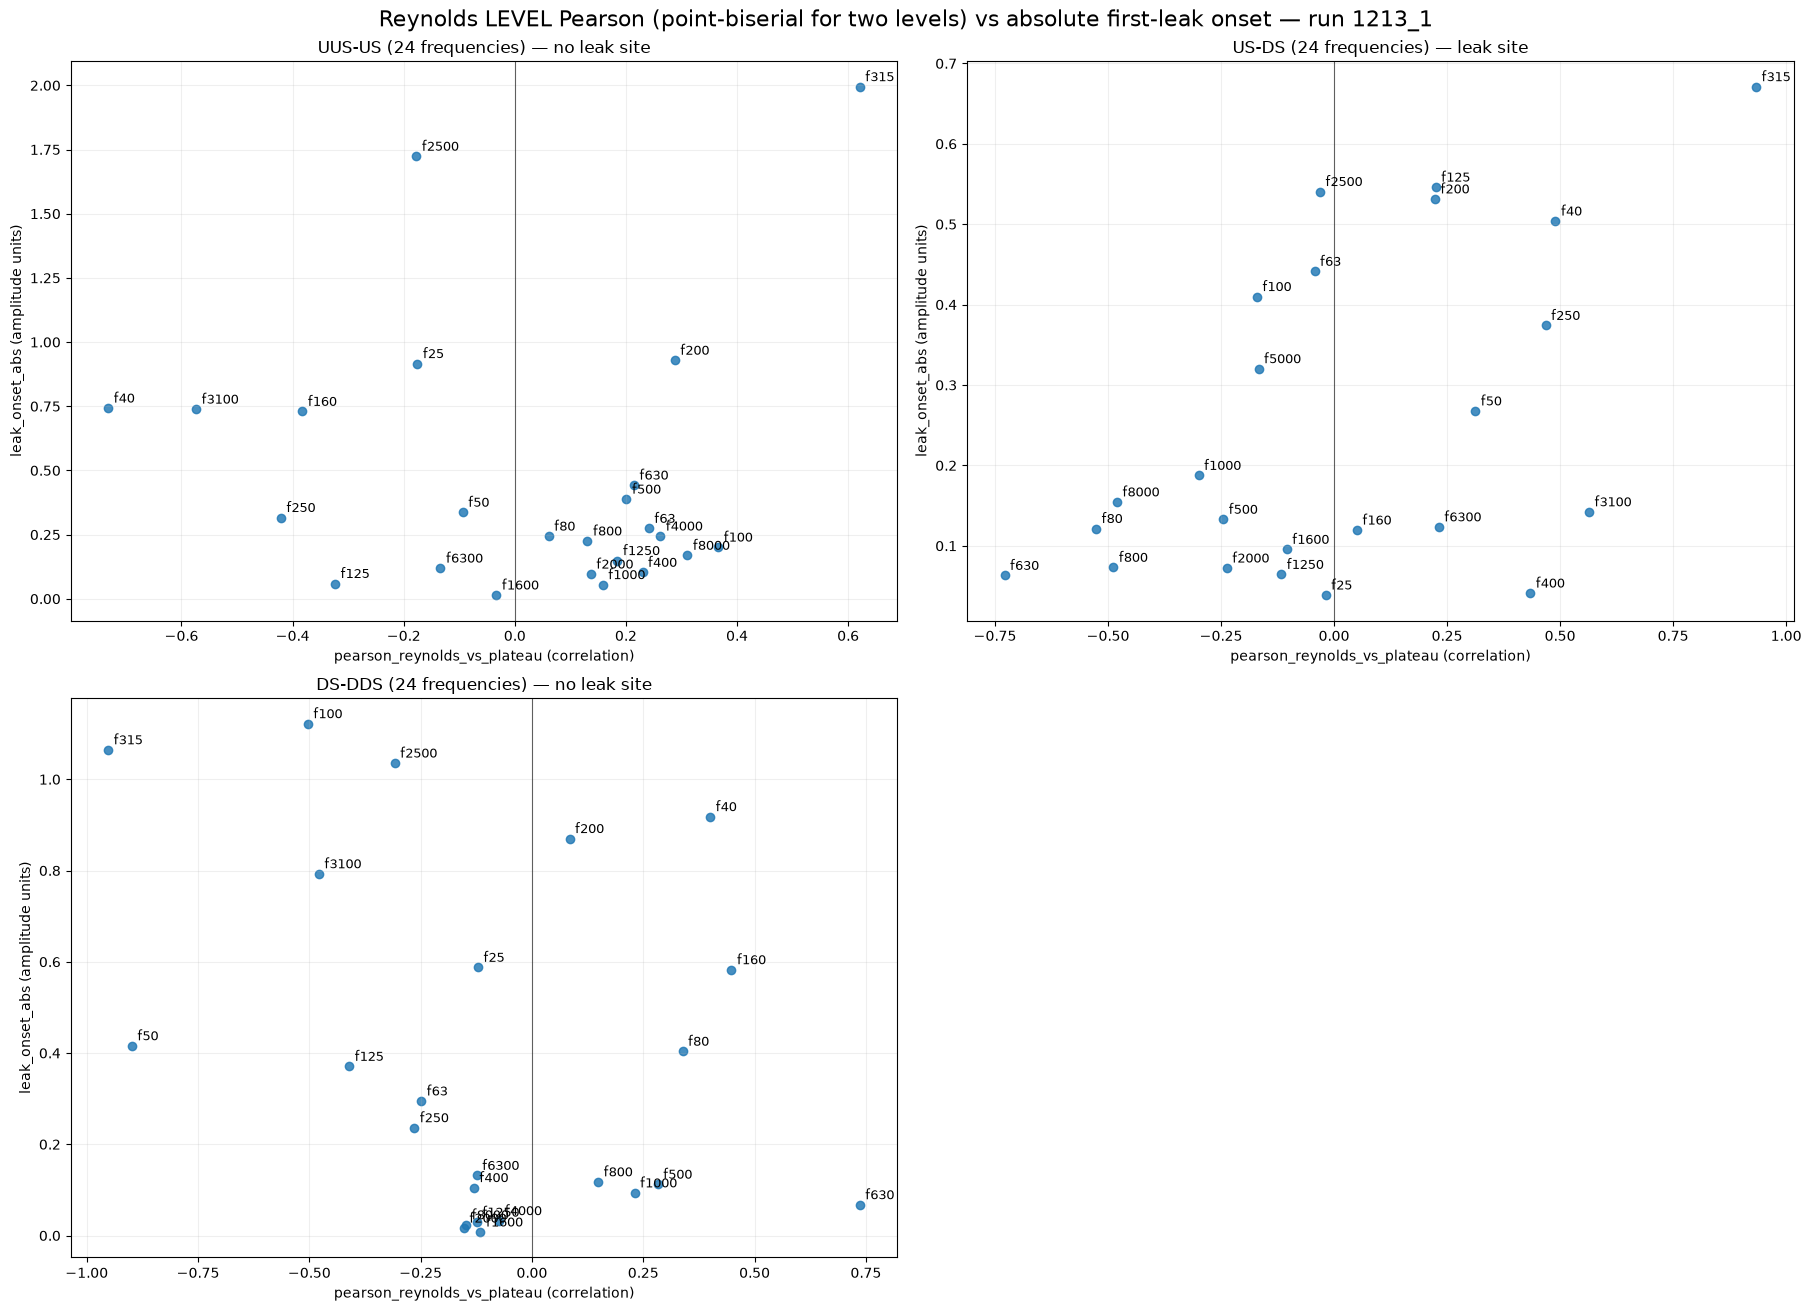

1213_1: level_pearson_vs_absolute_leak_onset → 72 frequency points


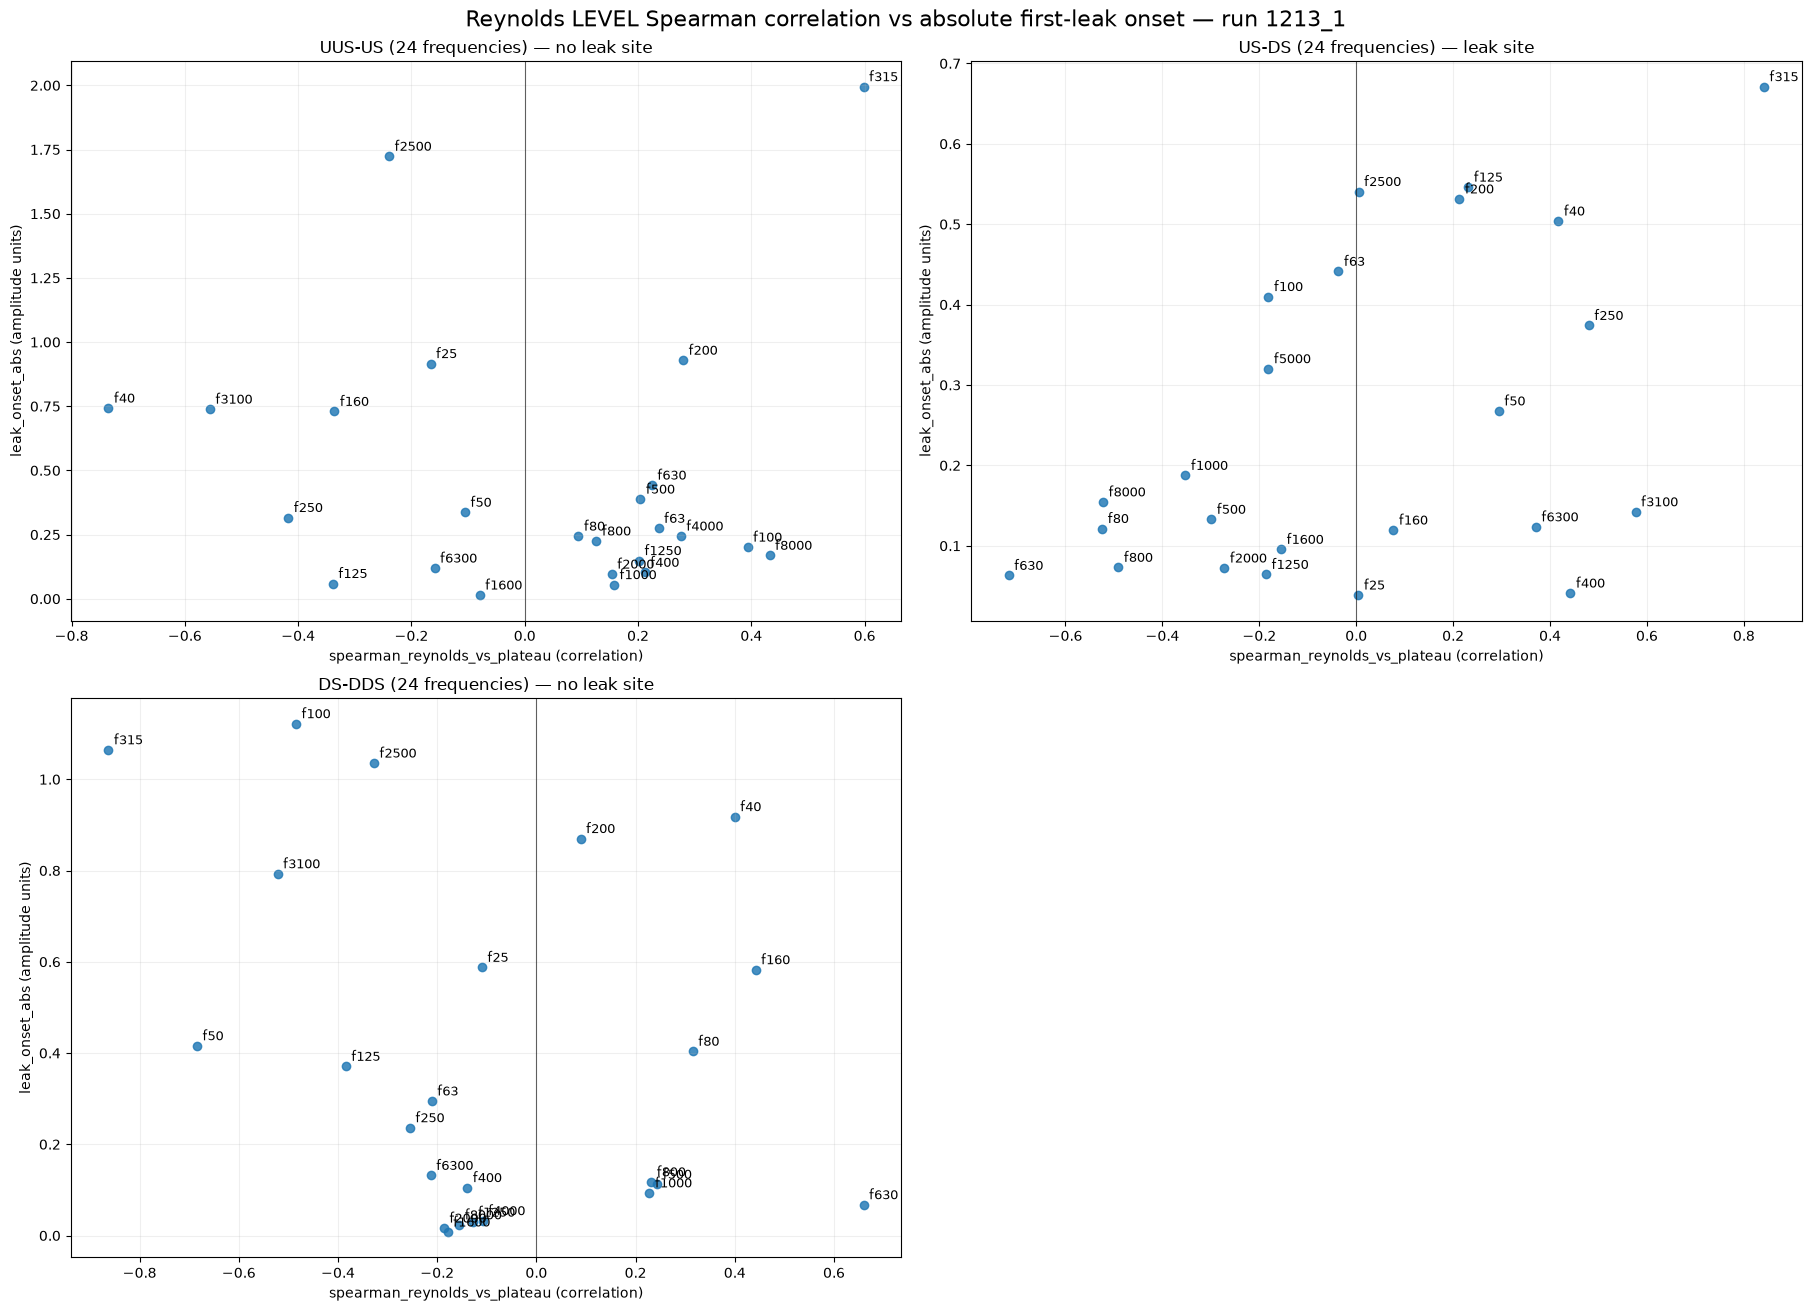

1213_1: level_spearman_vs_absolute_leak_onset → 72 frequency points


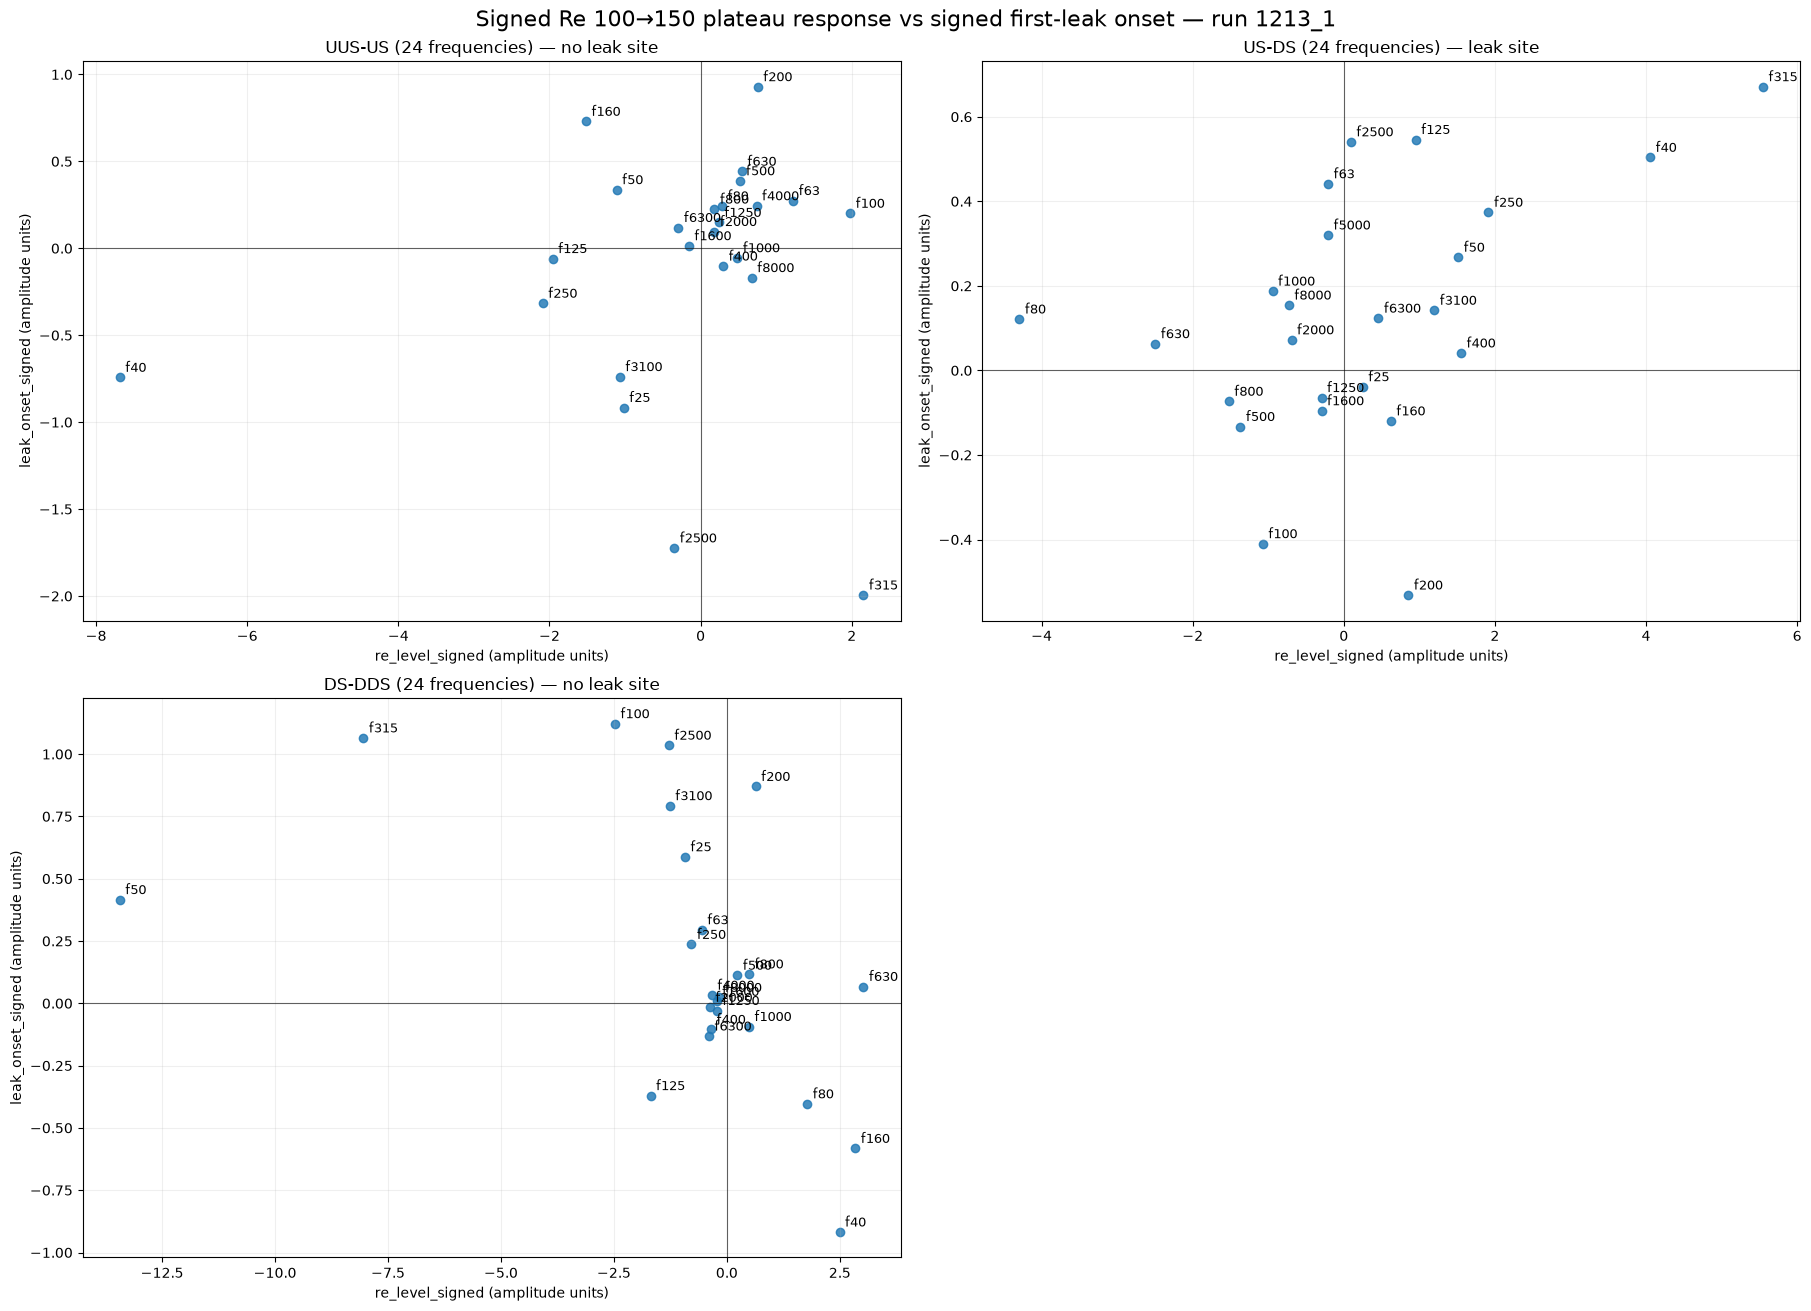

1213_1: signed_re100to150_vs_signed_leak_onset → 72 frequency points


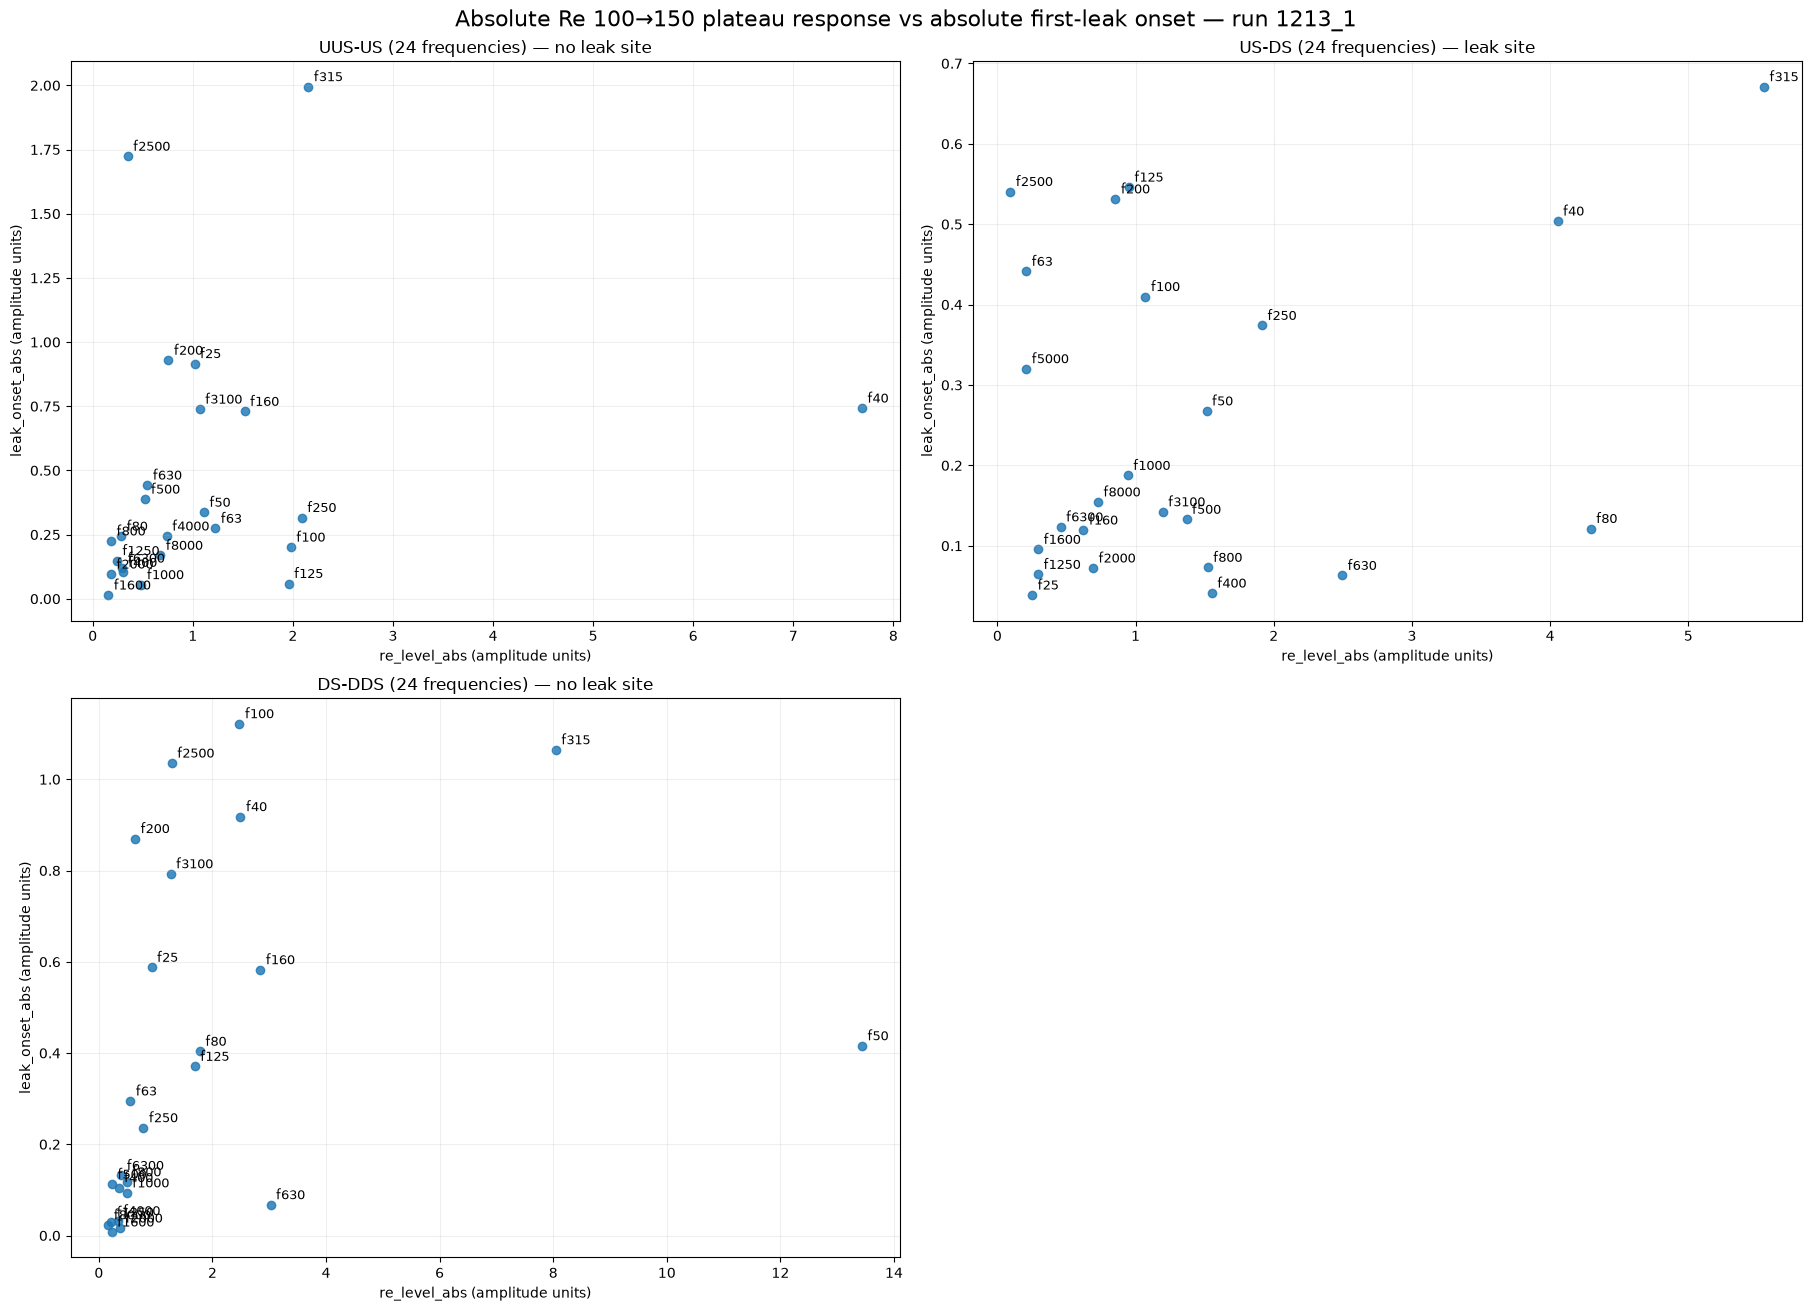

1213_1: absolute_re100to150_vs_absolute_leak_onset → 72 frequency points


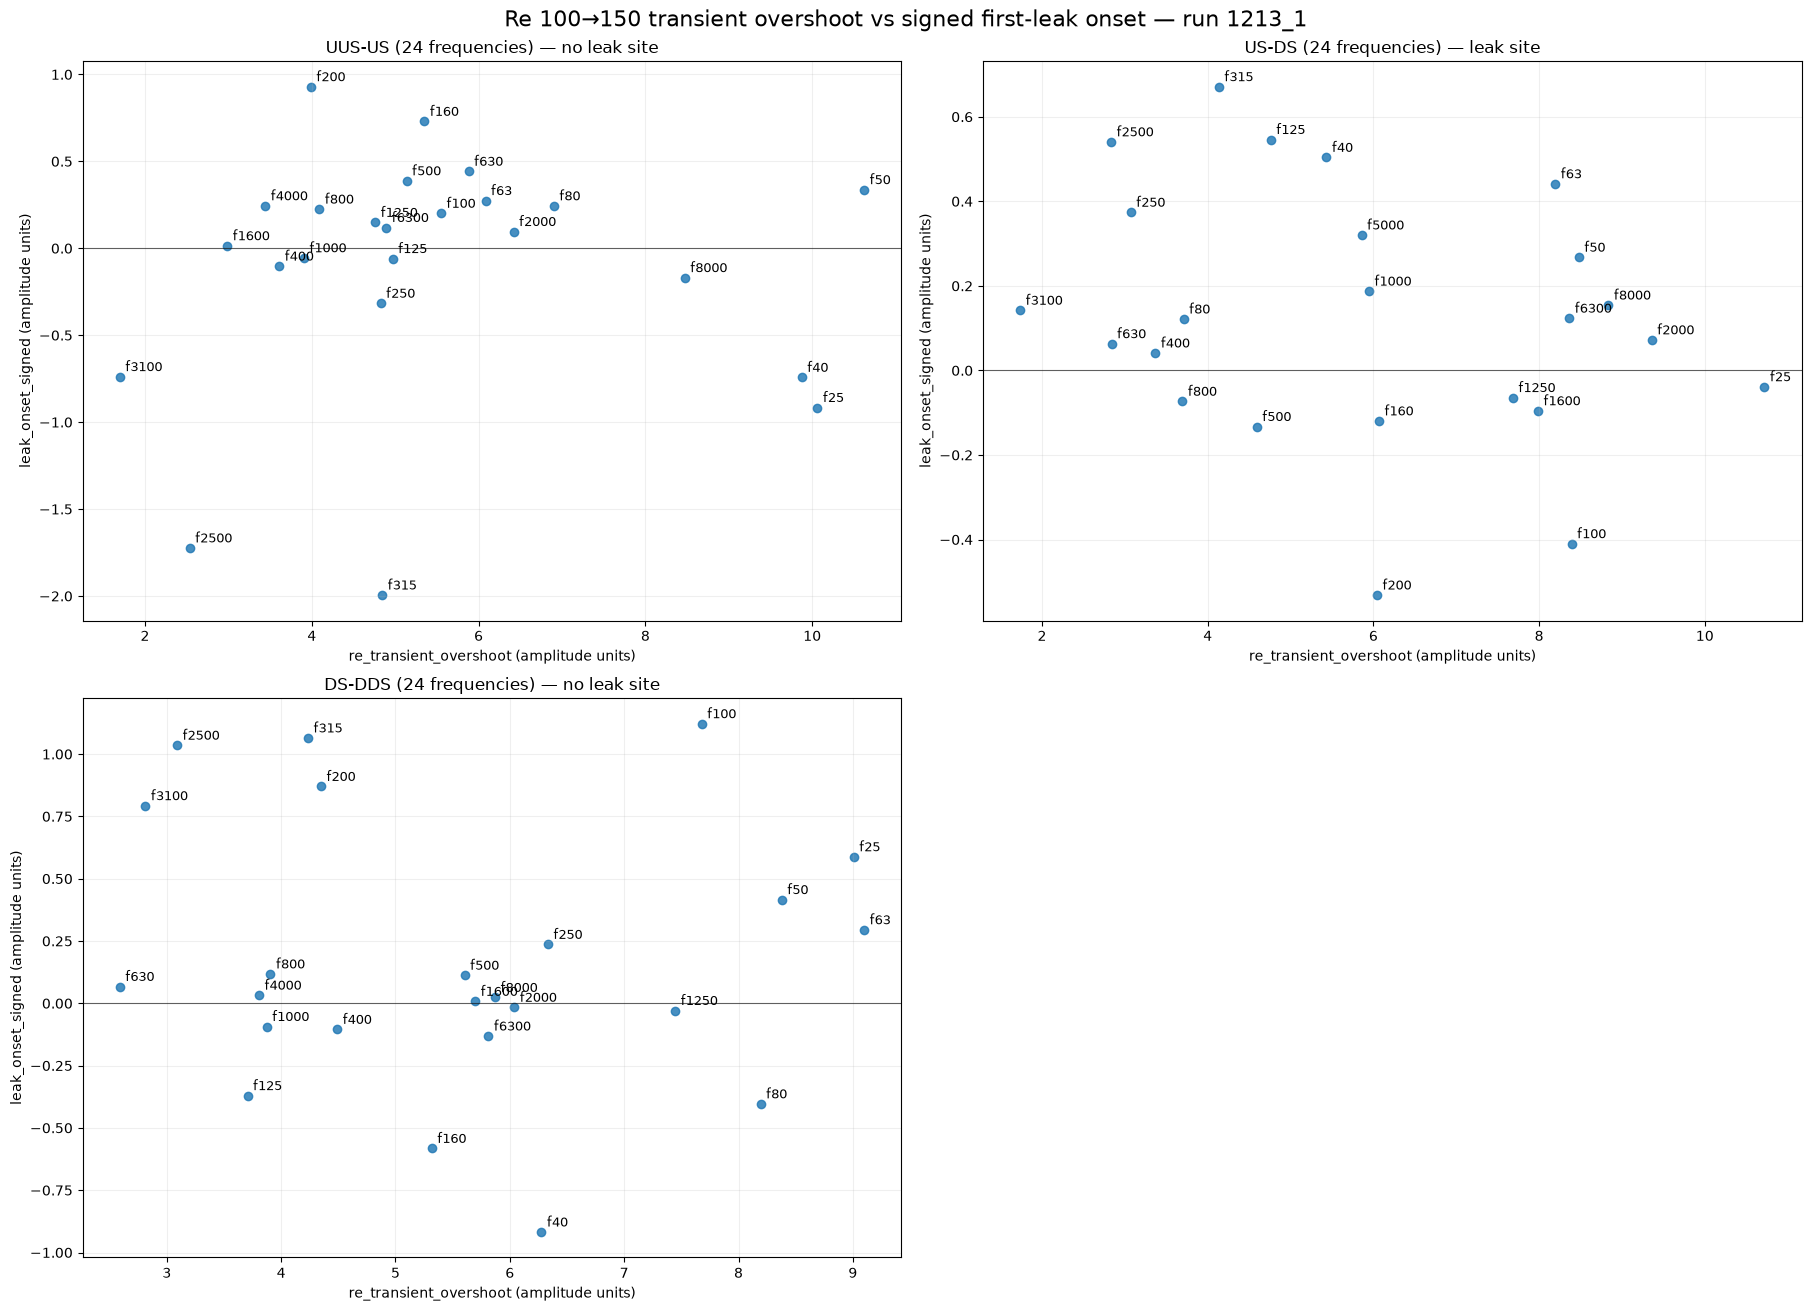

1213_1: overshoot_re100to150_vs_signed_leak_onset → 72 frequency points


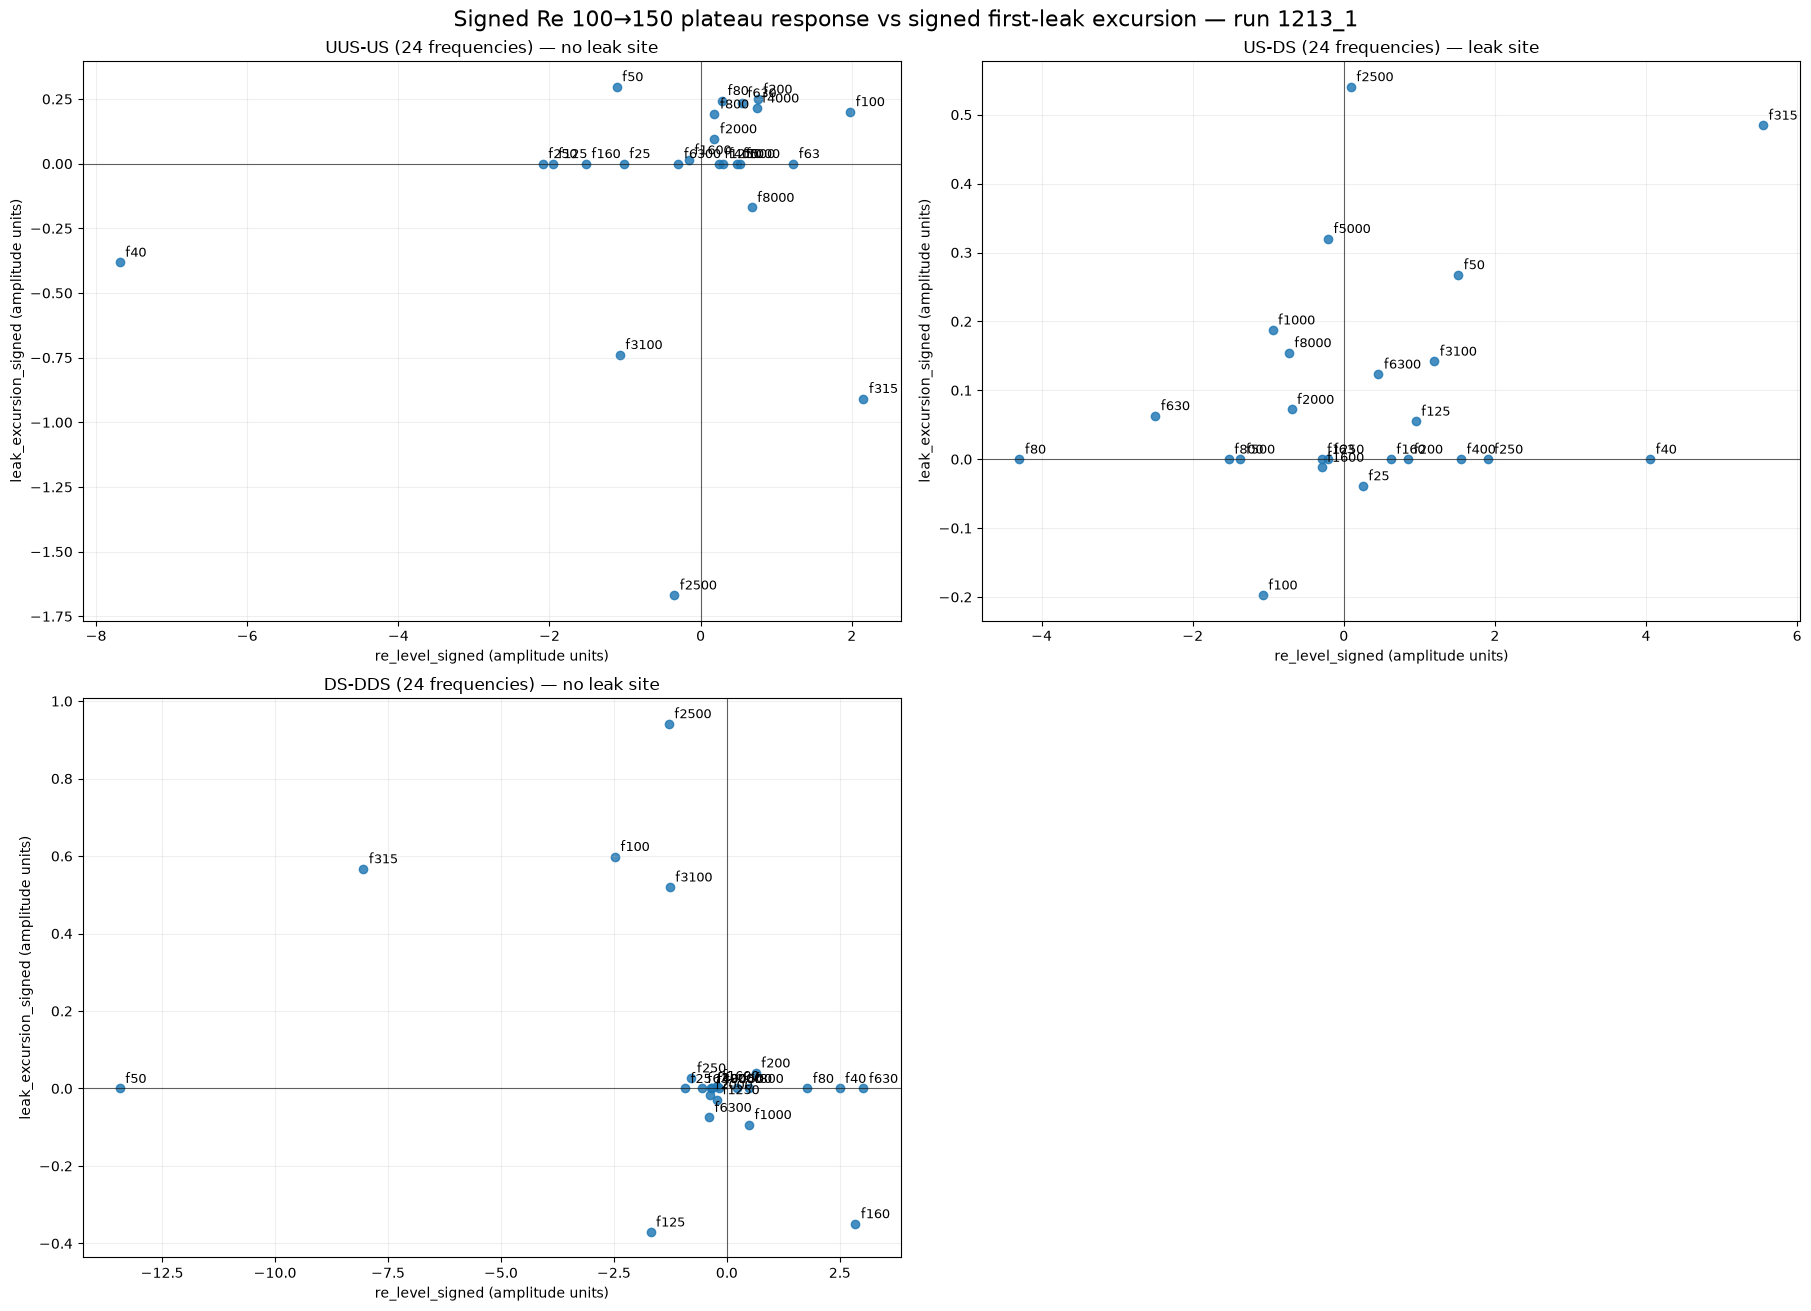

1213_1: signed_re100to150_vs_signed_leak_excursion → 72 frequency points


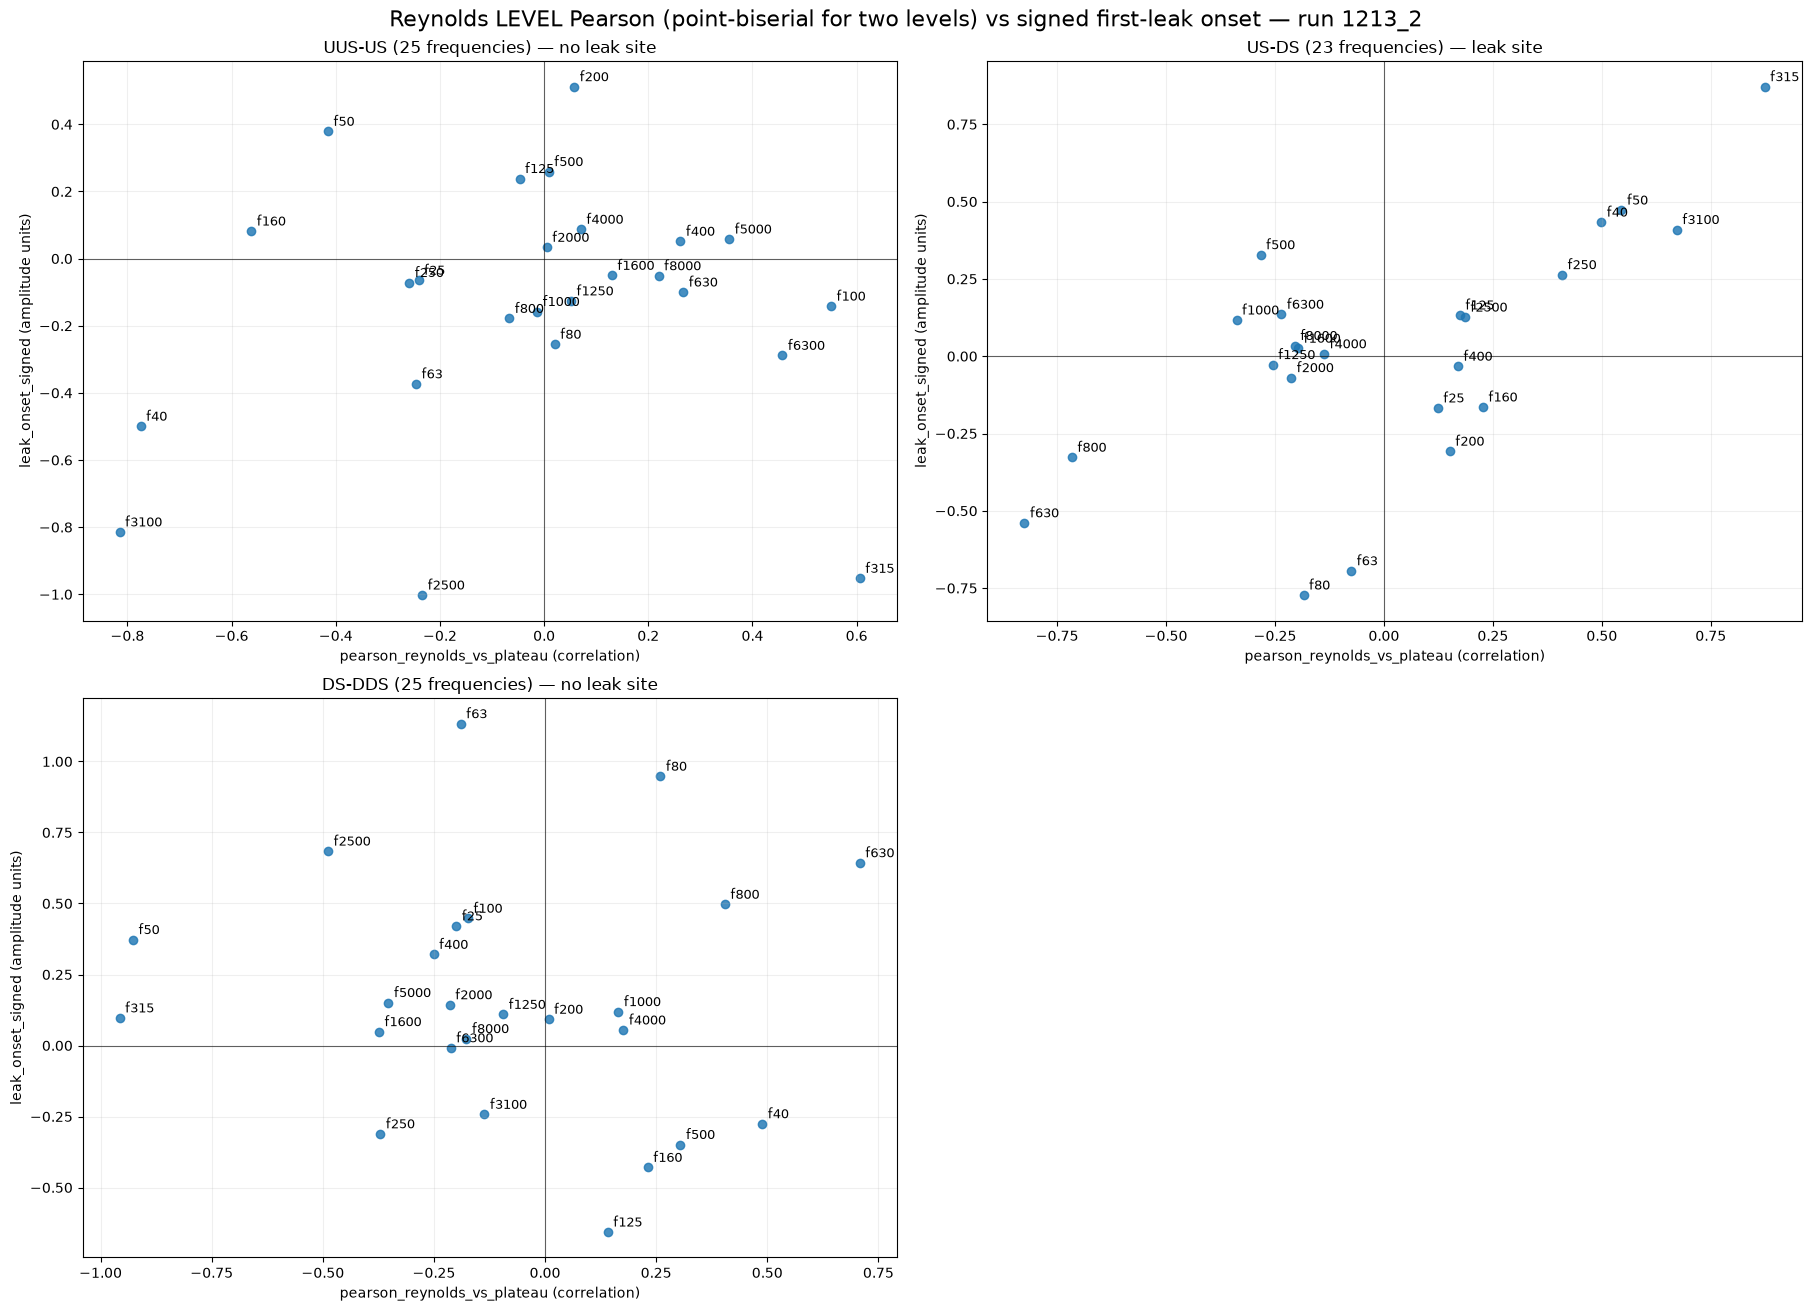

1213_2: level_pearson_vs_signed_leak_onset → 73 frequency points


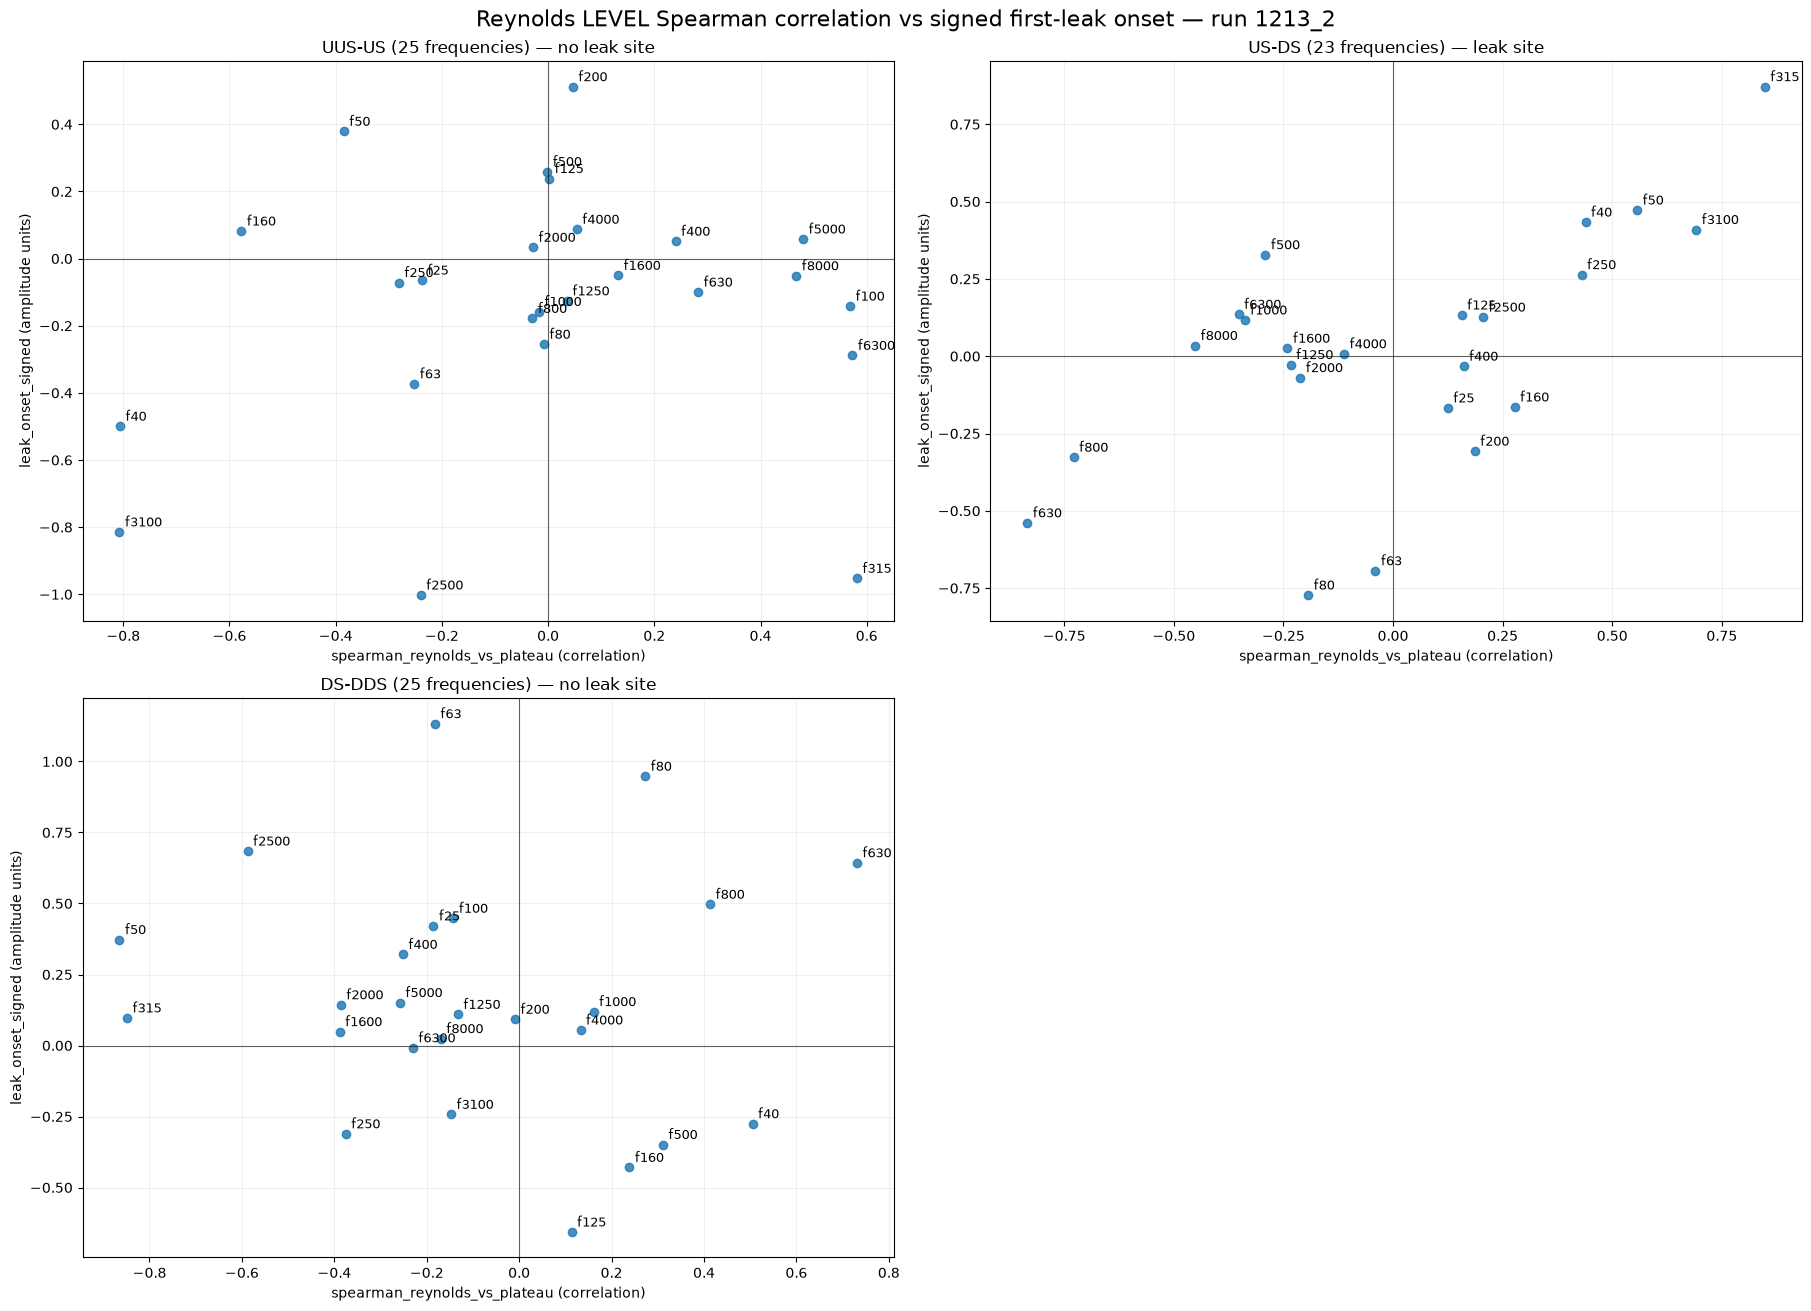

1213_2: level_spearman_vs_signed_leak_onset → 73 frequency points


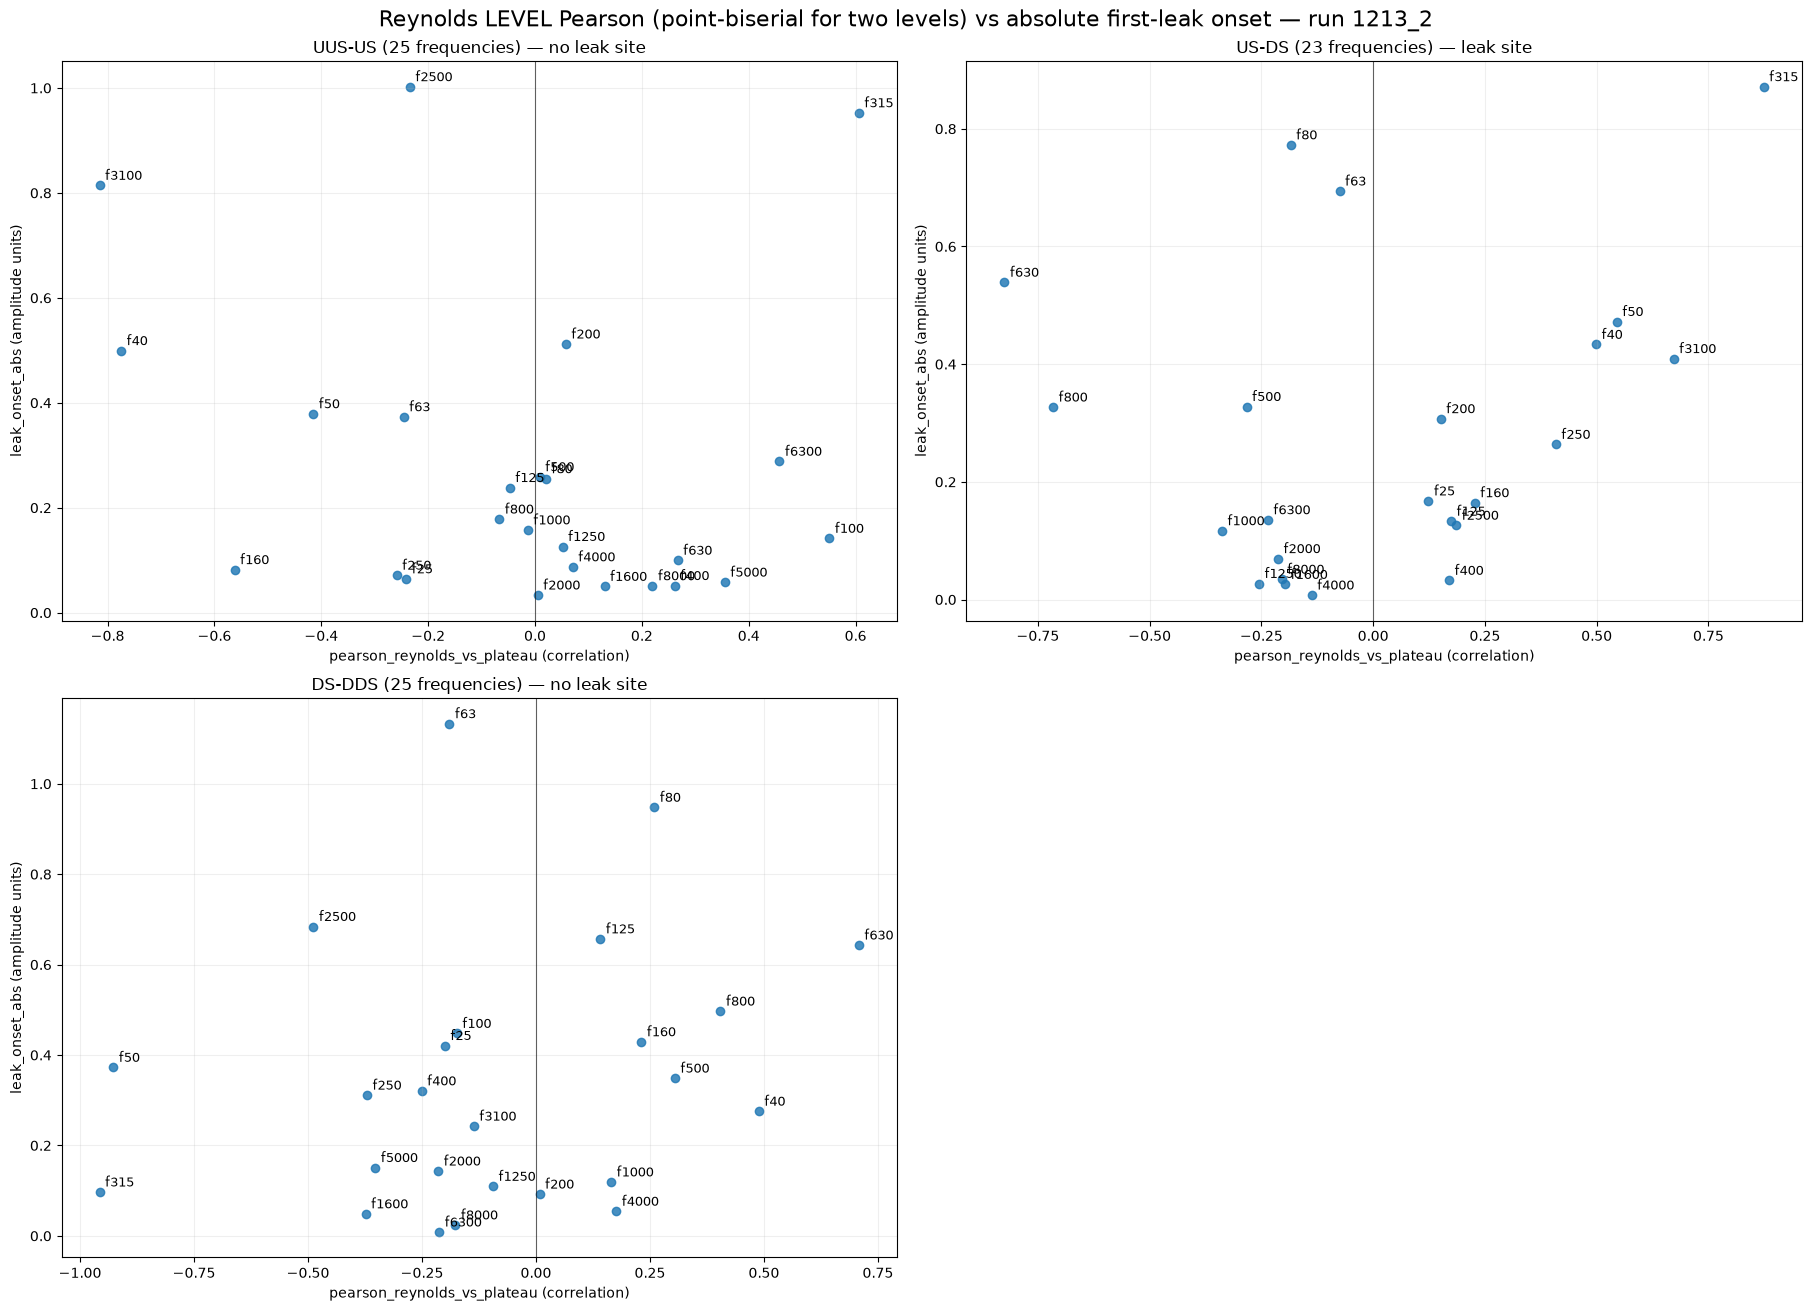

1213_2: level_pearson_vs_absolute_leak_onset → 73 frequency points


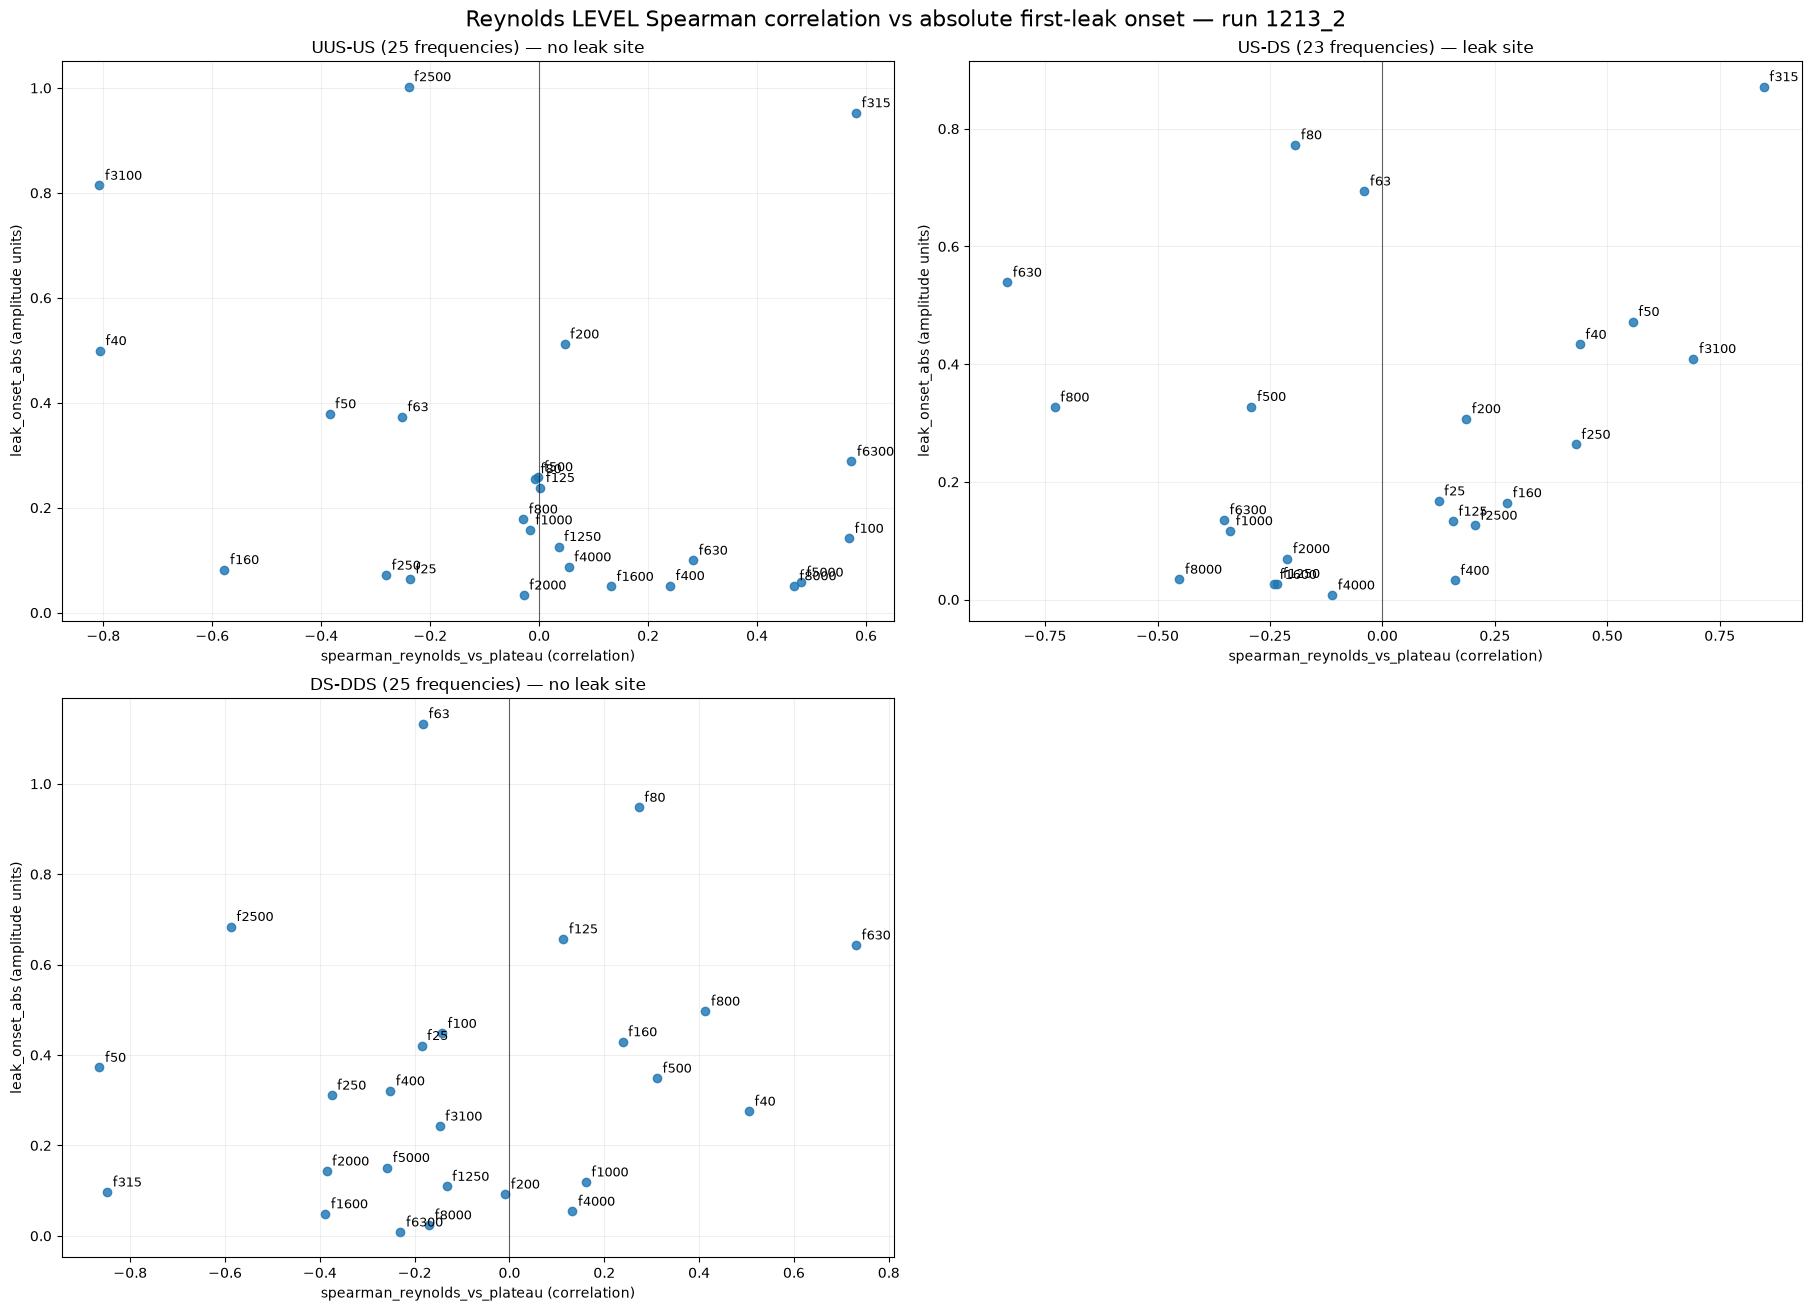

1213_2: level_spearman_vs_absolute_leak_onset → 73 frequency points


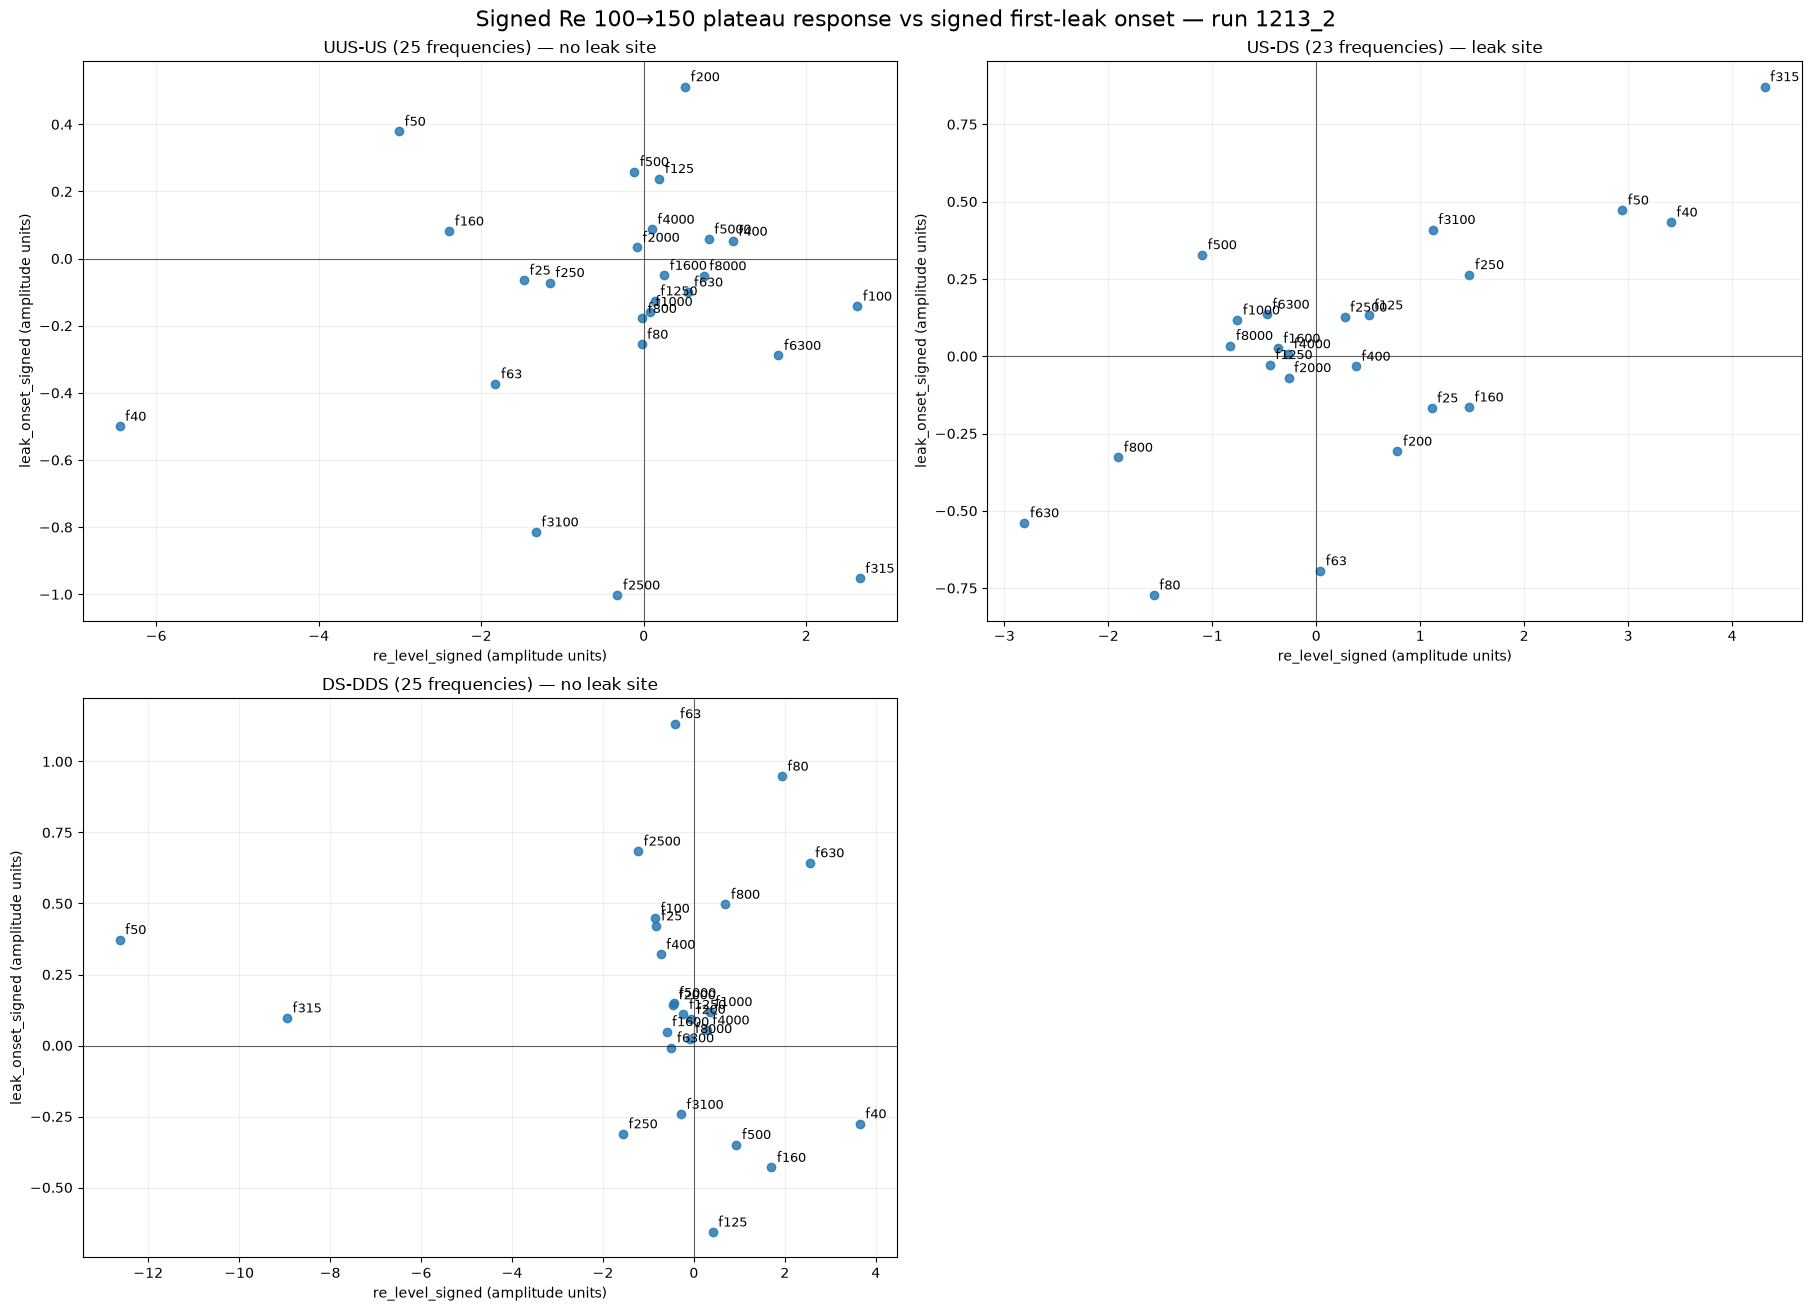

1213_2: signed_re100to150_vs_signed_leak_onset → 73 frequency points


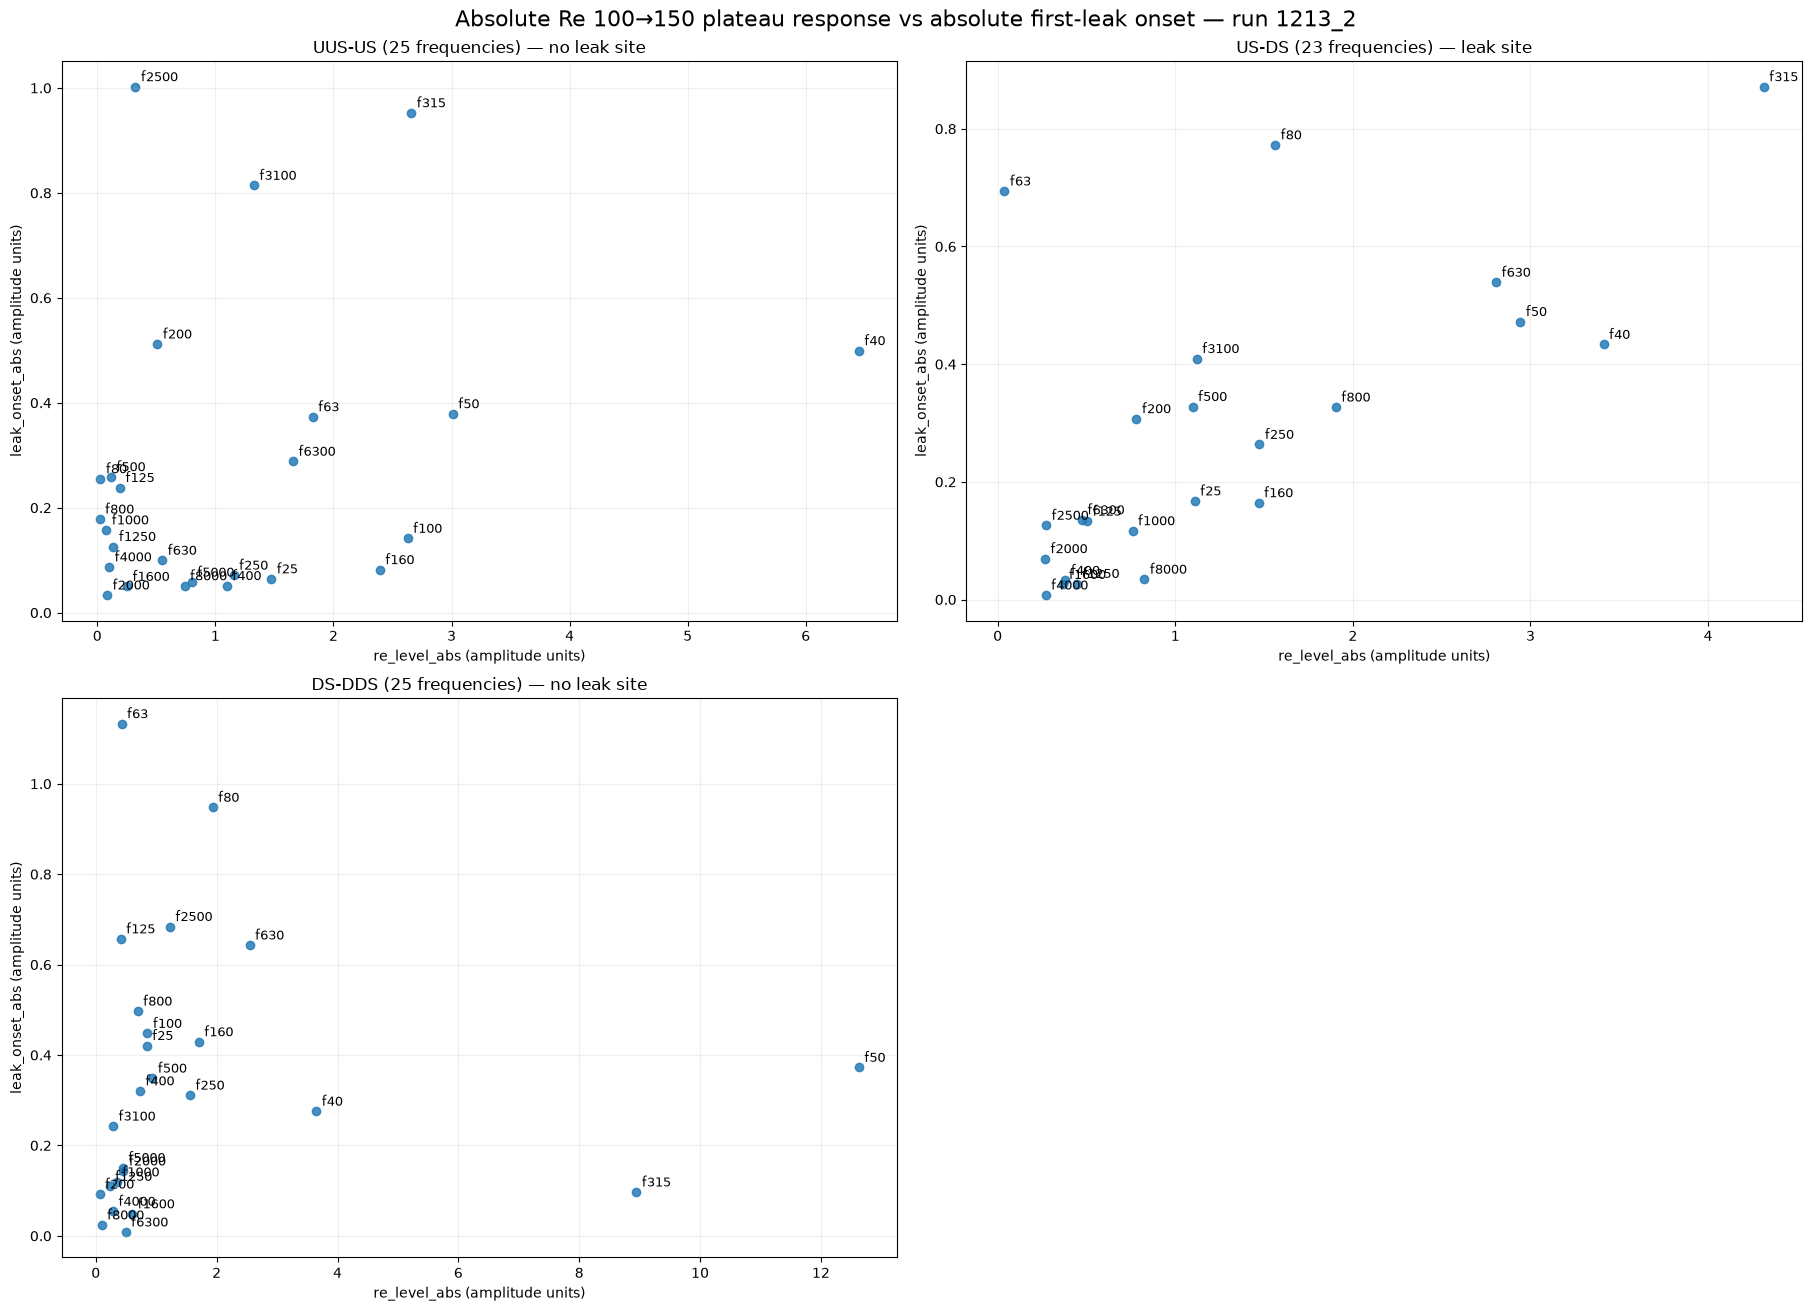

1213_2: absolute_re100to150_vs_absolute_leak_onset → 73 frequency points


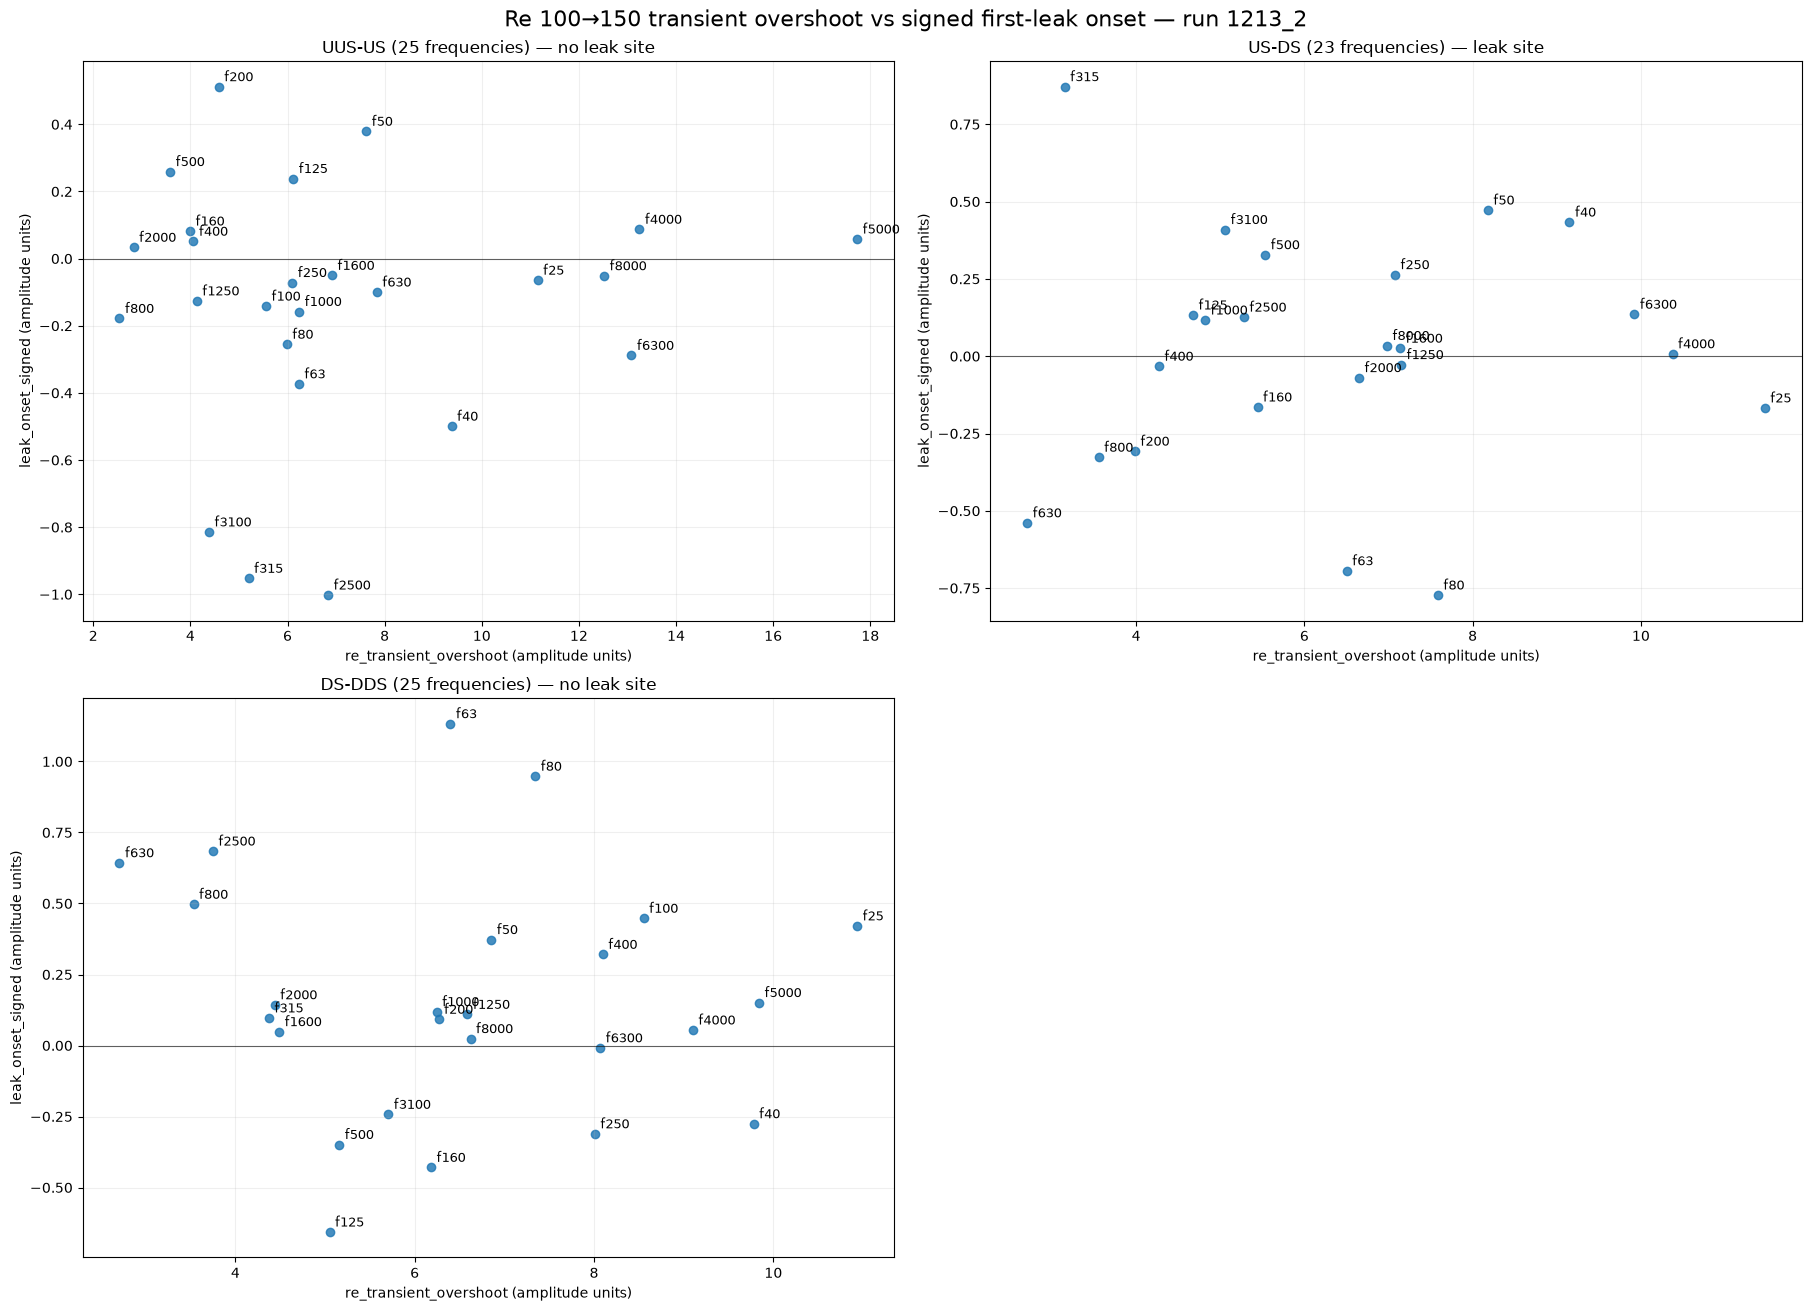

1213_2: overshoot_re100to150_vs_signed_leak_onset → 73 frequency points


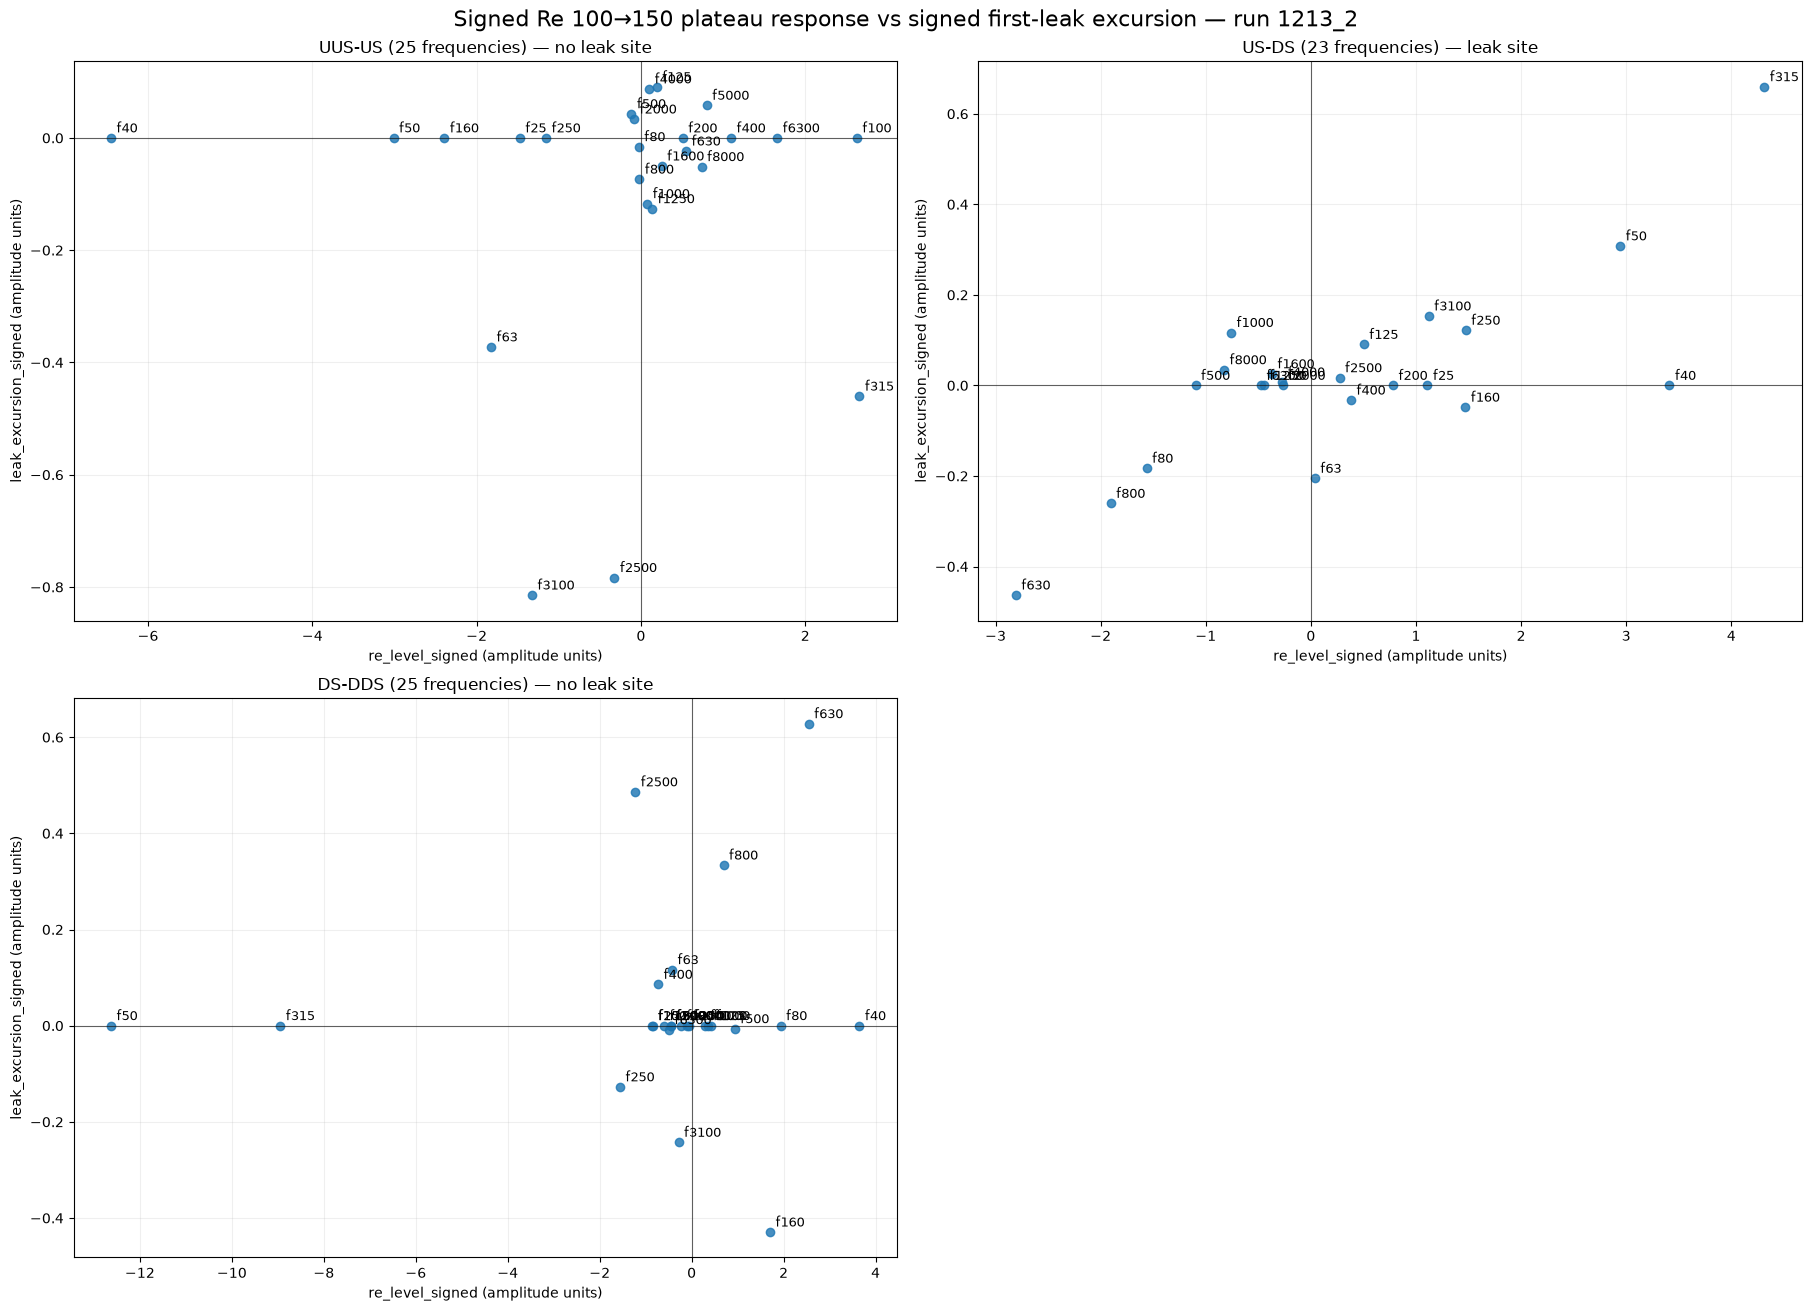

1213_2: signed_re100to150_vs_signed_leak_excursion → 73 frequency points


In [23]:
PLOT_PAIRS=[
    ('pearson_reynolds_vs_plateau','leak_onset_signed',
     'Reynolds LEVEL Pearson (point-biserial for two levels) vs signed first-leak onset',
     'level_pearson_vs_signed_leak_onset'),
    ('spearman_reynolds_vs_plateau','leak_onset_signed',
     'Reynolds LEVEL Spearman correlation vs signed first-leak onset',
     'level_spearman_vs_signed_leak_onset'),
    ('pearson_reynolds_vs_plateau','leak_onset_abs',
     'Reynolds LEVEL Pearson (point-biserial for two levels) vs absolute first-leak onset',
     'level_pearson_vs_absolute_leak_onset'),
    ('spearman_reynolds_vs_plateau','leak_onset_abs',
     'Reynolds LEVEL Spearman correlation vs absolute first-leak onset',
     'level_spearman_vs_absolute_leak_onset'),
    ('re_level_signed','leak_onset_signed',
     'Signed Re 100→150 plateau response vs signed first-leak onset',
     'signed_re100to150_vs_signed_leak_onset'),
    ('re_level_abs','leak_onset_abs',
     'Absolute Re 100→150 plateau response vs absolute first-leak onset',
     'absolute_re100to150_vs_absolute_leak_onset'),
    ('re_transient_overshoot','leak_onset_signed',
     'Re 100→150 transient overshoot vs signed first-leak onset',
     'overshoot_re100to150_vs_signed_leak_onset'),
    ('re_level_signed','leak_excursion_signed',
     'Signed Re 100→150 plateau response vs signed first-leak excursion',
     'signed_re100to150_vs_signed_leak_excursion')
]
plot_rows=[]
for run,g in comparison.groupby('run_id',sort=True):
    for xkey,ykey,title,basename in PLOT_PAIRS:
        fig,axes=plt.subplots(2,2,figsize=(18,13),layout='constrained')
        total=0
        for ax,segment in zip(axes.ravel(),SEGMENTS):
            valid_pair = (g.leak_onset_available & g[xkey].notna()
                          if xkey in ('spearman_reynolds_vs_plateau',
                                      'pearson_reynolds_vs_plateau') else g.matched_for_plot)
            d=g.loc[g.segment_id.eq(segment) & valid_pair,
                    ['frequency',xkey,ykey]].dropna()
            total+=len(d)
            ax.scatter(d[xkey],d[ykey],alpha=0.82)
            for _,r in d.iterrows():
                ax.annotate(r.frequency,(r[xkey],r[ykey]),fontsize=9,
                            xytext=(4,4),textcoords='offset points')
            if 'signed' in ykey:
                ax.axhline(0,color='black',linewidth=0.8,alpha=0.6)
            if xkey in ('re_level_signed','spearman_reynolds_vs_plateau',
                         'pearson_reynolds_vs_plateau'):
                ax.axvline(0,color='black',linewidth=0.8,alpha=0.6)
            ax.set_title(f'{segment} ({len(d)} frequencies)'+
                         (' — leak site' if segment=='US-DS' else ' — no leak site'))
            ax.set_xlabel(xkey+(' (correlation)' if xkey in ('spearman_reynolds_vs_plateau',
                                      'pearson_reynolds_vs_plateau') else ' (amplitude units)'),fontsize=10)
            ax.set_ylabel(ykey+' (amplitude units)',fontsize=10)
            ax.grid(alpha=0.2)
        for ax in axes.ravel()[len(SEGMENTS):]: ax.axis('off')
        fig.suptitle(f'{title} — run {run}',fontsize=16)
        target=PLOTS/f'{basename}__{run}.png'
        fig.savefig(target,dpi=150,bbox_inches='tight')
        plt.show()
        plt.close(fig)
        plot_rows.append({'run_id':run,'plot':basename,'points':total,'file':str(target)})
        print(f'{run}: {basename} → {total} frequency points')
plot_manifest=pd.DataFrame(plot_rows)
plot_manifest.to_csv(OUT/'scatterplot_manifest.csv',index=False)

## Interpretation, limitations, and verification

- **Part 1 — LEVEL:** read the accepted plateau medians for transitions and the within-run/segment Spearman and Pearson associations calculated from individual measurements in the accepted settled windows. **Part 1 — CHANGE:** inspect signed 100→150 plateau changes and transient overshoot independently. A high Spearman magnitude means a *monotonic* association across accepted healthy plateaus, not that every step has the same size or sign. Examine individual transitions, especially 100→150, independently. An unavailable plateau is **missing**, not a zero Reynolds effect.
- **Part 2:** signed `L−B` captures direction at leak onset; signed excursion checks whether L lies outside both healthy reference medians. A missing after-phase leaves excursion missing, but not leak onset.
- **Part 3:** signed scatterplots can show opposite event directions; absolute scatterplots show magnitudes but conceal sign. A feature can respond to leaks even when its physical segment does **not** contain the known leak. Scatterplots are **descriptive**, not validated detector performance or causal DiD.

**Change log:** New notebook only; input dataset and prior notebooks remain unchanged. Existing healthy-plateau parameters, first-leak phase definitions, signed segment differences, and transient-overshoot definition are reused. Added per-run + per-segment Reynolds association, per-run + per-segment leak response, and paired exact 100→150-versus-leak plots. No combined score, cross-run aggregation, or new inference tests.

**Current revision change log:** Default `REYNOLDS=[]` permits all healthy Reynolds levels for correlations; preserve an optional input filter when explicitly set. Add a visible per-run/frequency Spearman correlation table with all three segments plus signed mean and maximum. Retain 100→150 as a separate matched Reynolds-change analysis. Add Reynolds-LEVEL-versus-leak plots, and include level correlation, 100→150 change, and leak onset side by side in the combined table. The original plateau criteria and phase definitions are unchanged.


**Binary-level correlation fix change log:** Kept Spearman and all existing plateau detection, signed Reynolds-change, leak, and matched comparison calculations unchanged. An earlier version added Pearson correlation on accepted plateau medians (now superseded by the settled-window correlation fix), labeled point-biserial for exactly two Reynolds levels; added side-by-side segment pivot, comparison column, and Pearson-vs-leak plots. `REYNOLDS` default set to `[100,150]` as requested. No raw acoustic measurements are averaged across segments.

**Pre-first-leak boundary fix:** The first leak is determined per `run_id` on the full input *before* applying `REYNOLDS`. Part 1 excludes all measurements from the first leak onward, even if `leak_active=False` later. Part 2, Part 3 plotting, correlations, and plateau stability calculations otherwise retain their original logic. Assertions verify that no Part 1 plateau or Reynolds transition extends to/after the first leak.


**Settled-window correlation fix:** Pearson and Spearman now use all timestamp-level acoustic observations within each *already accepted*, pre-first-leak settled plateau window, instead of one plateau median per Reynolds level. The original plateau acceptance, 100→150 plateau-median transition, transient overshoot, first-leak onset, comparisons, and plots remain unchanged. The new display section shows `ranked1.head(3)` for each of the five specified runs. Correlations are descriptive because settled time observations are serially correlated.


In [ ]:
# Final consistency checks; these should fail explicitly if a join mixes experiments/segments.
key=['run_id','segment_id','frequency']
assert not comparison.duplicated(key).any(), 'Duplicate comparison keys'
assert set(comparison['segment_id']).issubset(set(SEGMENTS))
assert comparison.loc[comparison.matched_for_plot,'from_level'].eq(100.0).all()
assert comparison.loc[comparison.matched_for_plot,'to_level'].eq(150.0).all()
assert np.allclose(comparison.loc[comparison.matched_for_plot,'re_level_abs'],
                   comparison.loc[comparison.matched_for_plot,'re_level_signed'].abs())
assert np.allclose(comparison.loc[comparison.leak_onset_available,'leak_onset_abs'],
                   comparison.loc[comparison.leak_onset_available,'leak_onset_signed'].abs())
print('Verified: unique run/segment/frequency keys; exact healthy 100→150 matches;')
print('          signed vs absolute arithmetic; and separate experiment/segment plots.')
print('Created outputs:')
for path in sorted(OUT.glob('*.csv')):
    print(' ',path.name)
print('Figure count:',len(plot_manifest))
print('Configured Reynolds levels:', 'ALL' if not REYNOLDS else REYNOLDS)
print(f'Independent Reynolds CHANGE target: {CHANGE_FROM:g}→{CHANGE_TO:g}')
assert comparison['n_distinct_reynolds_levels'].dropna().le(df.Reynolds_level.nunique()).all()
assert set(ranked1.columns).issuperset({'run_id','frequency','average_correlation','max_correlation'})
assert len(plot_manifest)==df.run_id.nunique()*len(PLOT_PAIRS)
print('Verified: level correlations and healthy 100→150 changes are distinct.')
print('Experimental results must be interpreted only after running on real all_segments.csv.')
# Verify both LEVEL methods are present and neither is confused with CHANGE.
assert {'spearman_reynolds_vs_plateau','pearson_reynolds_vs_plateau'}.issubset(correlations.columns)
assert set(ranked_level_tables) == {'spearman', 'pearson'}
assert comparison['re_level_signed'].notna().equals(comparison['re_response_available'])
if REYNOLDS:
    assert set(df['Reynolds_level'].unique()).issubset(set(REYNOLDS))
print('Verified: independent Spearman, Pearson/point-biserial and 100→150 signed change.')

# Required baseline boundary: NO Reynolds plateau/transition may include
# observations at or after a run's first leak (including later inactive periods).
plateau_episode_end = plateaus['episode_id'].map(episodes.set_index('episode_id')['end_s'])
assert plateau_episode_end.lt(plateaus['run_id'].map(first_leak_by_run)).all(), \
       'Part 1 plateau extends into or after the first leak'
transition_end = transitions['to_episode_id'].map(episodes.set_index('episode_id')['end_s'])
assert transition_end.lt(transitions['run_id'].map(first_leak_by_run)).all(), \
       'Part 1 transition extends into or after the first leak'
print('Verified: all Part 1 Reynolds plateaus and transitions occur strictly before first leak.')
